In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [4]:

# ==============================
# CELL 4: Install Ultralytics & GPU Check
# ==============================

!pip install -q ultralytics

import torch
import ultralytics
from pathlib import Path

print("========== ENVIRONMENT CHECK ==========")

print("PyTorch Version:", torch.__version__)
print("Ultralytics Version:", ultralytics.__version__)

print("\nCUDA Available:", torch.cuda.is_available())
print("GPU Count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):

    print(f"\nGPU {i}:", torch.cuda.get_device_name(i))

    memory = torch.cuda.get_device_properties(i).total_memory

    print("GPU Memory:", round(memory / 1024**3, 2), "GB")

# Check YAML
YAML_PATH = Path("/kaggle/working/data.yaml")

print("\nData YAML exists:", YAML_PATH.exists())

assert torch.cuda.is_available(), "GPU not enabled!"
assert YAML_PATH.exists(), "Run Cell 3 again!"

print("\nEnvironment ready for YOLO training!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
========== ENVIRONMENT CHECK ==========
PyTorch Version: 2.11.0+cu130
Ultralytics Version: 8.4.211

CUDA Available: True
GPU Count: 2

GPU 0: Tesla T4
GPU Memory: 14.56 GB

GPU 1: Tesla T4
GPU Memory: 14.56 GB

Data YAML exists: True

Environment ready for YOLO training!


# 02 — Train Baseline YOLOv8n

## Aim
To train a baseline YOLOv8n model using the SGD optimizer
on the preprocessed RDD2022 dataset for road damage detection.

## Configuration
- Model: YOLOv8n
- Optimizer: SGD
- Epochs: 10
- Image Size: 640 × 640
- Batch Size: 32
- Training Images: 16,636
- Validation Images: 4,753
- Hardware: NVIDIA Tesla T4 x2

## Expected Outputs
- Trained model weights (best.pt and last.pt)
- Training and validation loss curves
- Precision, Recall, mAP50 and mAP50-95
- Training results CSV

## Step 9: Restore and Verify SGD Training Checkpoint

Restore the previously saved 16-epoch SGD training
checkpoint from the attached Kaggle backup dataset.

Verify the saved epoch number, optimizer state,
original training configuration, and GPU availability.

Restore the previous training directory to writable
Kaggle working storage while preserving the original
16-epoch backup.

Prepare the checkpoint to resume training from
epoch 17 toward the original target of 50 epochs.

In [10]:

# ==========================================
# NOTEBOOK 02 - CELL 9
# Restore and Verify SGD Checkpoint
# ==========================================

import torch
import shutil
import pandas as pd

from pathlib import Path
from ultralytics import YOLO

# ==========================================
# 1. Define Backup and Working Paths
# ==========================================

BACKUP_SOURCE = Path(

    "/kaggle/input/datasets/ammritkumaar/"
    "sgd-baseline-16-epochs-backup"
)

SOURCE_CHECKPOINT = (

    BACKUP_SOURCE / "weights" / "last.pt"
)

WORK_DIR = Path("/kaggle/working")

RUN_DIR = (

    WORK_DIR /

    "YOLO_Experiments" /

    "baseline_yolov8n_sgd-2"
)

YAML_PATH = WORK_DIR / "data.yaml"

print("========== RESTORE SETUP ==========")

print("Backup Source:", BACKUP_SOURCE)

print("Source Checkpoint:", SOURCE_CHECKPOINT)

print("Restore Directory:", RUN_DIR)

assert SOURCE_CHECKPOINT.exists()

assert YAML_PATH.exists()

assert torch.cuda.device_count() == 2

print("Source Checkpoint: VERIFIED")

print("Data YAML: VERIFIED")

print("GPU Configuration: VERIFIED")

# ==========================================
# 2. Restore Previous Training Directory
# ==========================================

# Copy all previous training outputs from
# read-only input to writable working storage.

shutil.copytree(

    BACKUP_SOURCE,

    RUN_DIR,

    dirs_exist_ok=True
)

CHECKPOINT_PATH = (

    RUN_DIR / "weights" / "last.pt"
)

BEST_MODEL_PATH = (

    RUN_DIR / "weights" / "best.pt"
)

RESULTS_PATH = RUN_DIR / "results.csv"

print("\n========== RESTORED FILES ==========")

print("Last Checkpoint:", CHECKPOINT_PATH.exists())

print("Best Checkpoint:", BEST_MODEL_PATH.exists())

print("Results CSV:", RESULTS_PATH.exists())

assert CHECKPOINT_PATH.exists()

assert BEST_MODEL_PATH.exists()

assert RESULTS_PATH.exists()

# ==========================================
# 3. Verify Previous Training Results
# ==========================================

previous_results = pd.read_csv(RESULTS_PATH)

previous_results.columns = (

    previous_results.columns.str.strip()
)

print("\n========== PREVIOUS TRAINING RESULTS ==========")

print("Completed Epoch Rows:", len(previous_results))

display(previous_results.tail(3))

assert len(previous_results) == 16

# ==========================================
# 4. Load Saved Training Checkpoint
# ==========================================

# Load only our own trusted checkpoint.

checkpoint = torch.load(

    CHECKPOINT_PATH,

    map_location="cpu",

    weights_only=False
)

saved_epoch = checkpoint.get("epoch", -1)

completed_epochs = saved_epoch + 1

optimizer_state = checkpoint.get("optimizer")

train_args = checkpoint.get("train_args", {})

target_epochs = train_args.get("epochs", 0)

print("\n========== CHECKPOINT TRAINING STATE ==========")

print("Saved Epoch Index:", saved_epoch)

print("Completed Epochs:", completed_epochs)

print("Next Training Epoch:", completed_epochs + 1)

print("Target Epochs:", target_epochs)

print(

    "Optimizer State Available:",

    optimizer_state is not None
)

print("Optimizer:", train_args.get("optimizer"))

print("Learning Rate:", train_args.get("lr0"))

print("Image Size:", train_args.get("imgsz"))

print("Batch Size:", train_args.get("batch"))

print("Momentum:", train_args.get("momentum"))

print("Weight Decay:", train_args.get("weight_decay"))

print("Cosine LR:", train_args.get("cos_lr"))

print("Original Dataset YAML:", train_args.get("data"))

print("Original Project:", train_args.get("project"))

print("Original Run Name:", train_args.get("name"))

print("Original Save Directory:", train_args.get("save_dir"))

print("Original Device:", train_args.get("device"))

# ==========================================
# 5. Verify Resume Readiness
# ==========================================

resume_ready = (

    completed_epochs == 16

    and optimizer_state is not None

    and target_epochs == 50

    and train_args.get("optimizer") == "SGD"

    and train_args.get("imgsz") == 640

    and train_args.get("batch") == 32
)

print("\n========== RESUME VERIFICATION ==========")

print("Checkpoint Resume Ready:", resume_ready)

print("Two GPUs Available:",

      torch.cuda.device_count() == 2)

print(

    "Restored Checkpoint Size:",

    round(

        CHECKPOINT_PATH.stat().st_size

        / (1024 ** 2),

        2
    ),

    "MB"
)

if resume_ready:

    print("\nSGD checkpoint successfully restored!")

    print("Completed Epochs: 16")

    print("Next Epoch: 17")

    print("Remaining Epochs: 34")

    print("Target Epochs: 50")

    print("\nReady for Cell 10 - Resume Training")

else:

    print("\nCheckpoint requires further verification.")

    print("Do not start resume training yet.")

# Release checkpoint from CPU memory
del checkpoint
del optimizer_state

print("\n========== CELL 9 COMPLETED ==========")


========== RESTORE SETUP ==========
Backup Source: /kaggle/input/datasets/ammritkumaar/sgd-baseline-16-epochs-backup
Source Checkpoint: /kaggle/input/datasets/ammritkumaar/sgd-baseline-16-epochs-backup/weights/last.pt
Restore Directory: /kaggle/working/YOLO_Experiments/baseline_yolov8n_sgd-2
Source Checkpoint: VERIFIED
Data YAML: VERIFIED
GPU Configuration: VERIFIED

========== RESTORED FILES ==========
Last Checkpoint: True
Best Checkpoint: True
Results CSV: True

========== PREVIOUS TRAINING RESULTS ==========
Completed Epoch Rows: 16


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
13,14,4002.17,1.86215,2.03669,1.69738,0.49163,0.39037,0.38923,0.17815,1.85065,1.94169,1.68490,0.008439,0.008439,0.008439
14,15,4262.68,1.85628,1.99618,1.68621,0.48796,0.39850,0.39600,0.18152,1.82640,1.91843,1.66759,0.008205,0.008205,0.008205
15,16,4522.93,1.85228,1.97263,1.67894,0.51169,0.41295,0.41924,0.19242,1.81063,1.86243,1.63545,0.007960,0.007960,0.007960



========== CHECKPOINT TRAINING STATE ==========
Saved Epoch Index: 15
Completed Epochs: 16
Next Training Epoch: 17
Target Epochs: 50
Optimizer State Available: True
Optimizer: SGD
Learning Rate: 0.01
Image Size: 640
Batch Size: 32
Momentum: 0.937
Weight Decay: 0.0005
Cosine LR: True
Original Dataset YAML: /kaggle/working/data.yaml
Original Project: /kaggle/working/YOLO_Experiments
Original Run Name: baseline_yolov8n_sgd-2
Original Save Directory: /kaggle/working/YOLO_Experiments/baseline_yolov8n_sgd-2
Original Device: 0,1

========== RESUME VERIFICATION ==========
Checkpoint Resume Ready: True
Two GPUs Available: True
Restored Checkpoint Size: 12.26 MB

SGD checkpoint successfully restored!
Completed Epochs: 16
Next Epoch: 17
Remaining Epochs: 34
Target Epochs: 50

Ready for Cell 10 - Resume Training

========== CELL 9 COMPLETED ==========


## Step 10: Resume SGD Training from Epoch 17 to 50

Resume the previously trained YOLOv8n baseline model
using the saved last.pt checkpoint.

The model has already completed 16 training epochs.

Continue training toward the original target of
50 epochs while preserving:

- Previously learned model weights
- SGD optimizer state
- Original learning rate configuration
- Cosine learning rate schedule
- Original dataset and image size
- Original batch size and training configuration
- Previous training history

Use the restored checkpoint to continue training
from epoch 17 instead of restarting from epoch 1.

Save the updated model checkpoints, training metrics,
and performance plots for subsequent optimizer
comparison and validation evaluation.

The original 16-epoch backup remains preserved
in the attached Kaggle backup dataset.

In [11]:

# ==========================================
# NOTEBOOK 02 - CELL 10
# Resume SGD Training: Epoch 17 to 50
# ==========================================

import time
import torch
import pandas as pd

from pathlib import Path
from ultralytics import YOLO

# ==========================================
# 1. Verify Resume Requirements
# ==========================================

print("========== RESUME TRAINING SETUP ==========")

assert resume_ready, (
    "Checkpoint is not ready for resume training!"
)

assert CHECKPOINT_PATH.exists()

assert YAML_PATH.exists()

assert torch.cuda.device_count() == 2

print("Checkpoint:", CHECKPOINT_PATH)

print("Dataset YAML:", YAML_PATH)

print("GPU Count:", torch.cuda.device_count())

print("GPU 0:", torch.cuda.get_device_name(0))

print("GPU 1:", torch.cuda.get_device_name(1))

# ==========================================
# 2. Verify Existing Training History
# ==========================================

existing_results = pd.read_csv(RESULTS_PATH)

existing_results.columns = (

    existing_results.columns.str.strip()
)

completed_epochs = int(

    existing_results["epoch"].iloc[-1]
)

print("\n========== PREVIOUS TRAINING STATUS ==========")

print("Completed Epochs:", completed_epochs)

print("Next Epoch:", completed_epochs + 1)

print("Target Epochs:", 50)

print("Remaining Epochs:", 50 - completed_epochs)

assert completed_epochs == 16

print(

    "Previous mAP50:",

    round(

        existing_results["metrics/mAP50(B)"].iloc[-1]

        * 100,

        2
    ),

    "%"
)

print(

    "Previous mAP50-95:",

    round(

        existing_results["metrics/mAP50-95(B)"].iloc[-1]

        * 100,

        2
    ),

    "%"
)

# ==========================================
# 3. Load Saved Training Checkpoint
# ==========================================

print("\n========== LOADING SGD CHECKPOINT ==========")

model = YOLO(str(CHECKPOINT_PATH))

print("Saved SGD checkpoint loaded successfully!")

# ==========================================
# 4. Resume Original Training
# ==========================================

print("\n========== RESUMING TRAINING ==========")

print("Model: YOLOv8n")

print("Optimizer: SGD")

print("Completed Epochs: 16")

print("Starting Epoch: 17")

print("Target Epochs: 50")

print("Remaining Epochs: 34")

print("Image Size: 640")

print("Batch Size: 32")

print("GPU: Tesla T4 x 2")

print("\nStarting resume training...\n")

start_time = time.time()

# Resume using original saved configuration
# Do not initialize a new pretrained model

results = model.train(

    resume=True,

    device=[0, 1]
)

# ==========================================
# 5. Calculate Resume Training Duration
# ==========================================

resume_training_time = (

    time.time() - start_time
)

print("\n========== RESUME TRAINING FINISHED ==========")

print(

    "Resume Training Time (minutes):",

    round(resume_training_time / 60, 2)
)

print(

    "Resume Training Time (hours):",

    round(resume_training_time / 3600, 2)
)

# ==========================================
# 6. Verify Updated Training Results
# ==========================================

updated_results = pd.read_csv(RESULTS_PATH)

updated_results.columns = (

    updated_results.columns.str.strip()
)

final_completed_epochs = int(

    updated_results["epoch"].iloc[-1]
)

print("\n========== UPDATED TRAINING RESULTS ==========")

print(

    "Total Completed Epochs:",

    final_completed_epochs
)

print(

    "Total Training Result Rows:",

    len(updated_results)
)

print("\nLast 5 Epochs:")

display(updated_results.tail(5))

# ==========================================
# 7. Identify Best Validation Epoch
# ==========================================

best_index = updated_results[

    "metrics/mAP50-95(B)"

].idxmax()

best_epoch = updated_results.loc[best_index]

print("\n========== BEST VALIDATION PERFORMANCE ==========")

print("Best Epoch:", int(best_epoch["epoch"]))

print(

    "Precision:",

    round(

        best_epoch["metrics/precision(B)"] * 100,

        2
    ),

    "%"
)

print(

    "Recall:",

    round(

        best_epoch["metrics/recall(B)"] * 100,

        2
    ),

    "%"
)

print(

    "mAP50:",

    round(

        best_epoch["metrics/mAP50(B)"] * 100,

        2
    ),

    "%"
)

print(

    "mAP50-95:",

    round(

        best_epoch["metrics/mAP50-95(B)"] * 100,

        2
    ),

    "%"
)

# ==========================================
# 8. Verify Updated Model Checkpoints
# ==========================================

print("\n========== CHECKPOINT VERIFICATION ==========")

print("Training Directory:", RUN_DIR)

print("Best Model:", BEST_MODEL_PATH)

print("Best Model Exists:", BEST_MODEL_PATH.exists())

print("Last Model:", CHECKPOINT_PATH)

print("Last Model Exists:", CHECKPOINT_PATH.exists())

print("Results CSV Exists:", RESULTS_PATH.exists())

assert BEST_MODEL_PATH.exists()

assert CHECKPOINT_PATH.exists()

assert RESULTS_PATH.exists()

print("\n========== CELL 10 COMPLETED ==========")


========== RESUME TRAINING SETUP ==========
Checkpoint: /kaggle/working/YOLO_Experiments/baseline_yolov8n_sgd-2/weights/last.pt
Dataset YAML: /kaggle/working/data.yaml
GPU Count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4

========== PREVIOUS TRAINING STATUS ==========
Completed Epochs: 16
Next Epoch: 17
Target Epochs: 50
Remaining Epochs: 34
Previous mAP50: 41.92 %
Previous mAP50-95: 19.24 %

========== LOADING SGD CHECKPOINT ==========
Saved SGD checkpoint loaded successfully!

========== RESUMING TRAINING ==========
Model: YOLOv8n
Optimizer: SGD
Completed Epochs: 16
Starting Epoch: 17
Target Epochs: 50
Remaining Epochs: 34
Image Size: 640
Batch Size: 32
GPU: Tesla T4 x 2

Starting resume training...

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, ca

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      18/50      2.55G      1.824      1.928      1.665         35        640: 100% ━━━━━━━━━━━━ 520/520 3.7it/s 2:210.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 75/75 2.4it/s 31.4s0.2ss
                   all       4752      11016      0.508      0.436      0.435      0.201

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      19/50      2.55G      1.831      1.929      1.665         30        640: 100% ━━━━━━━━━━━━ 520/520 3.6it/s 2:230.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 75/75 2.4it/s 31.5s0.2ss
                   all       4752      11016      0.528      0.444      0.449       0.21

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      20/50      2.55G      1.807      1.898      1.639         37     

W1113 14:03:11.384000 162 torch/distributed/elastic/agent/server/api.py:739] Received 2 death signal, shutting down workers
W1113 14:03:11.386000 162 torch/distributed/elastic/multiprocessing/api.py:1012] Sending process 165 closing signal SIGINT
W1113 14:03:11.392000 162 torch/distributed/elastic/multiprocessing/api.py:1012] Sending process 166 closing signal SIGINT
[rank1]: Traceback (most recent call last):
[rank1]:   File "/root/.config/Ultralytics/DDP/_temp_ziekh_0j136180098660880.py", line 16, in <module>
[rank1]:     trainer.train()
[rank1]:     ~~~~~~~~~~~~~^^
[rank1]:   File "/usr/local/lib/python3.13/dist-packages/ultralytics/engine/trainer.py", line 264, in train
[rank1]:     self._do_train()
[rank1]:     ~~~~~~~~~~~~~~^^
[rank1]:   File "/usr/local/lib/python3.13/dist-packages/ultralytics/engine/trainer.py", line 522, in _do_train
[rank1]:     for i, batch in pbar:
[rank1]:                     ^^^^
[rank1]:   File "/usr/local/lib/python3.13/dist-packages/ultralytics/data/bu

KeyboardInterrupt: 

In [12]:
import pandas as pd
import torch
import shutil
from pathlib import Path

# ==========================================
# 1. Define Paths
# ==========================================

WORK_DIR = Path("/kaggle/working")

SGD_RUN_DIR = (
    WORK_DIR / "YOLO_Experiments" /
    "baseline_yolov8n_sgd-2"
)

SGD_RESULTS_PATH = SGD_RUN_DIR / "results.csv"
SGD_BEST_PATH = SGD_RUN_DIR / "weights" / "best.pt"
SGD_LAST_PATH = SGD_RUN_DIR / "weights" / "last.pt"

# ==========================================
# 2. Verify Required Files
# ==========================================

print("========== FILE VERIFICATION ==========")

for path in [
    SGD_RESULTS_PATH,
    SGD_BEST_PATH,
    SGD_LAST_PATH
]:
    assert path.exists(), f"Missing file: {path}"

    print(f"{path.name}: FOUND")
    print(f"Size: {path.stat().st_size / (1024**2):.2f} MB")

# ==========================================
# 3. Verify Completed Epochs
# ==========================================

sgd_results = pd.read_csv(SGD_RESULTS_PATH)
sgd_results.columns = sgd_results.columns.str.strip()

completed_epochs = int(sgd_results["epoch"].iloc[-1])

print("\n========== EPOCH VERIFICATION ==========")
print("Completed epochs:", completed_epochs)
print("Total CSV rows:", len(sgd_results))

assert completed_epochs == 40, (
    f"Expected 40 epochs, found {completed_epochs}"
)

assert sgd_results["epoch"].tolist() == list(range(1, 41)), (
    "Epoch sequence is incomplete or contains duplicates"
)

# Verify checkpoint epoch
checkpoint = torch.load(
    SGD_LAST_PATH,
    map_location="cpu",
    weights_only=False
)

checkpoint_epoch = checkpoint["epoch"] + 1

print("Checkpoint completed epochs:", checkpoint_epoch)
print("Optimizer state available:",
      checkpoint.get("optimizer") is not None)

assert checkpoint_epoch == 40, (
    "Checkpoint and CSV epoch mismatch"
)

print("Epoch verification: PASSED")

# ==========================================
# 4. Display Final Training Results
# ==========================================

print("\n========== LAST 5 EPOCHS ==========")

display(sgd_results.tail(5))

# Best epoch based on mAP50-95
best_row = sgd_results.loc[
    sgd_results["metrics/mAP50-95(B)"].idxmax()
]

print("\n========== BEST SGD PERFORMANCE ==========")

print("Best epoch:", int(best_row["epoch"]))
print(f"Precision: {best_row['metrics/precision(B)'] * 100:.2f}%")
print(f"Recall: {best_row['metrics/recall(B)'] * 100:.2f}%")
print(f"mAP50: {best_row['metrics/mAP50(B)'] * 100:.2f}%")
print(f"mAP50-95: {best_row['metrics/mAP50-95(B)'] * 100:.2f}%")

# ==========================================
# 5. Create Complete SGD Backup
# ==========================================

BACKUP_NAME = WORK_DIR / "SGD_Baseline_40_Epochs"

zip_path = shutil.make_archive(
    str(BACKUP_NAME),
    "zip",
    root_dir=SGD_RUN_DIR
)

zip_path = Path(zip_path)

print("\n========== BACKUP CREATED ==========")

print("ZIP path:", zip_path)
print(f"ZIP size: {zip_path.stat().st_size / (1024**2):.2f} MB")

# ==========================================
# 6. Verify ZIP Integrity
# ==========================================

import zipfile

with zipfile.ZipFile(zip_path, "r") as z:
    assert z.testzip() is None, "ZIP integrity failed"

    files = z.namelist()

    required_files = [
        "weights/best.pt",
        "weights/last.pt",
        "results.csv",
        "args.yaml"
    ]

    for file in required_files:
        assert file in files, f"Missing in ZIP: {file}"
        print(f"Verified: {file}")

print("\nZIP integrity: PASSED")
print("SGD 40-epoch backup: SUCCESSFUL")
print("Ready for AdamW training!")

del checkpoint

========== FILE VERIFICATION ==========
results.csv: FOUND
Size: 0.00 MB
best.pt: FOUND
Size: 12.26 MB
last.pt: FOUND
Size: 12.26 MB

========== EPOCH VERIFICATION ==========
Completed epochs: 40
Total CSV rows: 40
Checkpoint completed epochs: 40
Optimizer state available: True
Epoch verification: PASSED

========== LAST 5 EPOCHS ==========


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
35,36,5206.81,1.64762,1.58402,1.51367,0.59645,0.49799,0.53176,0.26349,1.70216,1.57066,1.53267,0.002140,0.002140,0.002140
36,37,5380.23,1.64154,1.57150,1.50724,0.60956,0.49605,0.53283,0.26329,1.70184,1.56308,1.52989,0.001895,0.001895,0.001895
37,38,5552.59,1.63233,1.55247,1.49771,0.60724,0.49867,0.53432,0.26512,1.69848,1.55999,1.52506,0.001661,0.001661,0.001661
38,39,5725.42,1.62758,1.55024,1.49738,0.60591,0.49513,0.53515,0.26554,1.69905,1.55421,1.52676,0.001442,0.001442,0.001442
39,40,5897.73,1.62783,1.53440,1.49386,0.60737,0.50227,0.54024,0.26754,1.70179,1.54757,1.52678,0.001236,0.001236,0.001236



========== BEST SGD PERFORMANCE ==========
Best epoch: 40
Precision: 60.74%
Recall: 50.23%
mAP50: 54.02%
mAP50-95: 26.75%

========== BACKUP CREATED ==========
ZIP path: /kaggle/working/SGD_Baseline_40_Epochs.zip
ZIP size: 115.18 MB
Verified: weights/best.pt
Verified: weights/last.pt
Verified: results.csv
Verified: args.yaml

ZIP integrity: PASSED
SGD 40-epoch backup: SUCCESSFUL
Ready for AdamW training!


In [13]:
import os
from IPython.display import FileLink, display

os.chdir("/kaggle/working")

print("========== DOWNLOAD SGD BACKUP ==========")

display(
    FileLink("SGD_Baseline_40_Epochs.zip")
)

print("\nDownload this ZIP and keep it safe.")

========== DOWNLOAD SGD BACKUP ==========


/kaggle/working/SGD_Baseline_40_Epochs.zip


Download this ZIP and keep it safe.


In [14]:
import shutil
import torch
import pandas as pd
from pathlib import Path

# ==========================================
# 1. Define Paths
# ==========================================

INPUT_DIR = Path("/kaggle/input")
WORK_DIR = Path("/kaggle/working")

ADAMW_RUN_DIR = (
    WORK_DIR / "YOLO_Experiments" /
    "optimizer_yolov8n_adamw"
)

YAML_PATH = WORK_DIR / "data.yaml"

# ==========================================
# 2. Locate AdamW Backup
# ==========================================

print("========== LOCATING ADAMW CHECKPOINT ==========")

candidates = [
    p for p in INPUT_DIR.rglob("last.pt")
    if "adamw" in str(p).lower()
]

for p in candidates:
    print(p)
    print(f"Size: {p.stat().st_size / (1024**2):.2f} MB")

assert len(candidates) > 0, "AdamW checkpoint not found!"

# Select the checkpoint from AdamW_Training
preferred = [
    p for p in candidates
    if "AdamW_Training" in str(p)
]

ADAMW_SOURCE_CHECKPOINT = (
    preferred[0] if preferred else candidates[0]
)

ADAMW_SOURCE_DIR = ADAMW_SOURCE_CHECKPOINT.parent.parent

print("\nSelected checkpoint:")
print(ADAMW_SOURCE_CHECKPOINT)

# ==========================================
# 3. Restore Training Folder
# ==========================================

print("\n========== RESTORING ADAMW ==========")

ADAMW_RUN_DIR.parent.mkdir(
    parents=True,
    exist_ok=True
)

shutil.copytree(
    ADAMW_SOURCE_DIR,
    ADAMW_RUN_DIR,
    dirs_exist_ok=True
)

ADAMW_LAST_PATH = ADAMW_RUN_DIR / "weights" / "last.pt"
ADAMW_BEST_PATH = ADAMW_RUN_DIR / "weights" / "best.pt"
ADAMW_RESULTS_PATH = ADAMW_RUN_DIR / "results.csv"

for path in [
    ADAMW_LAST_PATH,
    ADAMW_BEST_PATH,
    ADAMW_RESULTS_PATH
]:
    assert path.exists(), f"Missing file: {path}"
    print(f"{path.name}: FOUND")

# ==========================================
# 4. Verify Completed Epochs
# ==========================================

adamw_previous_results = pd.read_csv(
    ADAMW_RESULTS_PATH
)

adamw_previous_results.columns = (
    adamw_previous_results.columns.str.strip()
)

adamw_completed_epochs = int(
    adamw_previous_results["epoch"].iloc[-1]
)

print("\n========== EPOCH VERIFICATION ==========")

print("Completed epochs:", adamw_completed_epochs)
print("Total CSV rows:", len(adamw_previous_results))

assert adamw_completed_epochs == 16
assert len(adamw_previous_results) == 16

assert adamw_previous_results["epoch"].tolist() == (
    list(range(1, 17))
)

# ==========================================
# 5. Verify Checkpoint and Optimizer
# ==========================================

checkpoint = torch.load(
    ADAMW_LAST_PATH,
    map_location="cpu",
    weights_only=False
)

train_args = checkpoint["train_args"]

checkpoint_epoch = checkpoint["epoch"] + 1

print("\n========== CHECKPOINT VERIFICATION ==========")

print("Checkpoint completed epochs:", checkpoint_epoch)
print("Next epoch:", checkpoint_epoch + 1)
print("Original target epochs:", train_args["epochs"])

print(
    "Optimizer state available:",
    checkpoint.get("optimizer") is not None
)

print("Optimizer:", train_args["optimizer"])
print("Learning rate:", train_args["lr0"])
print("Image size:", train_args["imgsz"])
print("Batch size:", train_args["batch"])
print("Momentum:", train_args["momentum"])
print("Weight decay:", train_args["weight_decay"])
print("Cosine LR:", train_args["cos_lr"])
print("Data YAML:", train_args["data"])
print("Save directory:", train_args.get("save_dir"))

assert checkpoint_epoch == 16
assert checkpoint.get("optimizer") is not None
assert train_args["optimizer"].lower() == "adamw"
assert train_args["epochs"] == 50
assert train_args["imgsz"] == 640
assert train_args["batch"] == 32
assert YAML_PATH.exists(), "data.yaml missing!"

# ==========================================
# 6. Display Previous Performance
# ==========================================

print("\n========== ADAMW PREVIOUS PERFORMANCE ==========")

display(adamw_previous_results.tail(5))

last_row = adamw_previous_results.iloc[-1]

print(f"Precision: {last_row['metrics/precision(B)'] * 100:.2f}%")
print(f"Recall: {last_row['metrics/recall(B)'] * 100:.2f}%")
print(f"mAP50: {last_row['metrics/mAP50(B)'] * 100:.2f}%")
print(f"mAP50-95: {last_row['metrics/mAP50-95(B)'] * 100:.2f}%")

# ==========================================
# 7. Final Readiness Check
# ==========================================

print("\n========== RESUME READINESS ==========")

print("Available GPUs:", torch.cuda.device_count())

assert torch.cuda.device_count() == 2

ADAMW_RESUME_READY = True

print("AdamW checkpoint restored successfully!")
print("Resume ready:", ADAMW_RESUME_READY)
print("Training will resume from epoch 17.")
print("Our stopping target: 40 completed epochs.")

del checkpoint

========== LOCATING ADAMW CHECKPOINT ==========
/kaggle/input/datasets/ammritkumaar/adamw-optimizer-16-epochs-backup/AdamW_Training/weights/last.pt
Size: 30.32 MB
/kaggle/input/notebooks/ammritkumaar/03-optimizer-comparison/YOLO_Experiments/optimizer_yolov8n_adamw/weights/last.pt
Size: 30.32 MB
/kaggle/input/notebooks/ammritkumaar/03-optimizer-comparison/AdamW_Optimizer_Comparison_Backup/AdamW_Training/weights/last.pt
Size: 30.32 MB

Selected checkpoint:
/kaggle/input/datasets/ammritkumaar/adamw-optimizer-16-epochs-backup/AdamW_Training/weights/last.pt

========== RESTORING ADAMW ==========
last.pt: FOUND
best.pt: FOUND
results.csv: FOUND

========== EPOCH VERIFICATION ==========
Completed epochs: 16
Total CSV rows: 16

========== CHECKPOINT VERIFICATION ==========
Checkpoint completed epochs: 16
Next epoch: 17
Original target epochs: 50
Optimizer state available: True
Optimizer: AdamW
Learning rate: 0.001
Image size: 640
Batch size: 32
Momentum: 0.937
Weight decay: 0.0005
Cosine LR: T

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
11,12,3216.51,1.84843,2.01199,1.66974,0.49380,0.40154,0.39115,0.17497,1.84947,1.95345,1.66384,0.000886,0.000886,0.000886
12,13,3390.46,1.83849,1.98749,1.65386,0.49763,0.39591,0.39307,0.18328,1.80977,1.93503,1.63598,0.000866,0.000866,0.000866
13,14,3565.01,1.82142,1.96748,1.64945,0.51082,0.41204,0.41724,0.19320,1.81616,1.91121,1.64748,0.000844,0.000844,0.000844
14,15,3740.11,1.80696,1.93655,1.63897,0.51874,0.41876,0.42331,0.19502,1.81087,1.87657,1.61723,0.000821,0.000821,0.000821
15,16,3916.00,1.80918,1.90911,1.62198,0.51716,0.44247,0.44259,0.20797,1.78155,1.82987,1.59913,0.000796,0.000796,0.000796


Precision: 51.72%
Recall: 44.25%
mAP50: 44.26%
mAP50-95: 20.80%

========== RESUME READINESS ==========
Available GPUs: 2
AdamW checkpoint restored successfully!
Resume ready: True
Training will resume from epoch 17.
Our stopping target: 40 completed epochs.


In [15]:
from ultralytics import YOLO
import torch
import time
import gc
import pandas as pd

# ==========================================
# 1. Verify Resume Readiness
# ==========================================

assert ADAMW_RESUME_READY, "Checkpoint not ready!"
assert ADAMW_LAST_PATH.exists(), "Checkpoint missing!"
assert YAML_PATH.exists(), "Dataset YAML missing!"
assert torch.cuda.device_count() == 2

# ==========================================
# 2. Clear Previous GPU Memory
# ==========================================

if "model" in globals():
    del model

if "results" in globals():
    del results

gc.collect()
torch.cuda.empty_cache()

print("GPU memory cleanup completed.")

# ==========================================
# 3. Display Training Configuration
# ==========================================

print("\n========== ADAMW RESUME TRAINING ==========")

print("Model: YOLOv8n")
print("Optimizer: AdamW")
print("Completed epochs: 16")
print("Resume from epoch: 17")
print("Original schedule: 50 epochs")
print("Our stopping target: 40 epochs")
print("Remaining epochs: 24")
print("Image size: 640")
print("Batch size: 32")
print("GPUs: 2 x Tesla T4")
print("Checkpoint:", ADAMW_LAST_PATH)

# ==========================================
# 4. Load Existing Checkpoint
# ==========================================

adamw_model = YOLO(str(ADAMW_LAST_PATH))

# ==========================================
# 5. Resume Training
# ==========================================

start_time = time.time()

adamw_results = adamw_model.train(
    resume=True,
    device=[0, 1]
)

# ==========================================
# 6. Training Summary
# ==========================================

resume_training_time = time.time() - start_time

print("\n========== TRAINING SUMMARY ==========")

print(
    f"Resume training time: "
    f"{resume_training_time / 60:.2f} minutes"
)

updated_adamw_results = pd.read_csv(
    ADAMW_RESULTS_PATH
)

updated_adamw_results.columns = (
    updated_adamw_results.columns.str.strip()
)

print(
    "Completed epochs:",
    int(updated_adamw_results["epoch"].iloc[-1])
)

display(updated_adamw_results.tail(5))

GPU memory cleanup completed.

========== ADAMW RESUME TRAINING ==========
Model: YOLOv8n
Optimizer: AdamW
Completed epochs: 16
Resume from epoch: 17
Original schedule: 50 epochs
Our stopping target: 40 epochs
Remaining epochs: 24
Image size: 640
Batch size: 32
GPUs: 2 x Tesla T4
Checkpoint: /kaggle/working/YOLO_Experiments/optimizer_yolov8n_adamw/weights/last.pt
New https://pypi.org/project/ultralytics/8.4.212 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/data.yaml, degree

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      18/50       2.6G      1.779      1.862      1.612         35        640: 100% ━━━━━━━━━━━━ 520/520 3.7it/s 2:190.6sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 75/75 2.4it/s 31.5s0.2ss
                   all       4752      11016       0.54       0.44      0.457      0.215

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      19/50       2.6G      1.783      1.869      1.612         30        640: 100% ━━━━━━━━━━━━ 520/520 3.7it/s 2:210.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 75/75 2.4it/s 31.0s0.2ss
                   all       4752      11016      0.543      0.458      0.467      0.222

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      20/50       2.6G      1.765      1.841      1.598         37     

W1113 15:25:21.020000 292 torch/distributed/elastic/agent/server/api.py:739] Received 2 death signal, shutting down workers
W1113 15:25:21.021000 292 torch/distributed/elastic/multiprocessing/api.py:1012] Sending process 295 closing signal SIGINT
W1113 15:25:21.025000 292 torch/distributed/elastic/multiprocessing/api.py:1012] Sending process 296 closing signal SIGINT
[rank0]: Traceback (most recent call last):
[rank0]:   File "/root/.config/Ultralytics/DDP/_temp_rce8_bww136179834275472.py", line 16, in <module>
[rank0]:     trainer.train()
[rank0]:     ~~~~~~~~~~~~~^^
[rank0]:   File "/usr/local/lib/python3.13/dist-packages/ultralytics/engine/trainer.py", line 264, in train
[rank0]:     self._do_train()
[rank0]:     ~~~~~~~~~~~~~~^^
[rank0]:   File "/usr/local/lib/python3.13/dist-packages/ultralytics/engine/trainer.py", line 557, in _do_train
[rank0]:     loss, self.loss_items = self.model(batch)
[rank0]:                             ~~~~~~~~~~^^^^^^^
[rank0]:   File "/usr/local/lib/pyt

KeyboardInterrupt: 

In [16]:
import torch
import pandas as pd
import shutil
import zipfile
from pathlib import Path

# ==========================================
# 1. Define Paths
# ==========================================

ADAMW_RUN_DIR = Path(
    "/kaggle/working/YOLO_Experiments/"
    "optimizer_yolov8n_adamw"
)

ADAMW_RESULTS_PATH = ADAMW_RUN_DIR / "results.csv"
ADAMW_BEST_PATH = ADAMW_RUN_DIR / "weights/best.pt"
ADAMW_LAST_PATH = ADAMW_RUN_DIR / "weights/last.pt"

print("========== FILE VERIFICATION ==========")

for path in [
    ADAMW_RESULTS_PATH,
    ADAMW_BEST_PATH,
    ADAMW_LAST_PATH
]:
    assert path.exists(), f"Missing: {path}"
    print(f"{path.name}: FOUND")
    print(f"Size: {path.stat().st_size / (1024**2):.2f} MB")

# ==========================================
# 2. Verify Completed Epochs
# ==========================================

adamw_df = pd.read_csv(ADAMW_RESULTS_PATH)
adamw_df.columns = adamw_df.columns.str.strip()

completed_epochs = int(adamw_df["epoch"].iloc[-1])

print("\n========== EPOCH VERIFICATION ==========")

print("Completed epochs:", completed_epochs)
print("Total CSV rows:", len(adamw_df))

assert completed_epochs == 40
assert len(adamw_df) == 40
assert adamw_df["epoch"].tolist() == list(range(1, 41))

print("All 40 epochs verified!")

# ==========================================
# 3. Verify Last Checkpoint
# ==========================================

checkpoint = torch.load(
    ADAMW_LAST_PATH,
    map_location="cpu",
    weights_only=False
)

print("\n========== CHECKPOINT VERIFICATION ==========")

print("Saved epoch index:", checkpoint["epoch"])
print("Completed epochs:", checkpoint["epoch"] + 1)
print(
    "Optimizer state available:",
    checkpoint.get("optimizer") is not None
)

assert checkpoint["epoch"] + 1 == 40
assert checkpoint.get("optimizer") is not None

del checkpoint

# ==========================================
# 4. Find Best Epoch
# ==========================================

best_idx = adamw_df["metrics/mAP50-95(B)"].idxmax()
best_row = adamw_df.loc[best_idx]

print("\n========== BEST ADAMW PERFORMANCE ==========")

print("Best epoch:", int(best_row["epoch"]))

print(
    f"Precision: "
    f"{best_row['metrics/precision(B)'] * 100:.2f}%"
)

print(
    f"Recall: "
    f"{best_row['metrics/recall(B)'] * 100:.2f}%"
)

print(
    f"mAP50: "
    f"{best_row['metrics/mAP50(B)'] * 100:.2f}%"
)

print(
    f"mAP50-95: "
    f"{best_row['metrics/mAP50-95(B)'] * 100:.2f}%"
)

print("\nLast 5 epochs:")
display(adamw_df.tail(5))

# ==========================================
# 5. Improvement: 16 vs 40 Epochs
# ==========================================

epoch16 = adamw_df.loc[adamw_df["epoch"] == 16].iloc[0]
epoch40 = adamw_df.loc[adamw_df["epoch"] == 40].iloc[0]

metrics = {
    "Precision": "metrics/precision(B)",
    "Recall": "metrics/recall(B)",
    "mAP50": "metrics/mAP50(B)",
    "mAP50-95": "metrics/mAP50-95(B)"
}

improvement = []

for name, column in metrics.items():
    old = epoch16[column] * 100
    new = epoch40[column] * 100

    improvement.append({
        "Metric": name,
        "16 Epochs (%)": round(old, 2),
        "40 Epochs (%)": round(new, 2),
        "Improvement (pp)": round(new - old, 2)
    })

adamw_improvement_df = pd.DataFrame(improvement)

print("\n========== PERFORMANCE IMPROVEMENT ==========")

display(adamw_improvement_df)

adamw_improvement_df.to_csv(
    ADAMW_RUN_DIR / "adamw_16_vs_40_epochs.csv",
    index=False
)

# ==========================================
# 6. Create Backup ZIP
# ==========================================

print("\n========== CREATING BACKUP ==========")

ADAMW_ZIP_PATH = shutil.make_archive(
    "/kaggle/working/AdamW_40_Epochs",
    "zip",
    root_dir=ADAMW_RUN_DIR
)

ADAMW_ZIP_PATH = Path(ADAMW_ZIP_PATH)

print("Backup:", ADAMW_ZIP_PATH)
print(
    f"ZIP size: "
    f"{ADAMW_ZIP_PATH.stat().st_size / (1024**2):.2f} MB"
)

# ==========================================
# 7. Verify ZIP Integrity
# ==========================================

with zipfile.ZipFile(ADAMW_ZIP_PATH, "r") as z:
    assert z.testzip() is None

    files = z.namelist()

    required_files = [
        "weights/best.pt",
        "weights/last.pt",
        "results.csv",
        "args.yaml",
        "adamw_16_vs_40_epochs.csv"
    ]

    for file in required_files:
        assert file in files, f"Missing: {file}"
        print(f"{file}: VERIFIED")

print("\nZIP integrity: PASSED")
print("AdamW 40-epoch training backup completed!")

========== FILE VERIFICATION ==========
results.csv: FOUND
Size: 0.00 MB
best.pt: FOUND
Size: 30.32 MB
last.pt: FOUND
Size: 30.32 MB

========== EPOCH VERIFICATION ==========
Completed epochs: 40
Total CSV rows: 40
All 40 epochs verified!

========== CHECKPOINT VERIFICATION ==========
Saved epoch index: 39
Completed epochs: 40
Optimizer state available: True

========== BEST ADAMW PERFORMANCE ==========
Best epoch: 40
Precision: 59.69%
Recall: 50.53%
mAP50: 53.85%
mAP50-95: 26.76%

Last 5 epochs:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
35,36,3502.79,1.62630,1.56200,1.48636,0.60653,0.49902,0.53282,0.26514,1.70229,1.56444,1.51687,0.000214,0.000214,0.000214
36,37,3676.71,1.62052,1.55587,1.48197,0.59970,0.50106,0.53515,0.26628,1.70457,1.55822,1.51706,0.000189,0.000189,0.000189
37,38,3851.31,1.62384,1.54456,1.47941,0.59826,0.49915,0.53486,0.26623,1.70379,1.55232,1.51388,0.000166,0.000166,0.000166
38,39,4025.17,1.61119,1.53284,1.47369,0.59752,0.50249,0.53652,0.26697,1.70154,1.55218,1.51346,0.000144,0.000144,0.000144
39,40,4199.62,1.61368,1.52559,1.47169,0.59691,0.50530,0.53852,0.26764,1.70461,1.54860,1.51517,0.000124,0.000124,0.000124



========== PERFORMANCE IMPROVEMENT ==========


,Metric,16 Epochs (%),40 Epochs (%),Improvement (pp)
0,Precision,51.72,59.69,7.98
1,Recall,44.25,50.53,6.28
2,mAP50,44.26,53.85,9.59
3,mAP50-95,20.80,26.76,5.97



========== CREATING BACKUP ==========
Backup: /kaggle/working/AdamW_40_Epochs.zip
ZIP size: 282.38 MB
weights/best.pt: VERIFIED
weights/last.pt: VERIFIED
results.csv: VERIFIED
args.yaml: VERIFIED
adamw_16_vs_40_epochs.csv: VERIFIED

ZIP integrity: PASSED
AdamW 40-epoch training backup completed!


In [17]:
from IPython.display import FileLink, display
from pathlib import Path
import os

os.chdir("/kaggle/working")

zip_path = Path("AdamW_40_Epochs.zip")

assert zip_path.exists(), "Backup ZIP not found!"

print("AdamW 40-epoch backup is ready!")
print(f"Size: {zip_path.stat().st_size / (1024**2):.2f} MB")

display(FileLink("AdamW_40_Epochs.zip"))

AdamW 40-epoch backup is ready!
Size: 282.38 MB


/kaggle/working/AdamW_40_Epochs.zip

========== MODEL VERIFICATION ==========
FOUND: /kaggle/working/YOLO_Experiments/baseline_yolov8n_sgd-2/results.csv
FOUND: /kaggle/working/YOLO_Experiments/optimizer_yolov8n_adamw/results.csv
FOUND: /kaggle/working/YOLO_Experiments/baseline_yolov8n_sgd-2/weights/best.pt
FOUND: /kaggle/working/YOLO_Experiments/optimizer_yolov8n_adamw/weights/best.pt

SGD completed epochs: 40
AdamW completed epochs: 40

========== OPTIMIZER COMPARISON ==========


,Optimizer,Completed Epochs,Best Epoch,Learning Rate,Precision (%),Recall (%),mAP50 (%),mAP50-95 (%)
0,SGD,40,40,0.010,60.737,50.227,54.024,26.754
1,AdamW,40,40,0.001,59.691,50.530,53.852,26.764



========== PERFORMANCE DIFFERENCE ==========


,Metric,SGD (%),AdamW (%),AdamW - SGD (pp),Higher Metric
0,Precision (%),60.737,59.691,-1.046,SGD
1,Recall (%),50.227,50.530,0.303,AdamW
2,mAP50 (%),54.024,53.852,-0.172,SGD
3,mAP50-95 (%),26.754,26.764,0.010,AdamW


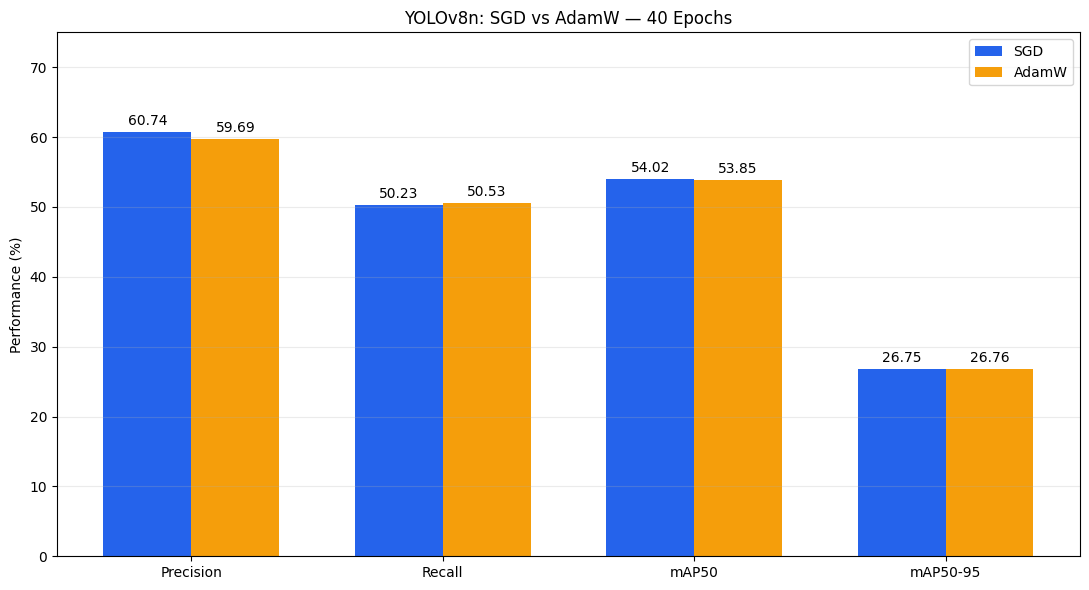

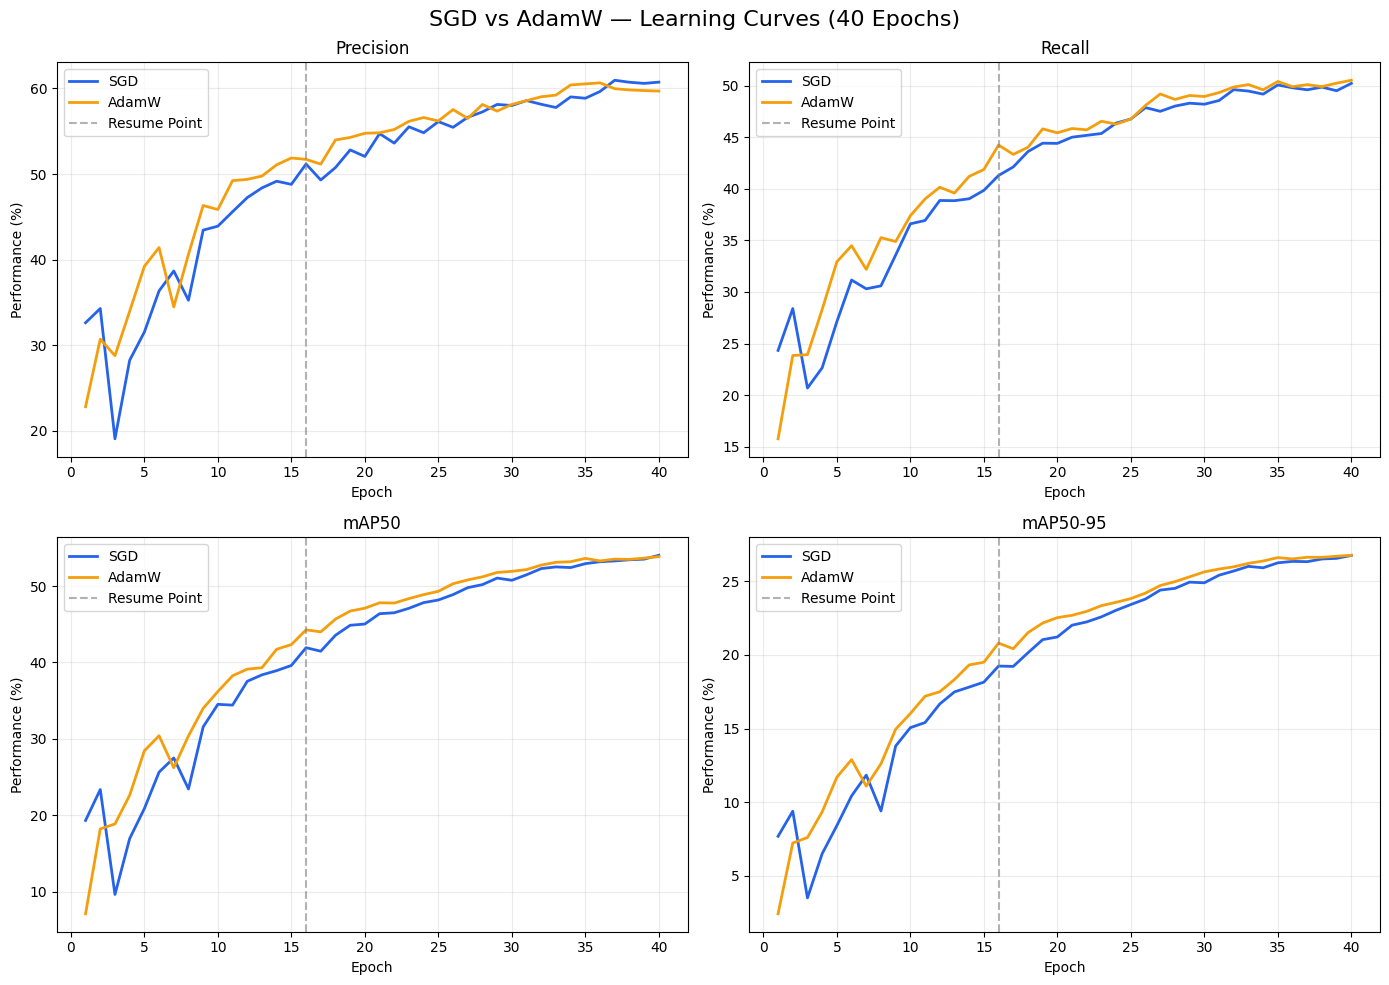

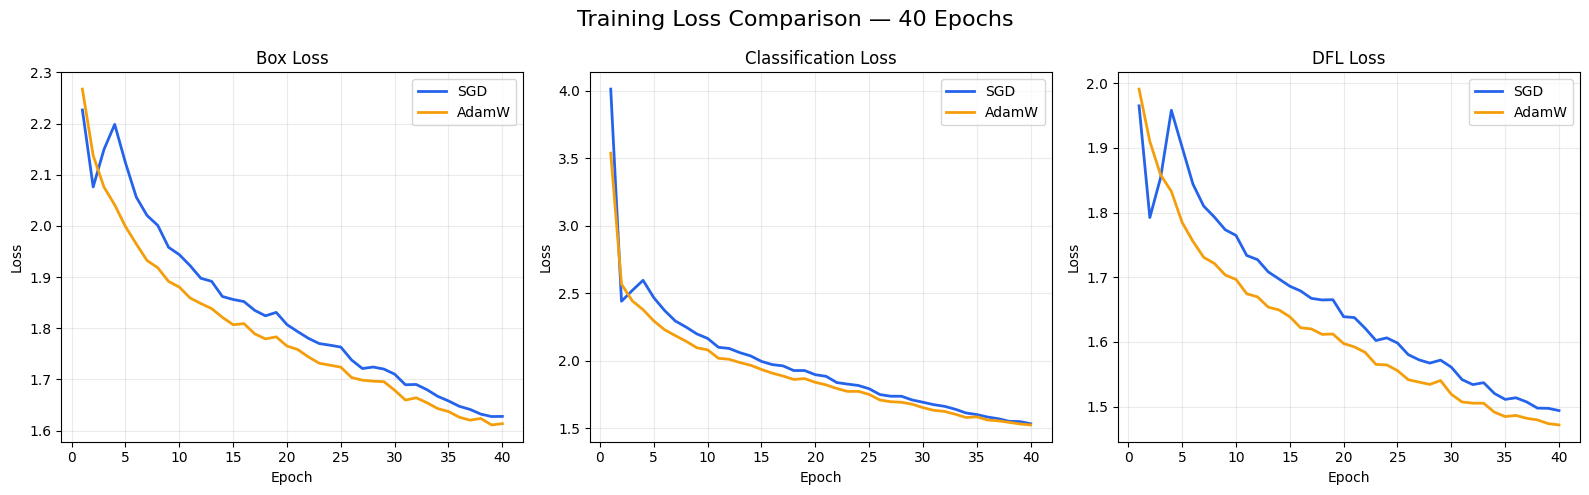


========== SAVED COMPARISON FILES ==========
combined_epoch_results.csv
learning_curves.png
optimizer_comparison.csv
optimizer_comparison.png
performance_difference.csv
training_loss_comparison.png

Optimizer comparison completed!
Both models trained for 40 completed epochs.
Final model selection pending fresh validation.


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# ==========================================
# 1. Define Paths
# ==========================================

WORK_DIR = Path("/kaggle/working")

SGD_RUN_DIR = (
    WORK_DIR / "YOLO_Experiments" /
    "baseline_yolov8n_sgd-2"
)

ADAMW_RUN_DIR = (
    WORK_DIR / "YOLO_Experiments" /
    "optimizer_yolov8n_adamw"
)

COMPARISON_DIR = WORK_DIR / "Optimizer_Comparison_40_Epochs"

COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

SGD_RESULTS_PATH = SGD_RUN_DIR / "results.csv"
ADAMW_RESULTS_PATH = ADAMW_RUN_DIR / "results.csv"

SGD_BEST_PATH = SGD_RUN_DIR / "weights/best.pt"
ADAMW_BEST_PATH = ADAMW_RUN_DIR / "weights/best.pt"

# ==========================================
# 2. Verify Both Models
# ==========================================

print("========== MODEL VERIFICATION ==========")

for path in [
    SGD_RESULTS_PATH,
    ADAMW_RESULTS_PATH,
    SGD_BEST_PATH,
    ADAMW_BEST_PATH
]:
    assert path.exists(), f"Missing: {path}"
    print(f"FOUND: {path}")

# ==========================================
# 3. Load Training Results
# ==========================================

sgd_df = pd.read_csv(SGD_RESULTS_PATH)
adamw_df = pd.read_csv(ADAMW_RESULTS_PATH)

sgd_df.columns = sgd_df.columns.str.strip()
adamw_df.columns = adamw_df.columns.str.strip()

assert len(sgd_df) == 40
assert len(adamw_df) == 40

assert sgd_df["epoch"].tolist() == list(range(1, 41))
assert adamw_df["epoch"].tolist() == list(range(1, 41))

print("\nSGD completed epochs:", len(sgd_df))
print("AdamW completed epochs:", len(adamw_df))

# ==========================================
# 4. Identify Best Epochs
# ==========================================

sgd_best = sgd_df.loc[
    sgd_df["metrics/mAP50-95(B)"].idxmax()
]

adamw_best = adamw_df.loc[
    adamw_df["metrics/mAP50-95(B)"].idxmax()
]

# ==========================================
# 5. Create Comparison Table
# ==========================================

comparison_df = pd.DataFrame([
    {
        "Optimizer": "SGD",
        "Completed Epochs": 40,
        "Best Epoch": int(sgd_best["epoch"]),
        "Learning Rate": 0.01,
        "Precision (%)": sgd_best["metrics/precision(B)"] * 100,
        "Recall (%)": sgd_best["metrics/recall(B)"] * 100,
        "mAP50 (%)": sgd_best["metrics/mAP50(B)"] * 100,
        "mAP50-95 (%)": sgd_best["metrics/mAP50-95(B)"] * 100
    },
    {
        "Optimizer": "AdamW",
        "Completed Epochs": 40,
        "Best Epoch": int(adamw_best["epoch"]),
        "Learning Rate": 0.001,
        "Precision (%)": adamw_best["metrics/precision(B)"] * 100,
        "Recall (%)": adamw_best["metrics/recall(B)"] * 100,
        "mAP50 (%)": adamw_best["metrics/mAP50(B)"] * 100,
        "mAP50-95 (%)": adamw_best["metrics/mAP50-95(B)"] * 100
    }
])

print("\n========== OPTIMIZER COMPARISON ==========")

display(comparison_df.round(4))

comparison_df.to_csv(
    COMPARISON_DIR / "optimizer_comparison.csv",
    index=False
)

# ==========================================
# 6. Calculate Performance Difference
# ==========================================

metric_columns = [
    "Precision (%)",
    "Recall (%)",
    "mAP50 (%)",
    "mAP50-95 (%)"
]

difference_rows = []

for metric in metric_columns:

    sgd_value = comparison_df.loc[0, metric]
    adamw_value = comparison_df.loc[1, metric]

    difference = adamw_value - sgd_value

    if difference > 0:
        better = "AdamW"
    elif difference < 0:
        better = "SGD"
    else:
        better = "Equal"

    difference_rows.append({
        "Metric": metric,
        "SGD (%)": sgd_value,
        "AdamW (%)": adamw_value,
        "AdamW - SGD (pp)": difference,
        "Higher Metric": better
    })

difference_df = pd.DataFrame(difference_rows)

print("\n========== PERFORMANCE DIFFERENCE ==========")

display(difference_df.round(4))

difference_df.to_csv(
    COMPARISON_DIR / "performance_difference.csv",
    index=False
)

# ==========================================
# 7. Overall Performance Comparison Graph
# ==========================================

x = np.arange(len(metric_columns))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width/2,
    comparison_df.loc[0, metric_columns].astype(float),
    width,
    label="SGD",
    color="#2563EB"
)

bars2 = ax.bar(
    x + width/2,
    comparison_df.loc[1, metric_columns].astype(float),
    width,
    label="AdamW",
    color="#F59E0B"
)

ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels([
    "Precision", "Recall", "mAP50", "mAP50-95"
])

ax.set_ylabel("Performance (%)")
ax.set_title("YOLOv8n: SGD vs AdamW — 40 Epochs")
ax.set_ylim(0, 75)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    COMPARISON_DIR / "optimizer_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 8. Learning Curves
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

curve_metrics = [
    ("metrics/precision(B)", "Precision"),
    ("metrics/recall(B)", "Recall"),
    ("metrics/mAP50(B)", "mAP50"),
    ("metrics/mAP50-95(B)", "mAP50-95")
]

for ax, (column, title) in zip(
    axes.flatten(), curve_metrics
):

    ax.plot(
        sgd_df["epoch"],
        sgd_df[column] * 100,
        label="SGD",
        color="#2563EB",
        linewidth=2
    )

    ax.plot(
        adamw_df["epoch"],
        adamw_df[column] * 100,
        label="AdamW",
        color="#F59E0B",
        linewidth=2
    )

    ax.axvline(
        16,
        color="gray",
        linestyle="--",
        alpha=0.6,
        label="Resume Point"
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Performance (%)")
    ax.legend()
    ax.grid(alpha=0.25)

fig.suptitle(
    "SGD vs AdamW — Learning Curves (40 Epochs)",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    COMPARISON_DIR / "learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 9. Training Loss Comparison
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

loss_metrics = [
    ("train/box_loss", "Box Loss"),
    ("train/cls_loss", "Classification Loss"),
    ("train/dfl_loss", "DFL Loss")
]

for ax, (column, title) in zip(axes, loss_metrics):

    ax.plot(
        sgd_df["epoch"],
        sgd_df[column],
        label="SGD",
        color="#2563EB",
        linewidth=2
    )

    ax.plot(
        adamw_df["epoch"],
        adamw_df[column],
        label="AdamW",
        color="#F59E0B",
        linewidth=2
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.25)

fig.suptitle(
    "Training Loss Comparison — 40 Epochs",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    COMPARISON_DIR / "training_loss_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 10. Save Combined Epoch Results
# ==========================================

sgd_export = sgd_df.copy()
sgd_export.insert(0, "Optimizer", "SGD")

adamw_export = adamw_df.copy()
adamw_export.insert(0, "Optimizer", "AdamW")

combined_results = pd.concat(
    [sgd_export, adamw_export],
    ignore_index=True
)

combined_results.to_csv(
    COMPARISON_DIR / "combined_epoch_results.csv",
    index=False
)

# ==========================================
# 11. Final Verification
# ==========================================

print("\n========== SAVED COMPARISON FILES ==========")

for path in sorted(COMPARISON_DIR.iterdir()):
    print(path.name)

print("\nOptimizer comparison completed!")
print("Both models trained for 40 completed epochs.")
print("Final model selection pending fresh validation.")

========== VALIDATION DATASET ==========
Original validation images: 4753
Excluded corrupt image: China_Drone_001007.jpg
Valid validation images: 4752
Missing labels: 0

Evaluation YAML created: /kaggle/working/evaluation_data_40.yaml

========== EVALUATION SETTINGS ==========
GPU: Tesla T4
Image size: 640
Batch size: 32
Validation images: 4752
Confidence threshold: 0.001
NMS IoU: 0.7
Maximum detections: 300

EVALUATING SGD
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 198.0±55.4 MB/s, size: 79.2 KB)
val: Scanning /kaggle/input/datasets/ammritkumaar/rdd2022-preprocessed-yolo/labels/val... 4752 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4752/4752 855.5it/s 5.6s0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/ammr

,Optimizer,Completed Epochs,Validation Images,Precision (%),Recall (%),mAP50 (%),mAP50-95 (%),Inference (ms/image),Evaluation Time (min)
0,SGD,40,4752,60.8425,50.0808,53.9833,26.753,2.2156,0.9577



SGD class-wise results:


,Optimizer,Class ID,Damage Type,Precision (%),Recall (%),mAP50 (%),mAP50-95 (%)
0,SGD,0,Longitudinal Crack,61.4808,50.7640,53.7350,28.5158
1,SGD,1,Transverse Crack,58.3183,51.5460,53.4931,25.6572
2,SGD,2,Alligator Crack,64.8795,61.4784,65.5435,34.0809
3,SGD,3,Pothole,58.6913,36.5348,43.1614,18.7582



EVALUATING AdamW
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.7±0.6 ms, read: 260.6±297.9 MB/s, size: 236.6 KB)
val: Scanning /kaggle/input/datasets/ammritkumaar/rdd2022-preprocessed-yolo/labels/val... 4752 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4752/4752 853.5it/s 5.6s0.0s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/ammritkumaar/rdd2022-preprocessed-yolo/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 149/149 3.5it/s 42.6s0.2ss
                   all       4752      11016      0.598      0.504      0.538      0.267
    Longitudinal Crack       2669       5147      0.598      0.503      0.531      0.286
      Transverse Cr

,Optimizer,Completed Epochs,Validation Images,Precision (%),Recall (%),mAP50 (%),mAP50-95 (%),Inference (ms/image),Evaluation Time (min)
0,AdamW,40,4752,59.8052,50.3931,53.8312,26.7386,2.0768,0.9293



AdamW class-wise results:


,Optimizer,Class ID,Damage Type,Precision (%),Recall (%),mAP50 (%),mAP50-95 (%)
0,AdamW,0,Longitudinal Crack,59.7875,50.2623,53.1057,28.6080
1,AdamW,1,Transverse Crack,58.8777,52.6048,53.8616,25.5092
2,AdamW,2,Alligator Crack,63.9599,61.1111,65.4582,34.3232
3,AdamW,3,Pothole,56.5958,37.5940,42.8994,18.5139



========== FINAL VALIDATION COMPARISON ==========


,Optimizer,Completed Epochs,Validation Images,Precision (%),Recall (%),mAP50 (%),mAP50-95 (%),Inference (ms/image),Evaluation Time (min)
0,SGD,40,4752,60.8425,50.0808,53.9833,26.7530,2.2156,0.9577
1,AdamW,40,4752,59.8052,50.3931,53.8312,26.7386,2.0768,0.9293


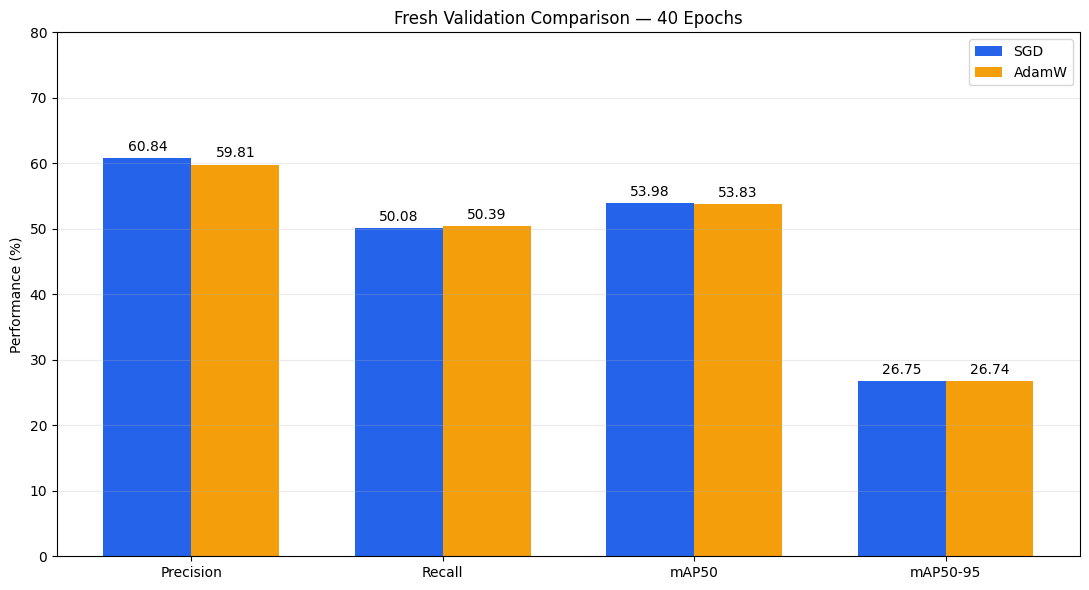

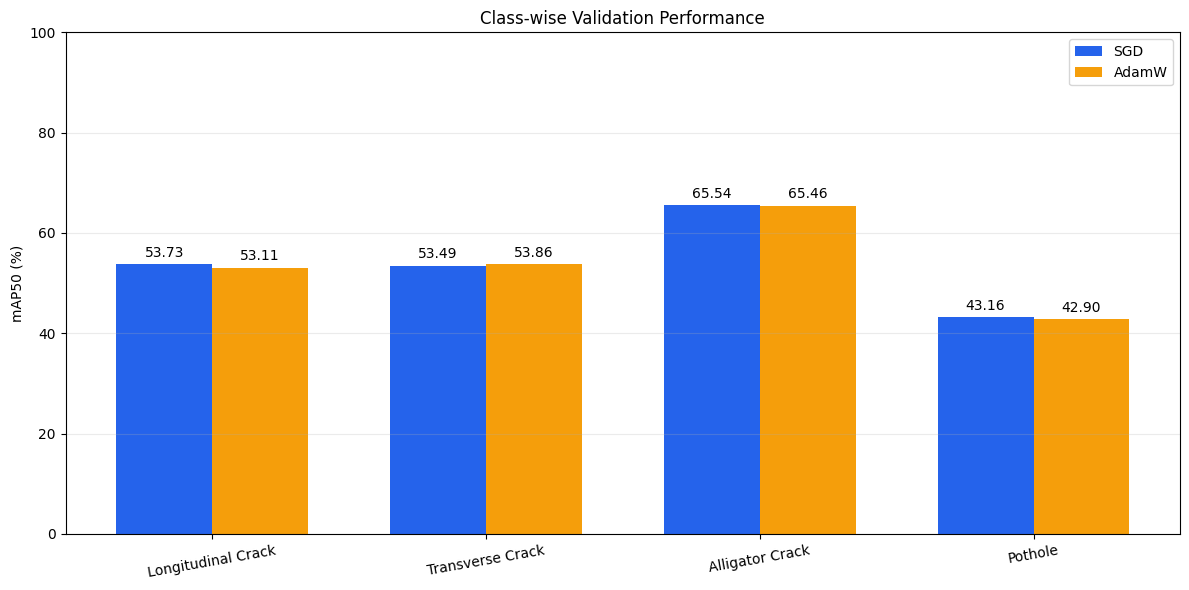


========== FINAL MODEL SELECTED ==========
Selected model: YOLOv8n-SGD
Completed epochs: 40
Selection metric: Validation mAP50-95
Precision: 60.8425%
Recall: 50.0808%
mAP50: 53.9833%
mAP50-95: 26.7530%

Final model: /kaggle/working/Validation_Evaluation_40_Epochs/Selected_Model/best_model.pt
Model size: 12.26 MB

Validation evaluation completed!
Final model ready for test evaluation.


In [19]:
import torch
import gc
import time
import yaml
import json
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from pathlib import Path
from ultralytics import YOLO

# ==========================================
# 1. Define Paths
# ==========================================

WORK_DIR = Path("/kaggle/working")

DATASET_PATH = Path(
    "/kaggle/input/datasets/ammritkumaar/"
    "rdd2022-preprocessed-yolo"
)

VALIDATION_DIR = (
    WORK_DIR / "Validation_Evaluation_40_Epochs"
)

VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

SGD_BEST_PATH = (
    WORK_DIR / "YOLO_Experiments" /
    "baseline_yolov8n_sgd-2/weights/best.pt"
)

ADAMW_BEST_PATH = (
    WORK_DIR / "YOLO_Experiments" /
    "optimizer_yolov8n_adamw/weights/best.pt"
)

assert SGD_BEST_PATH.exists()
assert ADAMW_BEST_PATH.exists()

# ==========================================
# 2. Prepare Validation Image List
# ==========================================

VAL_IMAGES_DIR = DATASET_PATH / "images/val"
VAL_LABELS_DIR = DATASET_PATH / "labels/val"

all_val_images = sorted([
    p for p in VAL_IMAGES_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

CORRUPT_IMAGE = "China_Drone_001007.jpg"

valid_val_images = [
    p for p in all_val_images
    if p.name != CORRUPT_IMAGE
]

assert len(all_val_images) == 4753
assert len(valid_val_images) == 4752

missing_labels = [
    p.name for p in valid_val_images
    if not (VAL_LABELS_DIR / f"{p.stem}.txt").exists()
]

assert len(missing_labels) == 0

VAL_LIST_PATH = WORK_DIR / "validation_images_40.txt"

VAL_LIST_PATH.write_text(
    "\n".join(str(p) for p in valid_val_images) + "\n"
)

print("========== VALIDATION DATASET ==========")

print("Original validation images:", len(all_val_images))
print("Excluded corrupt image:", CORRUPT_IMAGE)
print("Valid validation images:", len(valid_val_images))
print("Missing labels:", len(missing_labels))

# ==========================================
# 3. Create Evaluation YAML
# ==========================================

CLASS_NAMES = {
    0: "Longitudinal Crack",
    1: "Transverse Crack",
    2: "Alligator Crack",
    3: "Pothole"
}

EVAL_YAML_PATH = WORK_DIR / "evaluation_data_40.yaml"

evaluation_yaml = {
    "path": str(DATASET_PATH),
    "train": "images/train",
    "val": str(VAL_LIST_PATH),
    "test": "images/test",
    "nc": 4,
    "names": CLASS_NAMES
}

with open(EVAL_YAML_PATH, "w") as f:
    yaml.safe_dump(
        evaluation_yaml,
        f,
        sort_keys=False
    )

print("\nEvaluation YAML created:", EVAL_YAML_PATH)

# ==========================================
# 4. Clear GPU Memory
# ==========================================

for variable in [
    "model",
    "results",
    "adamw_model",
    "adamw_results"
]:
    if variable in globals():
        del globals()[variable]

gc.collect()
torch.cuda.empty_cache()

assert torch.cuda.is_available()

IMG_SIZE = 640
BATCH_SIZE = 32
DEVICE = 0

print("\n========== EVALUATION SETTINGS ==========")

print("GPU:", torch.cuda.get_device_name(DEVICE))
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Validation images:", len(valid_val_images))
print("Confidence threshold: 0.001")
print("NMS IoU: 0.7")
print("Maximum detections: 300")

# ==========================================
# 5. Define Evaluation Function
# ==========================================

def evaluate_model(model_path, optimizer_name):

    print(f"\n{'=' * 50}")
    print(f"EVALUATING {optimizer_name}")
    print(f"{'=' * 50}")

    evaluation_model = YOLO(str(model_path))

    start_time = time.time()

    metrics = evaluation_model.val(
        data=str(EVAL_YAML_PATH),
        split="val",
        imgsz=IMG_SIZE,
        batch=BATCH_SIZE,
        device=DEVICE,
        workers=2,
        conf=0.001,
        iou=0.7,
        max_det=300,
        half=True,
        plots=True,
        project=str(VALIDATION_DIR),
        name=f"{optimizer_name}_Validation",
        exist_ok=True,
        verbose=True
    )

    elapsed_minutes = (
        time.time() - start_time
    ) / 60

    # Overall metrics
    overall = {
        "Optimizer": optimizer_name,
        "Completed Epochs": 40,
        "Validation Images": len(valid_val_images),
        "Precision (%)": float(metrics.box.mp * 100),
        "Recall (%)": float(metrics.box.mr * 100),
        "mAP50 (%)": float(metrics.box.map50 * 100),
        "mAP50-95 (%)": float(metrics.box.map * 100),
        "Inference (ms/image)": float(
            metrics.speed["inference"]
        ),
        "Evaluation Time (min)": elapsed_minutes
    }

    # Class-wise metrics
    class_rows = []

    for i, class_id in enumerate(
        metrics.box.ap_class_index
    ):

        class_id = int(class_id)

        class_rows.append({
            "Optimizer": optimizer_name,
            "Class ID": class_id,
            "Damage Type": CLASS_NAMES[class_id],
            "Precision (%)": float(
                metrics.box.p[i] * 100
            ),
            "Recall (%)": float(
                metrics.box.r[i] * 100
            ),
            "mAP50 (%)": float(
                metrics.box.ap50[i] * 100
            ),
            "mAP50-95 (%)": float(
                metrics.box.ap[i] * 100
            )
        })

    overall_df = pd.DataFrame([overall])
    classwise_df = pd.DataFrame(class_rows)

    output_dir = (
        VALIDATION_DIR /
        f"{optimizer_name}_Validation"
    )

    overall_df.to_csv(
        output_dir / "overall_metrics.csv",
        index=False
    )

    classwise_df.to_csv(
        output_dir / "classwise_metrics.csv",
        index=False
    )

    print(f"\n{optimizer_name} overall results:")
    display(overall_df.round(4))

    print(f"\n{optimizer_name} class-wise results:")
    display(classwise_df.round(4))

    del evaluation_model
    del metrics

    gc.collect()
    torch.cuda.empty_cache()

    return overall, classwise_df

# ==========================================
# 6. Evaluate SGD
# ==========================================

sgd_validation, sgd_classwise = evaluate_model(
    SGD_BEST_PATH,
    "SGD"
)

# ==========================================
# 7. Evaluate AdamW
# ==========================================

adamw_validation, adamw_classwise = evaluate_model(
    ADAMW_BEST_PATH,
    "AdamW"
)

# ==========================================
# 8. Compare Validation Results
# ==========================================

validation_comparison_df = pd.DataFrame([
    sgd_validation,
    adamw_validation
])

classwise_comparison_df = pd.concat(
    [sgd_classwise, adamw_classwise],
    ignore_index=True
)

print("\n========== FINAL VALIDATION COMPARISON ==========")

display(validation_comparison_df.round(4))

validation_comparison_df.to_csv(
    VALIDATION_DIR / "validation_comparison.csv",
    index=False
)

classwise_comparison_df.to_csv(
    VALIDATION_DIR / "classwise_comparison.csv",
    index=False
)

# ==========================================
# 9. Overall Comparison Graph
# ==========================================

metric_columns = [
    "Precision (%)",
    "Recall (%)",
    "mAP50 (%)",
    "mAP50-95 (%)"
]

x = np.arange(len(metric_columns))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width/2,
    validation_comparison_df.loc[
        0, metric_columns
    ].astype(float),
    width,
    label="SGD",
    color="#2563EB"
)

bars2 = ax.bar(
    x + width/2,
    validation_comparison_df.loc[
        1, metric_columns
    ].astype(float),
    width,
    label="AdamW",
    color="#F59E0B"
)

ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

ax.set_xticks(x)

ax.set_xticklabels([
    "Precision", "Recall",
    "mAP50", "mAP50-95"
])

ax.set_ylabel("Performance (%)")
ax.set_title("Fresh Validation Comparison — 40 Epochs")
ax.set_ylim(0, 80)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    VALIDATION_DIR / "validation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 10. Class-wise mAP50 Comparison
# ==========================================

class_names = list(CLASS_NAMES.values())

sgd_ap = (
    sgd_classwise
    .set_index("Class ID")
    .reindex(range(4))["mAP50 (%)"]
    .to_numpy()
)

adamw_ap = (
    adamw_classwise
    .set_index("Class ID")
    .reindex(range(4))["mAP50 (%)"]
    .to_numpy()
)

x = np.arange(4)

fig, ax = plt.subplots(figsize=(12, 6))

bars1 = ax.bar(
    x - width/2,
    sgd_ap,
    width,
    label="SGD",
    color="#2563EB"
)

bars2 = ax.bar(
    x + width/2,
    adamw_ap,
    width,
    label="AdamW",
    color="#F59E0B"
)

ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=10)
ax.set_ylabel("mAP50 (%)")
ax.set_title("Class-wise Validation Performance")
ax.set_ylim(0, 100)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    VALIDATION_DIR / "classwise_map50_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 11. Select Final Best Model
# ==========================================

best_index = validation_comparison_df[
    "mAP50-95 (%)"
].idxmax()

selected_row = validation_comparison_df.loc[
    best_index
]

SELECTED_OPTIMIZER = selected_row["Optimizer"]

if SELECTED_OPTIMIZER == "SGD":
    SELECTED_SOURCE_PATH = SGD_BEST_PATH
else:
    SELECTED_SOURCE_PATH = ADAMW_BEST_PATH

FINAL_MODEL_DIR = VALIDATION_DIR / "Selected_Model"

FINAL_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FINAL_MODEL_PATH = FINAL_MODEL_DIR / "best_model.pt"

shutil.copy2(
    SELECTED_SOURCE_PATH,
    FINAL_MODEL_PATH
)

# Save model selection details
selection_summary = {
    "selected_model": f"YOLOv8n-{SELECTED_OPTIMIZER}",
    "selection_metric": "Validation mAP50-95",
    "completed_epochs": 40,
    "validation_images": len(valid_val_images),
    "precision": float(selected_row["Precision (%)"]),
    "recall": float(selected_row["Recall (%)"]),
    "mAP50": float(selected_row["mAP50 (%)"]),
    "mAP50-95": float(selected_row["mAP50-95 (%)"]),
    "source_checkpoint": str(SELECTED_SOURCE_PATH),
    "saved_checkpoint": str(FINAL_MODEL_PATH)
}

with open(
    FINAL_MODEL_DIR / "model_selection.json",
    "w"
) as f:
    json.dump(selection_summary, f, indent=4)

# ==========================================
# 12. Final Summary
# ==========================================

print("\n========== FINAL MODEL SELECTED ==========")

print("Selected model:", selection_summary["selected_model"])
print("Completed epochs: 40")
print("Selection metric: Validation mAP50-95")

print(f"Precision: {selection_summary['precision']:.4f}%")
print(f"Recall: {selection_summary['recall']:.4f}%")
print(f"mAP50: {selection_summary['mAP50']:.4f}%")
print(f"mAP50-95: {selection_summary['mAP50-95']:.4f}%")

print("\nFinal model:", FINAL_MODEL_PATH)

assert FINAL_MODEL_PATH.exists()

print(
    "Model size:",
    round(
        FINAL_MODEL_PATH.stat().st_size / (1024**2),
        2
    ),
    "MB"
)

print("\nValidation evaluation completed!")
print("Final model ready for test evaluation.")

========== SELECTED MODEL ==========
Model: YOLOv8n-SGD
Completed epochs: 40
Selection metric: Validation mAP50-95
Validation mAP50: 53.98325963023645
Validation mAP50-95: 26.75301787336523

========== TEST DATASET ==========
Test images: 2377
Test labels: 2377
Images without labels: 0
Labels without images: 0

Test YAML created: /kaggle/working/test_data_40.yaml

========== TEST SETTINGS ==========
GPU: Tesla T4
Model: YOLOv8n-SGD
Image size: 640
Batch size: 32
Confidence threshold: 0.001
NMS IoU: 0.7
Maximum detections: 300

========== RUNNING FINAL TEST ==========
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.0 ms, read: 0.3±0.1 MB/s, size: 70.8 KB). Use local storage instead of remote/mounted storage for better performanc

,Model,Completed Epochs,Test Images,Precision (%),Recall (%),mAP50 (%),mAP50-95 (%),Inference (ms/image),Evaluation Time (min)
0,YOLOv8n-SGD,40,2377,60.9423,50.7243,53.9796,26.9935,2.9621,13.9259



========== CLASS-WISE TEST PERFORMANCE ==========


,Class ID,Damage Type,Precision (%),Recall (%),mAP50 (%),mAP50-95 (%)
0,0,Longitudinal Crack,60.2397,50.3335,52.6382,28.2482
1,1,Transverse Crack,59.5743,50.8078,53.7416,25.5106
2,2,Alligator Crack,65.7485,62.6186,66.9578,35.6277
3,3,Pothole,58.2069,39.1374,42.5810,18.5875



========== VALIDATION VS TEST ==========


,Dataset,Images,Precision (%),Recall (%),mAP50 (%),mAP50-95 (%)
0,Validation,4752,60.8425,50.0808,53.9833,26.7530
1,Test,2377,60.9423,50.7243,53.9796,26.9935


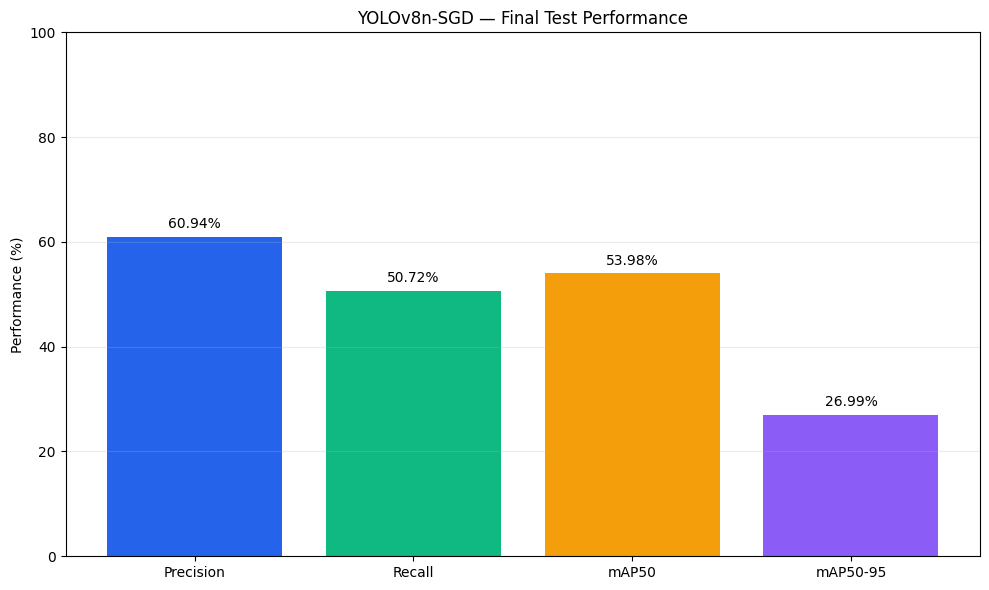


========== FINAL TEST SUMMARY ==========
Selected model: YOLOv8n-SGD
Completed epochs: 40
Test images: 2377
Precision: 60.9423%
Recall: 50.7243%
mAP50: 53.9796%
mAP50-95: 26.9935%
Inference speed: 2.962 ms/image
Evaluation time: 13.93 minutes

========== SAVED TEST FILES ==========
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
test_classwise_metrics.csv
test_overall_metrics.csv
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg

Final test evaluation completed!
Next: Train, validation and test detection accuracy.


In [20]:
import torch
import gc
import time
import json
import yaml
import shutil
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from ultralytics import YOLO

# ==========================================
# 1. Define Paths
# ==========================================

WORK_DIR = Path("/kaggle/working")

DATASET_PATH = Path(
    "/kaggle/input/datasets/ammritkumaar/"
    "rdd2022-preprocessed-yolo"
)

VALIDATION_DIR = (
    WORK_DIR / "Validation_Evaluation_40_Epochs"
)

FINAL_MODEL_PATH = (
    VALIDATION_DIR /
    "Selected_Model/best_model.pt"
)

SELECTION_PATH = (
    VALIDATION_DIR /
    "Selected_Model/model_selection.json"
)

TEST_PROJECT_DIR = (
    WORK_DIR / "Final_Test_Evaluation_40_Epochs"
)

TEST_PROJECT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

assert FINAL_MODEL_PATH.exists()
assert SELECTION_PATH.exists()

# ==========================================
# 2. Load Selected Model Information
# ==========================================

with open(SELECTION_PATH, "r") as f:
    selection_summary = json.load(f)

SELECTED_MODEL = selection_summary["selected_model"]

print("========== SELECTED MODEL ==========")

print("Model:", SELECTED_MODEL)
print("Completed epochs:", selection_summary["completed_epochs"])
print("Selection metric:", selection_summary["selection_metric"])
print("Validation mAP50:", selection_summary["mAP50"])
print("Validation mAP50-95:", selection_summary["mAP50-95"])

assert selection_summary["completed_epochs"] == 40

# ==========================================
# 3. Verify Test Dataset
# ==========================================

TEST_IMAGES_DIR = DATASET_PATH / "images/test"
TEST_LABELS_DIR = DATASET_PATH / "labels/test"

test_images = sorted([
    p for p in TEST_IMAGES_DIR.iterdir()
    if p.suffix.lower() in [
        ".jpg", ".jpeg", ".png"
    ]
])

test_labels = sorted(
    TEST_LABELS_DIR.glob("*.txt")
)

image_stems = {p.stem for p in test_images}
label_stems = {p.stem for p in test_labels}

print("\n========== TEST DATASET ==========")

print("Test images:", len(test_images))
print("Test labels:", len(test_labels))

print(
    "Images without labels:",
    len(image_stems - label_stems)
)

print(
    "Labels without images:",
    len(label_stems - image_stems)
)

assert len(test_images) == 2377
assert len(test_labels) == 2377
assert image_stems == label_stems

# ==========================================
# 4. Create Test Evaluation YAML
# ==========================================

CLASS_NAMES = {
    0: "Longitudinal Crack",
    1: "Transverse Crack",
    2: "Alligator Crack",
    3: "Pothole"
}

TEST_YAML_PATH = WORK_DIR / "test_data_40.yaml"

test_yaml = {
    "path": str(DATASET_PATH),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 4,
    "names": CLASS_NAMES
}

with open(TEST_YAML_PATH, "w") as f:
    yaml.safe_dump(
        test_yaml,
        f,
        sort_keys=False
    )

print("\nTest YAML created:", TEST_YAML_PATH)

# ==========================================
# 5. GPU and Model Setup
# ==========================================

gc.collect()
torch.cuda.empty_cache()

IMG_SIZE = 640
BATCH_SIZE = 32
DEVICE = 0

assert torch.cuda.is_available()

final_model = YOLO(str(FINAL_MODEL_PATH))

assert final_model.names == CLASS_NAMES

print("\n========== TEST SETTINGS ==========")

print("GPU:", torch.cuda.get_device_name(DEVICE))
print("Model:", SELECTED_MODEL)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Confidence threshold: 0.001")
print("NMS IoU: 0.7")
print("Maximum detections: 300")

# ==========================================
# 6. Run Final Test Evaluation
# ==========================================

print("\n========== RUNNING FINAL TEST ==========")

start_time = time.time()

test_metrics = final_model.val(
    data=str(TEST_YAML_PATH),
    split="test",
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=2,
    conf=0.001,
    iou=0.7,
    max_det=300,
    half=True,
    plots=True,
    project=str(TEST_PROJECT_DIR),
    name="Selected_Model_Test",
    exist_ok=True,
    verbose=True
)

test_evaluation_time = (
    time.time() - start_time
) / 60

TEST_RESULTS_DIR = (
    TEST_PROJECT_DIR / "Selected_Model_Test"
)

# ==========================================
# 7. Extract Overall Test Metrics
# ==========================================

test_overall = {
    "Model": SELECTED_MODEL,
    "Completed Epochs": 40,
    "Test Images": len(test_images),
    "Precision (%)": float(
        test_metrics.box.mp * 100
    ),
    "Recall (%)": float(
        test_metrics.box.mr * 100
    ),
    "mAP50 (%)": float(
        test_metrics.box.map50 * 100
    ),
    "mAP50-95 (%)": float(
        test_metrics.box.map * 100
    ),
    "Inference (ms/image)": float(
        test_metrics.speed["inference"]
    ),
    "Evaluation Time (min)": test_evaluation_time
}

test_overall_df = pd.DataFrame([test_overall])

print("\n========== OVERALL TEST PERFORMANCE ==========")

display(test_overall_df.round(4))

test_overall_df.to_csv(
    TEST_RESULTS_DIR / "test_overall_metrics.csv",
    index=False
)

# ==========================================
# 8. Extract Class-wise Test Metrics
# ==========================================

class_rows = []

for i, class_id in enumerate(
    test_metrics.box.ap_class_index
):

    class_id = int(class_id)

    class_rows.append({
        "Class ID": class_id,
        "Damage Type": CLASS_NAMES[class_id],
        "Precision (%)": float(
            test_metrics.box.p[i] * 100
        ),
        "Recall (%)": float(
            test_metrics.box.r[i] * 100
        ),
        "mAP50 (%)": float(
            test_metrics.box.ap50[i] * 100
        ),
        "mAP50-95 (%)": float(
            test_metrics.box.ap[i] * 100
        )
    })

test_classwise_df = pd.DataFrame(class_rows)

print("\n========== CLASS-WISE TEST PERFORMANCE ==========")

display(test_classwise_df.round(4))

test_classwise_df.to_csv(
    TEST_RESULTS_DIR / "test_classwise_metrics.csv",
    index=False
)

# ==========================================
# 9. Validation vs Test Comparison
# ==========================================

val_test_df = pd.DataFrame([
    {
        "Dataset": "Validation",
        "Images": 4752,
        "Precision (%)": selection_summary["precision"],
        "Recall (%)": selection_summary["recall"],
        "mAP50 (%)": selection_summary["mAP50"],
        "mAP50-95 (%)": selection_summary["mAP50-95"]
    },
    {
        "Dataset": "Test",
        "Images": 2377,
        "Precision (%)": test_overall["Precision (%)"],
        "Recall (%)": test_overall["Recall (%)"],
        "mAP50 (%)": test_overall["mAP50 (%)"],
        "mAP50-95 (%)": test_overall["mAP50-95 (%)"]
    }
])

print("\n========== VALIDATION VS TEST ==========")

display(val_test_df.round(4))

val_test_df.to_csv(
    TEST_PROJECT_DIR / "validation_vs_test.csv",
    index=False
)

# ==========================================
# 10. Test Performance Graph
# ==========================================

metric_names = [
    "Precision",
    "Recall",
    "mAP50",
    "mAP50-95"
]

metric_values = [
    test_overall["Precision (%)"],
    test_overall["Recall (%)"],
    test_overall["mAP50 (%)"],
    test_overall["mAP50-95 (%)"]
]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    metric_names,
    metric_values,
    color=[
        "#2563EB",
        "#10B981",
        "#F59E0B",
        "#8B5CF6"
    ]
)

ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=4
)

ax.set_title(
    f"{SELECTED_MODEL} — Final Test Performance"
)

ax.set_ylabel("Performance (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    TEST_PROJECT_DIR / "final_test_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 11. Save Final Model and Test Summary
# ==========================================

FINAL_EXPORT_DIR = (
    TEST_PROJECT_DIR / "Final_Model"
)

FINAL_EXPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

shutil.copy2(
    FINAL_MODEL_PATH,
    FINAL_EXPORT_DIR / "best_model.pt"
)

shutil.copy2(
    SELECTION_PATH,
    FINAL_EXPORT_DIR / "model_selection.json"
)

with open(
    TEST_PROJECT_DIR / "test_summary.json",
    "w"
) as f:
    json.dump(
        test_overall,
        f,
        indent=4
    )

# ==========================================
# 12. Final Verification
# ==========================================

print("\n========== FINAL TEST SUMMARY ==========")

print("Selected model:", SELECTED_MODEL)
print("Completed epochs: 40")
print("Test images:", len(test_images))

for metric, value in zip(
    metric_names,
    metric_values
):
    print(f"{metric}: {value:.4f}%")

print(
    "Inference speed:",
    round(test_overall["Inference (ms/image)"], 3),
    "ms/image"
)

print(
    "Evaluation time:",
    round(test_evaluation_time, 2),
    "minutes"
)

print("\n========== SAVED TEST FILES ==========")

for path in sorted(TEST_RESULTS_DIR.iterdir()):
    print(path.name)

print("\nFinal test evaluation completed!")
print("Next: Train, validation and test detection accuracy.")

========== DETECTION ACCURACY SETTINGS ==========
Model: YOLOv8n-SGD
Completed epochs: 40
GPU: Tesla T4
Confidence: 0.25
Matching IoU: 0.5
NMS IoU: 0.7
Prediction batch: 8
TRAIN: 16636 images
VAL: 4752 images
TEST: 2377 images

EVALUATING TRAIN DATASET
Total images: 16636


TRAIN accuracy:   0%|          | 0/16636 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

,Dataset,Images,Ground Truth Objects,Predicted Objects,TP,FP,FN,Precision (%),Recall (%),Detection Accuracy (%),F1-score (%),Time (min)
0,Training,16636,38518,30866,20941,9925,17577,67.84,54.37,43.23,60.36,7.95



EVALUATING VAL DATASET
Total images: 4752


VAL accuracy:   0%|          | 0/4752 [00:00<?, ?it/s]

... (7 outputs left out)

,Dataset,Images,Ground Truth Objects,Predicted Objects,TP,FP,FN,Precision (%),Recall (%),Detection Accuracy (%),F1-score (%),Time (min)
0,Training,16636,38518,30866,20941,9925,17577,67.84,54.37,43.23,60.36,7.95
1,Validation,4752,11016,8411,5316,3095,5700,63.20,48.26,37.67,54.73,2.27
2,Test,2377,5467,4257,2689,1568,2778,63.17,49.19,38.22,55.31,1.14



========== CLASS-WISE ACCURACY ==========


,Dataset,Class ID,Damage Type,Ground Truth Objects,Predicted Objects,TP,FP,FN,Precision (%),Recall (%),Detection Accuracy (%),F1-score (%)
0,Training,0,Longitudinal Crack,18317,14717,9800,4917,8517,66.59,53.50,42.18,59.33
1,Training,1,Transverse Crack,8229,6833,4436,2397,3793,64.92,53.91,41.75,58.90
2,Training,2,Alligator Crack,7384,6425,4734,1691,2650,73.68,64.11,52.17,68.56
3,Training,3,Pothole,4588,2891,1971,920,2617,68.18,42.96,35.78,52.71
4,Validation,0,Longitudinal Crack,5147,3932,2456,1476,2691,62.46,47.72,37.08,54.10
5,Validation,1,Transverse Crack,2361,1874,1149,725,1212,61.31,48.67,37.23,54.26
6,Validation,2,Alligator Crack,2178,1863,1250,613,928,67.10,57.39,44.79,61.87
7,Validation,3,Pothole,1330,742,461,281,869,62.13,34.66,28.62,44.50
8,Test,0,Longitudinal Crack,2549,1995,1228,767,1321,61.55,48.18,37.03,54.05
9,Test,1,Transverse Crack,1238,968,594,374,644,61.36,47.98,36.85,53.85



Test predictions saved: 4257
Test images processed: 2377


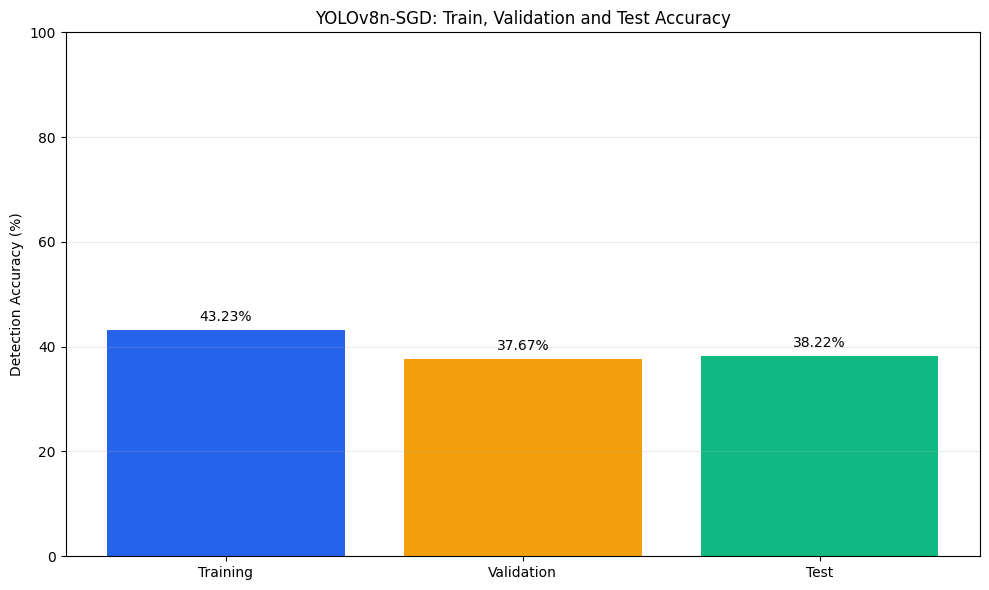

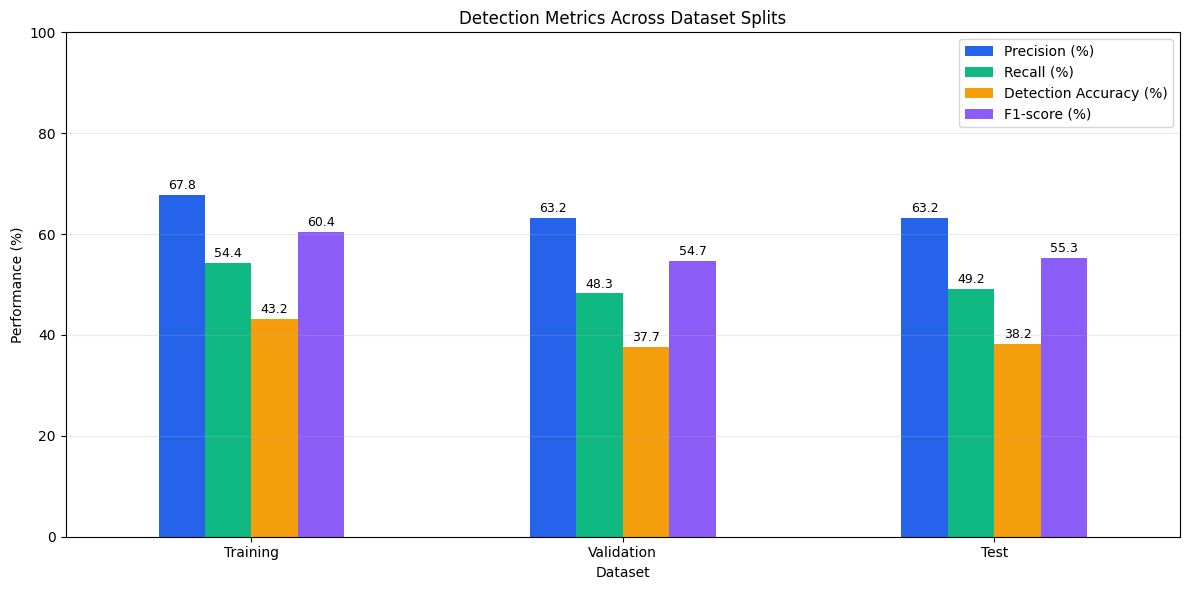


========== FINAL ACCURACY SUMMARY ==========
Training Accuracy: 43.23%
Validation Accuracy: 37.67%
Test Accuracy: 38.22%

Total evaluation time: 11.39 minutes

========== SAVED FILES ==========
accuracy_config.json
all_detection_metrics.png
classwise_detection_accuracy.csv
detection_accuracy_comparison.png
overall_detection_accuracy.csv
test_image_summary.csv
test_predictions.csv

All three dataset evaluations completed!
Test predictions ready for severity assessment.


In [21]:
import gc
import time
import json
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.auto import tqdm
from ultralytics import YOLO

# ==========================================
# 1. Define Paths and Settings
# ==========================================

WORK_DIR = Path("/kaggle/working")

DATASET_PATH = Path(
    "/kaggle/input/datasets/ammritkumaar/"
    "rdd2022-preprocessed-yolo"
)

FINAL_MODEL_PATH = (
    WORK_DIR /
    "Validation_Evaluation_40_Epochs/"
    "Selected_Model/best_model.pt"
)

ACCURACY_DIR = (
    WORK_DIR / "Detection_Accuracy_40_Epochs"
)

ACCURACY_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = {
    0: "Longitudinal Crack",
    1: "Transverse Crack",
    2: "Alligator Crack",
    3: "Pothole"
}

CONF_THRESHOLD = 0.25
MATCH_IOU = 0.50
NMS_IOU = 0.70

IMG_SIZE = 640
PRED_BATCH = 8
DEVICE = 1

CORRUPT_IMAGE = "China_Drone_001007.jpg"

assert FINAL_MODEL_PATH.exists()
assert torch.cuda.device_count() >= 2

# ==========================================
# 2. Clear GPU Memory and Load Model
# ==========================================

for variable in [
    "model",
    "results",
    "adamw_model",
    "adamw_results",
    "final_model",
    "test_metrics",
    "accuracy_model"
]:
    if variable in globals():
        del globals()[variable]

gc.collect()
torch.cuda.empty_cache()

accuracy_model = YOLO(str(FINAL_MODEL_PATH))

assert accuracy_model.names == CLASS_NAMES

print("========== DETECTION ACCURACY SETTINGS ==========")

print("Model: YOLOv8n-SGD")
print("Completed epochs: 40")
print("GPU:", torch.cuda.get_device_name(DEVICE))
print("Confidence:", CONF_THRESHOLD)
print("Matching IoU:", MATCH_IOU)
print("NMS IoU:", NMS_IOU)
print("Prediction batch:", PRED_BATCH)

# ==========================================
# 3. Prepare All Dataset Splits
# ==========================================

dataset_splits = {}

expected_counts = {
    "train": 16636,
    "val": 4752,
    "test": 2377
}

for split in ["train", "val", "test"]:

    image_dir = DATASET_PATH / "images" / split
    label_dir = DATASET_PATH / "labels" / split

    images = sorted([
        p for p in image_dir.iterdir()
        if p.suffix.lower() in [
            ".jpg", ".jpeg", ".png"
        ]
    ])

    if split == "val":
        images = [
            p for p in images
            if p.name != CORRUPT_IMAGE
        ]

    assert len(images) == expected_counts[split]

    missing_labels = [
        p.name for p in images
        if not (label_dir / f"{p.stem}.txt").exists()
    ]

    assert not missing_labels, (
        f"Missing labels in {split}: {missing_labels[:5]}"
    )

    dataset_splits[split] = images

    print(f"{split.upper()}: {len(images)} images")

# ==========================================
# 4. IoU Calculation Function
# ==========================================

def calculate_iou(box, boxes):

    if len(boxes) == 0:
        return np.array([], dtype=float)

    x1 = np.maximum(box[0], boxes[:, 0])
    y1 = np.maximum(box[1], boxes[:, 1])

    x2 = np.minimum(box[2], boxes[:, 2])
    y2 = np.minimum(box[3], boxes[:, 3])

    intersection = (
        np.maximum(0, x2 - x1) *
        np.maximum(0, y2 - y1)
    )

    box_area = (
        max(0, box[2] - box[0]) *
        max(0, box[3] - box[1])
    )

    boxes_area = (
        np.maximum(0, boxes[:, 2] - boxes[:, 0]) *
        np.maximum(0, boxes[:, 3] - boxes[:, 1])
    )

    union = box_area + boxes_area - intersection

    return intersection / np.maximum(union, 1e-9)

# ==========================================
# 5. Read Ground Truth YOLO Labels
# ==========================================

def read_ground_truth(label_path, width, height):

    classes = []
    boxes = []

    for line in label_path.read_text().splitlines():

        if not line.strip():
            continue

        values = line.split()

        class_id = int(float(values[0]))

        xc, yc, bw, bh = map(
            float, values[1:5]
        )

        x1 = (xc - bw / 2) * width
        y1 = (yc - bh / 2) * height

        x2 = (xc + bw / 2) * width
        y2 = (yc + bh / 2) * height

        classes.append(class_id)

        boxes.append([
            x1, y1, x2, y2
        ])

    return (
        np.asarray(classes, dtype=int),
        np.asarray(boxes, dtype=float).reshape(-1, 4)
    )

# ==========================================
# 6. Calculate Evaluation Metrics
# ==========================================

def safe_divide(numerator, denominator):

    return (
        numerator / denominator
        if denominator > 0 else 0.0
    )


def calculate_metrics(tp, fp, fn):

    precision = safe_divide(tp, tp + fp)
    recall = safe_divide(tp, tp + fn)

    accuracy = safe_divide(
        tp, tp + fp + fn
    )

    f1 = safe_divide(
        2 * tp,
        2 * tp + fp + fn
    )

    return {
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "Precision (%)": precision * 100,
        "Recall (%)": recall * 100,
        "Detection Accuracy (%)": accuracy * 100,
        "F1-score (%)": f1 * 100
    }

# ==========================================
# 7. Evaluate Each Dataset Split
# ==========================================

overall_rows = []
classwise_rows = []

# Save test predictions for Cell 21
test_prediction_rows = []
test_image_rows = []

total_start_time = time.time()

for split, image_paths in dataset_splits.items():

    print(f"\n{'=' * 55}")
    print(f"EVALUATING {split.upper()} DATASET")
    print(f"Total images: {len(image_paths)}")
    print(f"{'=' * 55}")

    split_start_time = time.time()

    tp_counts = np.zeros(4, dtype=np.int64)
    fp_counts = np.zeros(4, dtype=np.int64)
    fn_counts = np.zeros(4, dtype=np.int64)

    gt_counts = np.zeros(4, dtype=np.int64)
    pred_counts = np.zeros(4, dtype=np.int64)

    processed_images = 0

    label_dir = DATASET_PATH / "labels" / split

    progress = tqdm(
        total=len(image_paths),
        desc=f"{split.upper()} accuracy"
    )

    # Explicit small batches to prevent GPU OOM
    for start in range(
        0, len(image_paths), PRED_BATCH
    ):

        batch_paths = image_paths[
            start:start + PRED_BATCH
        ]

        predictions = accuracy_model.predict(
            source=[str(p) for p in batch_paths],
            imgsz=IMG_SIZE,
            conf=CONF_THRESHOLD,
            iou=NMS_IOU,
            max_det=300,
            device=DEVICE,
            half=True,
            batch=PRED_BATCH,
            stream=True,
            verbose=False,
            save=False
        )

        for result in predictions:

            image_path = Path(result.path)

            height, width = result.orig_shape

            label_path = (
                label_dir / f"{image_path.stem}.txt"
            )

            gt_classes, gt_boxes = read_ground_truth(
                label_path,
                width,
                height
            )

            pred_boxes = (
                result.boxes.xyxy.cpu().numpy()
            )

            pred_classes = (
                result.boxes.cls.cpu().numpy().astype(int)
            )

            pred_conf = (
                result.boxes.conf.cpu().numpy()
            )

            # Count ground truth and predictions
            for class_id in gt_classes:
                gt_counts[class_id] += 1

            for class_id in pred_classes:
                pred_counts[class_id] += 1

            # One-to-one matching
            matched_gt = set()

            # Highest confidence predictions first
            order = np.argsort(-pred_conf)

            for pred_index in order:

                class_id = pred_classes[pred_index]

                candidates = [
                    gt_index
                    for gt_index in range(len(gt_classes))
                    if gt_classes[gt_index] == class_id
                    and gt_index not in matched_gt
                ]

                is_tp = False

                if candidates:

                    ious = calculate_iou(
                        pred_boxes[pred_index],
                        gt_boxes[candidates]
                    )

                    best_local_index = int(
                        np.argmax(ious)
                    )

                    if ious[best_local_index] >= MATCH_IOU:

                        matched_gt.add(
                            candidates[best_local_index]
                        )

                        tp_counts[class_id] += 1
                        is_tp = True

                if not is_tp:
                    fp_counts[class_id] += 1

            # Unmatched ground truth = false negatives
            for gt_index, class_id in enumerate(gt_classes):

                if gt_index not in matched_gt:
                    fn_counts[class_id] += 1

            # Preserve test predictions for severity
            if split == "test":

                test_image_rows.append({
                    "Image Name": image_path.name,
                    "Image Path": str(image_path),
                    "Image Width": int(width),
                    "Image Height": int(height),
                    "Total Detections": len(pred_boxes)
                })

                for detection_id, pred_index in enumerate(
                    order, start=1
                ):

                    x1, y1, x2, y2 = (
                        pred_boxes[pred_index]
                    )

                    class_id = int(
                        pred_classes[pred_index]
                    )

                    area_percent = (
                        max(0, x2 - x1) *
                        max(0, y2 - y1) /
                        (width * height) * 100
                    )

                    test_prediction_rows.append({
                        "Image Name": image_path.name,
                        "Image Path": str(image_path),
                        "Detection ID": detection_id,
                        "Image Width": int(width),
                        "Image Height": int(height),
                        "X1": float(x1),
                        "Y1": float(y1),
                        "X2": float(x2),
                        "Y2": float(y2),
                        "Class ID": class_id,
                        "Damage Type": CLASS_NAMES[class_id],
                        "Confidence (%)": float(
                            pred_conf[pred_index] * 100
                        ),
                        "Damage Area (%)": float(area_percent)
                    })

            processed_images += 1
            progress.update(1)

        del predictions

    progress.close()

    assert processed_images == len(image_paths)

    # Verify matching consistency
    assert np.array_equal(
        tp_counts + fp_counts,
        pred_counts
    )

    assert np.array_equal(
        tp_counts + fn_counts,
        gt_counts
    )

    # Overall metrics
    split_metrics = calculate_metrics(
        tp_counts.sum(),
        fp_counts.sum(),
        fn_counts.sum()
    )

    split_name = {
        "train": "Training",
        "val": "Validation",
        "test": "Test"
    }[split]

    overall_row = {
        "Dataset": split_name,
        "Images": processed_images,
        "Ground Truth Objects": int(gt_counts.sum()),
        "Predicted Objects": int(pred_counts.sum()),
        **split_metrics,
        "Time (min)": (
            time.time() - split_start_time
        ) / 60
    }

    overall_rows.append(overall_row)

    # Class-wise metrics
    for class_id in range(4):

        class_metrics = calculate_metrics(
            tp_counts[class_id],
            fp_counts[class_id],
            fn_counts[class_id]
        )

        classwise_rows.append({
            "Dataset": split_name,
            "Class ID": class_id,
            "Damage Type": CLASS_NAMES[class_id],
            "Ground Truth Objects": int(
                gt_counts[class_id]
            ),
            "Predicted Objects": int(
                pred_counts[class_id]
            ),
            **class_metrics
        })

    print(f"\n{split_name} results:")

    display(
        pd.DataFrame([overall_row]).round(2)
    )

    # Save progress after each split
    pd.DataFrame(overall_rows).to_csv(
        ACCURACY_DIR / "overall_detection_accuracy.csv",
        index=False
    )

    pd.DataFrame(classwise_rows).to_csv(
        ACCURACY_DIR / "classwise_detection_accuracy.csv",
        index=False
    )

# ==========================================
# 8. Final Accuracy Tables
# ==========================================

accuracy_overall_df = pd.DataFrame(overall_rows)

accuracy_classwise_df = pd.DataFrame(
    classwise_rows
)

print("\n========== FINAL DETECTION ACCURACY ==========")

display(accuracy_overall_df.round(2))

print("\n========== CLASS-WISE ACCURACY ==========")

display(accuracy_classwise_df.round(2))

# ==========================================
# 9. Save Test Predictions
# ==========================================

test_predictions_df = pd.DataFrame(
    test_prediction_rows
)

test_image_summary_df = pd.DataFrame(
    test_image_rows
)

test_predictions_df.to_csv(
    ACCURACY_DIR / "test_predictions.csv",
    index=False
)

test_image_summary_df.to_csv(
    ACCURACY_DIR / "test_image_summary.csv",
    index=False
)

test_row = accuracy_overall_df.loc[
    accuracy_overall_df["Dataset"] == "Test"
].iloc[0]

assert len(test_predictions_df) == int(
    test_row["Predicted Objects"]
)

assert len(test_image_summary_df) == 2377

print("\nTest predictions saved:", len(test_predictions_df))
print("Test images processed:", len(test_image_summary_df))

# ==========================================
# 10. Accuracy Comparison Graph
# ==========================================

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    accuracy_overall_df["Dataset"],
    accuracy_overall_df["Detection Accuracy (%)"],
    color=["#2563EB", "#F59E0B", "#10B981"]
)

ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=4
)

ax.set_ylabel("Detection Accuracy (%)")
ax.set_title(
    "YOLOv8n-SGD: Train, Validation and Test Accuracy"
)

ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    ACCURACY_DIR / "detection_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 11. Precision, Recall, Accuracy and F1
# ==========================================

metric_columns = [
    "Precision (%)",
    "Recall (%)",
    "Detection Accuracy (%)",
    "F1-score (%)"
]

ax = accuracy_overall_df.set_index(
    "Dataset"
)[metric_columns].plot(
    kind="bar",
    figsize=(12, 6),
    color=[
        "#2563EB",
        "#10B981",
        "#F59E0B",
        "#8B5CF6"
    ]
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        padding=2,
        fontsize=9
    )

ax.set_title(
    "Detection Metrics Across Dataset Splits"
)

ax.set_ylabel("Performance (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    ACCURACY_DIR / "all_detection_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 12. Save Evaluation Configuration
# ==========================================

accuracy_config = {
    "model": "YOLOv8n-SGD",
    "completed_epochs": 40,
    "confidence_threshold": CONF_THRESHOLD,
    "matching_iou": MATCH_IOU,
    "nms_iou": NMS_IOU,
    "image_size": IMG_SIZE,
    "batch_size": PRED_BATCH,
    "accuracy_definition": "TP / (TP + FP + FN)",
    "matching": "One-to-one class-aware greedy matching",
    "excluded_validation_image": CORRUPT_IMAGE,
    "total_images": sum(expected_counts.values()),
    "total_time_minutes": (
        time.time() - total_start_time
    ) / 60
}

with open(
    ACCURACY_DIR / "accuracy_config.json",
    "w"
) as f:
    json.dump(accuracy_config, f, indent=4)

# ==========================================
# 13. Final Summary
# ==========================================

print("\n========== FINAL ACCURACY SUMMARY ==========")

for _, row in accuracy_overall_df.iterrows():

    print(
        f"{row['Dataset']} Accuracy: "
        f"{row['Detection Accuracy (%)']:.2f}%"
    )

print(
    "\nTotal evaluation time:",
    round(accuracy_config["total_time_minutes"], 2),
    "minutes"
)

print("\n========== SAVED FILES ==========")

for path in sorted(ACCURACY_DIR.iterdir()):
    print(path.name)

print("\nAll three dataset evaluations completed!")
print("Test predictions ready for severity assessment.")

========== GENERALIZATION ANALYSIS ==========
Training Accuracy: 43.23%
Validation Accuracy: 37.67%
Test Accuracy: 38.22%

Train-Validation Gap: 5.56 pp
Test-Validation Gap: 0.55 pp


,Model,Completed Epochs,Training Accuracy (%),Validation Accuracy (%),Test Accuracy (%),Train-Val Gap (pp),Test-Val Gap (pp)
0,YOLOv8n-SGD,40,43.23,37.67,38.22,5.56,0.55


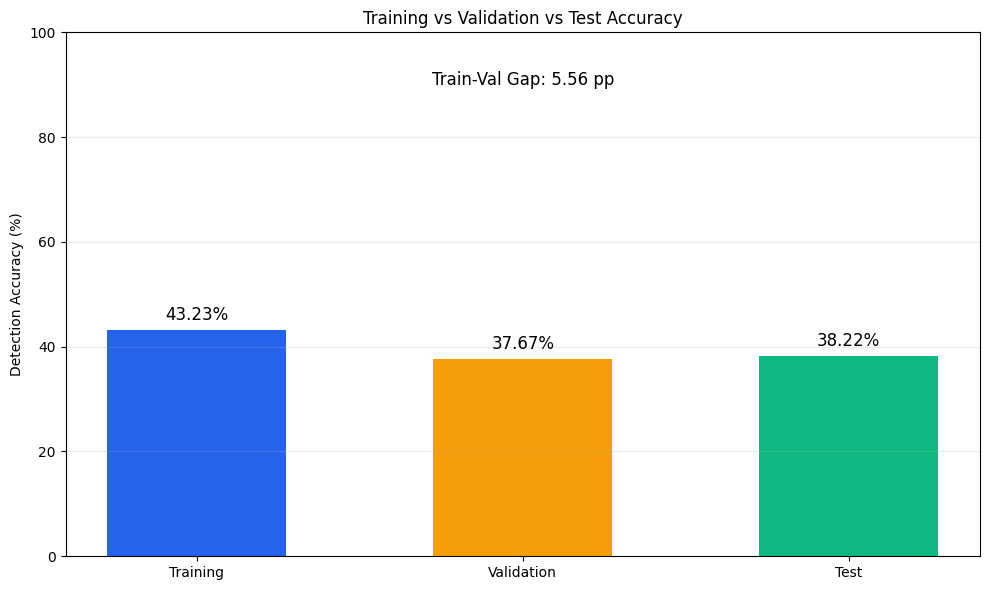

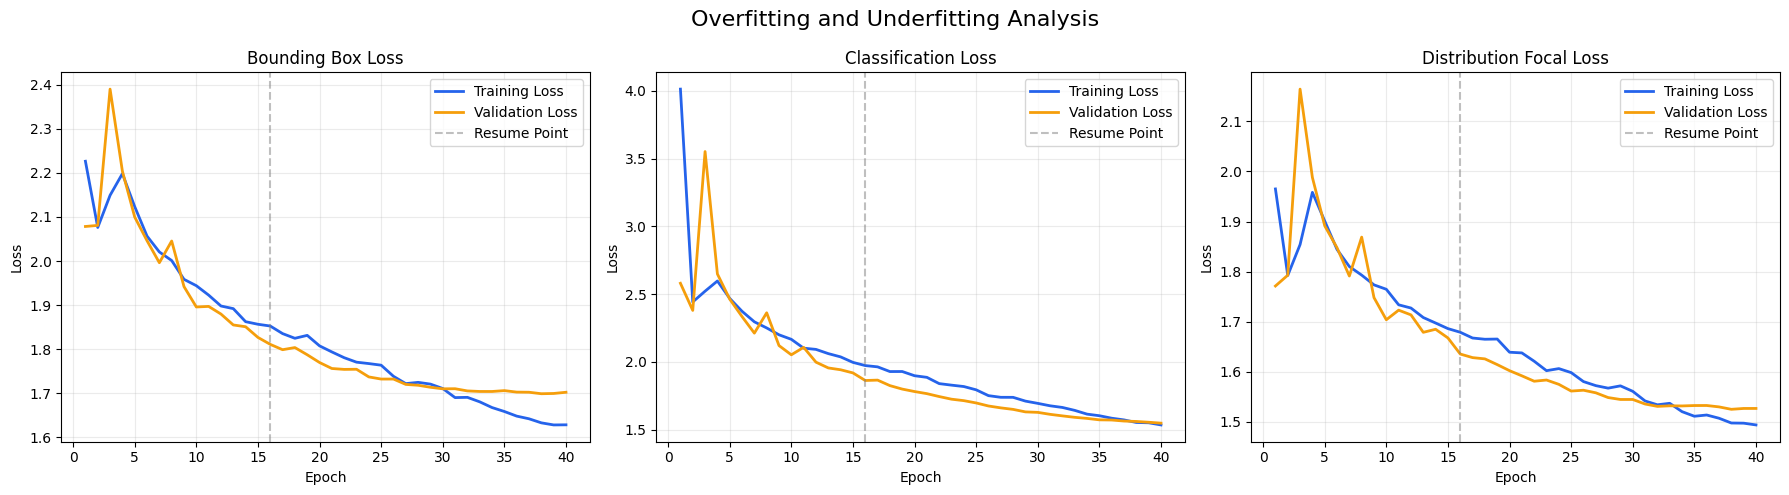

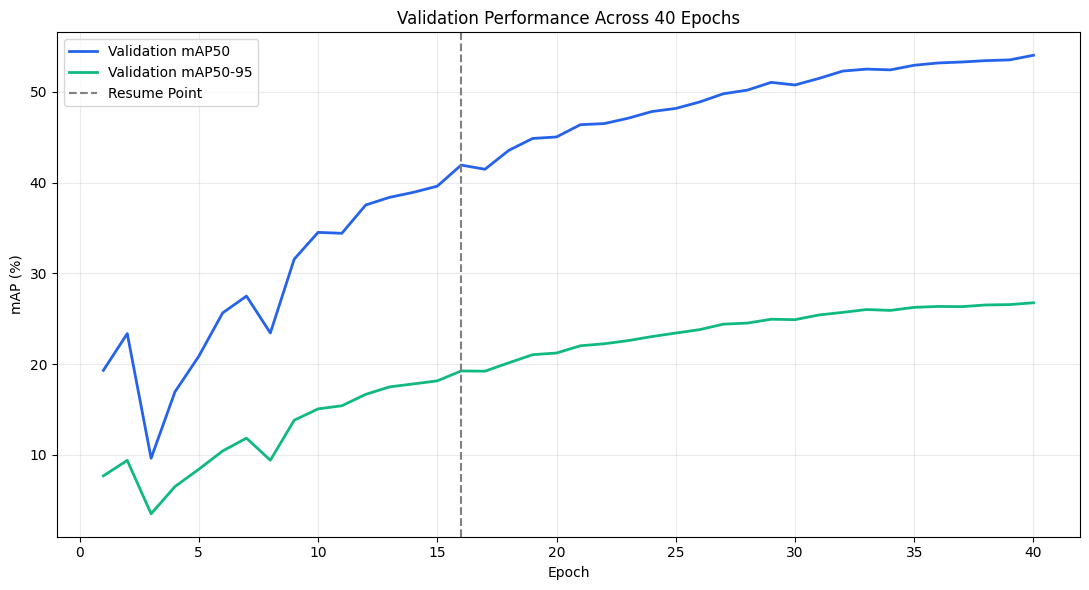


========== LOSS ANALYSIS ==========


,Loss Type,Training Epoch 1,Training Epoch 40,Validation Epoch 1,Validation Epoch 40
0,Bounding Box Loss,2.2266,1.6278,2.0784,1.7018
1,Classification Loss,4.0134,1.5344,2.5802,1.5476
2,Distribution Focal Loss,1.9651,1.4939,1.7713,1.5268



========== RECENT TRAINING TREND ==========
Validation mAP50-95 gain (Epochs 31-40): 1.344 pp

Recent loss trends:


,Loss Type,Training Loss Change,Validation Loss Change
0,Bounding Box Loss,-0.0618,-0.0080
1,Classification Loss,-0.1413,-0.0651
2,Distribution Focal Loss,-0.0479,-0.0089



========== SAVED ANALYSIS FILES ==========
generalization_analysis.json
generalization_gap.png
generalization_summary.csv
loss_summary.csv
recent_loss_trends.csv
train_vs_validation_loss.png
validation_map_learning_curve.png

Generalization analysis completed!
Ready for severity and maintenance assessment.


In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import json

from pathlib import Path

# ==========================================
# 1. Define Paths
# ==========================================

WORK_DIR = Path("/kaggle/working")

ANALYSIS_DIR = (
    WORK_DIR / "Model_Generalization_40_Epochs"
)

ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

ACCURACY_PATH = (
    WORK_DIR /
    "Detection_Accuracy_40_Epochs/"
    "overall_detection_accuracy.csv"
)

SGD_RESULTS_PATH = (
    WORK_DIR /
    "YOLO_Experiments/"
    "baseline_yolov8n_sgd-2/results.csv"
)

assert ACCURACY_PATH.exists()
assert SGD_RESULTS_PATH.exists()

# ==========================================
# 2. Load Accuracy and Training History
# ==========================================

accuracy_df = pd.read_csv(ACCURACY_PATH)

history_df = pd.read_csv(SGD_RESULTS_PATH)

history_df.columns = history_df.columns.str.strip()

assert len(history_df) == 40

accuracy_table = accuracy_df.set_index("Dataset")

train_accuracy = float(
    accuracy_table.loc[
        "Training", "Detection Accuracy (%)"
    ]
)

val_accuracy = float(
    accuracy_table.loc[
        "Validation", "Detection Accuracy (%)"
    ]
)

test_accuracy = float(
    accuracy_table.loc[
        "Test", "Detection Accuracy (%)"
    ]
)

generalization_gap = (
    train_accuracy - val_accuracy
)

val_test_gap = (
    test_accuracy - val_accuracy
)

# ==========================================
# 3. Generalization Summary
# ==========================================

print("========== GENERALIZATION ANALYSIS ==========")

print(f"Training Accuracy: {train_accuracy:.2f}%")
print(f"Validation Accuracy: {val_accuracy:.2f}%")
print(f"Test Accuracy: {test_accuracy:.2f}%")

print(
    f"\nTrain-Validation Gap: "
    f"{generalization_gap:.2f} pp"
)

print(
    f"Test-Validation Gap: "
    f"{val_test_gap:.2f} pp"
)

generalization_df = pd.DataFrame([
    {
        "Model": "YOLOv8n-SGD",
        "Completed Epochs": 40,
        "Training Accuracy (%)": train_accuracy,
        "Validation Accuracy (%)": val_accuracy,
        "Test Accuracy (%)": test_accuracy,
        "Train-Val Gap (pp)": generalization_gap,
        "Test-Val Gap (pp)": val_test_gap
    }
])

display(generalization_df.round(2))

generalization_df.to_csv(
    ANALYSIS_DIR / "generalization_summary.csv",
    index=False
)

# ==========================================
# 4. Accuracy Comparison Graph
# ==========================================

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    ["Training", "Validation", "Test"],
    [
        train_accuracy,
        val_accuracy,
        test_accuracy
    ],
    color=[
        "#2563EB",
        "#F59E0B",
        "#10B981"
    ],
    width=0.55
)

ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=4,
    fontsize=12
)

ax.set_title(
    "Training vs Validation vs Test Accuracy"
)

ax.set_ylabel("Detection Accuracy (%)")
ax.set_ylim(0, 100)

ax.text(
    0.5,
    0.90,
    f"Train-Val Gap: {generalization_gap:.2f} pp",
    transform=ax.transAxes,
    ha="center",
    fontsize=12
)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    ANALYSIS_DIR / "generalization_gap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 5. Training vs Validation Loss Curves
# ==========================================

loss_pairs = [
    (
        "train/box_loss",
        "val/box_loss",
        "Bounding Box Loss"
    ),
    (
        "train/cls_loss",
        "val/cls_loss",
        "Classification Loss"
    ),
    (
        "train/dfl_loss",
        "val/dfl_loss",
        "Distribution Focal Loss"
    )
]

fig, axes = plt.subplots(
    1, 3, figsize=(18, 5)
)

for ax, (train_col, val_col, title) in zip(
    axes, loss_pairs
):

    ax.plot(
        history_df["epoch"],
        history_df[train_col],
        label="Training Loss",
        color="#2563EB",
        linewidth=2
    )

    ax.plot(
        history_df["epoch"],
        history_df[val_col],
        label="Validation Loss",
        color="#F59E0B",
        linewidth=2
    )

    ax.axvline(
        16,
        linestyle="--",
        color="gray",
        alpha=0.5,
        label="Resume Point"
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.25)

fig.suptitle(
    "Overfitting and Underfitting Analysis",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    ANALYSIS_DIR / "train_vs_validation_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 6. Validation mAP Learning Curves
# ==========================================

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    history_df["epoch"],
    history_df["metrics/mAP50(B)"] * 100,
    label="Validation mAP50",
    color="#2563EB",
    linewidth=2
)

ax.plot(
    history_df["epoch"],
    history_df["metrics/mAP50-95(B)"] * 100,
    label="Validation mAP50-95",
    color="#10B981",
    linewidth=2
)

ax.axvline(
    16,
    color="gray",
    linestyle="--",
    label="Resume Point"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("mAP (%)")

ax.set_title(
    "Validation Performance Across 40 Epochs"
)

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    ANALYSIS_DIR / "validation_map_learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 7. Compare Losses Across Training
# ==========================================

loss_rows = []

for train_col, val_col, title in loss_pairs:

    loss_rows.append({
        "Loss Type": title,
        "Training Epoch 1": float(
            history_df[train_col].iloc[0]
        ),
        "Training Epoch 40": float(
            history_df[train_col].iloc[-1]
        ),
        "Validation Epoch 1": float(
            history_df[val_col].iloc[0]
        ),
        "Validation Epoch 40": float(
            history_df[val_col].iloc[-1]
        )
    })

loss_summary_df = pd.DataFrame(loss_rows)

print("\n========== LOSS ANALYSIS ==========")

display(loss_summary_df.round(4))

loss_summary_df.to_csv(
    ANALYSIS_DIR / "loss_summary.csv",
    index=False
)

# ==========================================
# 8. Check Recent Validation Trends
# ==========================================

recent_df = history_df.tail(10)

recent_map_gain = (
    recent_df["metrics/mAP50-95(B)"].iloc[-1]
    -
    recent_df["metrics/mAP50-95(B)"].iloc[0]
) * 100

print("\n========== RECENT TRAINING TREND ==========")

print(
    f"Validation mAP50-95 gain "
    f"(Epochs 31-40): {recent_map_gain:.3f} pp"
)

print("\nRecent loss trends:")

recent_loss_rows = []

for train_col, val_col, title in loss_pairs:

    train_change = (
        recent_df[train_col].iloc[-1]
        -
        recent_df[train_col].iloc[0]
    )

    val_change = (
        recent_df[val_col].iloc[-1]
        -
        recent_df[val_col].iloc[0]
    )

    recent_loss_rows.append({
        "Loss Type": title,
        "Training Loss Change": train_change,
        "Validation Loss Change": val_change
    })

recent_loss_df = pd.DataFrame(
    recent_loss_rows
)

display(recent_loss_df.round(4))

recent_loss_df.to_csv(
    ANALYSIS_DIR / "recent_loss_trends.csv",
    index=False
)

# ==========================================
# 9. Save Interpretation
# ==========================================

analysis_summary = {
    "model": "YOLOv8n-SGD",
    "completed_epochs": 40,
    "training_accuracy": train_accuracy,
    "validation_accuracy": val_accuracy,
    "test_accuracy": test_accuracy,
    "train_validation_gap_pp": generalization_gap,
    "test_validation_gap_pp": val_test_gap,
    "recent_validation_map_gain_pp": float(
        recent_map_gain
    ),
    "accuracy_definition": "TP / (TP + FP + FN)",
    "interpretation": (
        "The model shows a limited train-validation "
        "accuracy gap and consistent validation-test "
        "performance. Severe overfitting is not strongly "
        "supported by the available results. Moderate "
        "detection performance suggests room for "
        "additional learning and model improvement."
    ),
    "limitation": (
        "Endpoint accuracy alone cannot conclusively "
        "diagnose overfitting or underfitting. Training "
        "and validation loss trends and validation mAP "
        "must also be considered."
    )
}

with open(
    ANALYSIS_DIR / "generalization_analysis.json",
    "w"
) as f:

    json.dump(
        analysis_summary,
        f,
        indent=4
    )

# ==========================================
# 10. Final Verification
# ==========================================

print("\n========== SAVED ANALYSIS FILES ==========")

for path in sorted(ANALYSIS_DIR.iterdir()):
    print(path.name)

print("\nGeneralization analysis completed!")
print("Ready for severity and maintenance assessment.")

========== INPUT VERIFICATION ==========
Model: YOLOv8n-SGD
Completed epochs: 40
Test images: 2377
Saved detections: 4257

Damage types:


,Detections
Damage Type,
Longitudinal Crack,1995
Transverse Crack,968
Alligator Crack,912
Pothole,382



========== RULE VERIFICATION ==========


,Damage Type,Area (%),Expected Severity,Actual Severity,Priority,Status
0,Longitudinal Crack,1.0,Low,Low,Routine,PASS
1,Longitudinal Crack,2.0,Medium,Medium,Scheduled,PASS
2,Longitudinal Crack,5.0,High,High,Urgent,PASS
3,Transverse Crack,1.0,Low,Low,Routine,PASS
4,Transverse Crack,2.0,Medium,Medium,Scheduled,PASS
5,Transverse Crack,5.0,High,High,Urgent,PASS
6,Alligator Crack,1.5,Low,Low,Scheduled,PASS
7,Alligator Crack,3.0,Medium,Medium,Urgent,PASS
8,Alligator Crack,8.0,High,High,Critical,PASS
9,Pothole,0.5,Low,Low,Scheduled,PASS



========== DAMAGE ASSESSMENT ==========


,Image Name,Damage Type,Confidence (%),Damage Area (%),Severity,Maintenance Priority
0,China_Drone_000010.jpg,Longitudinal Crack,80.03,1.34,Low,Routine
1,China_Drone_000010.jpg,Longitudinal Crack,62.16,3.10,Medium,Scheduled
2,China_Drone_000022.jpg,Longitudinal Crack,66.99,4.45,Medium,Scheduled
3,China_Drone_000022.jpg,Transverse Crack,45.43,4.79,Medium,Scheduled
4,China_Drone_000022.jpg,Alligator Crack,26.98,5.16,Medium,Urgent
5,China_Drone_000055.jpg,Longitudinal Crack,63.62,7.60,High,Urgent
6,China_Drone_000057.jpg,Pothole,80.08,0.69,Low,Scheduled
7,China_Drone_000057.jpg,Pothole,77.44,0.55,Low,Scheduled
8,China_Drone_000079.jpg,Longitudinal Crack,46.29,9.16,High,Urgent
9,China_Drone_000079.jpg,Longitudinal Crack,39.70,14.03,High,Urgent


... (4 outputs left out)


========== PRIORITY DISTRIBUTION ==========


,Maintenance Priority,Count,Percentage (%)
0,Routine,1622,38.1
1,Scheduled,1124,26.4
2,Urgent,864,20.3
3,Critical,647,15.2



========== IMAGE-LEVEL SUMMARY ==========
Total images: 2377
Images with detected damage: 2012
Images with no detections: 365


,Image Name,Image Path,Detection Status,Total Detections,Low Severity Count,Medium Severity Count,High Severity Count,Critical Damage Count,Highest Severity,Highest Priority,Priority Score,Highest Priority Damage Type,Highest Priority Area (%),Average Confidence (%)
0,China_Drone_000010.jpg,/kaggle/input/datasets/ammritkumaar/rdd2022-pr...,Damage Detected,2,1,1,0,0,Medium,Scheduled,2,Longitudinal Crack,3.10,71.09
1,China_Drone_000022.jpg,/kaggle/input/datasets/ammritkumaar/rdd2022-pr...,Damage Detected,3,0,3,0,0,Medium,Urgent,3,Alligator Crack,5.16,46.47
2,China_Drone_000055.jpg,/kaggle/input/datasets/ammritkumaar/rdd2022-pr...,Damage Detected,1,0,0,1,0,High,Urgent,3,Longitudinal Crack,7.60,63.62
3,China_Drone_000057.jpg,/kaggle/input/datasets/ammritkumaar/rdd2022-pr...,Damage Detected,2,2,0,0,0,Low,Scheduled,2,Pothole,0.69,78.76
4,China_Drone_000079.jpg,/kaggle/input/datasets/ammritkumaar/rdd2022-pr...,Damage Detected,4,1,1,2,0,High,Urgent,3,Longitudinal Crack,14.03,36.49
5,China_Drone_000094.jpg,/kaggle/input/datasets/ammritkumaar/rdd2022-pr...,Damage Detected,1,0,1,0,0,Medium,Scheduled,2,Transverse Crack,2.67,73.39
6,China_Drone_000098.jpg,/kaggle/input/datasets/ammritkumaar/rdd2022-pr...,Damage Detected,1,0,0,1,0,High,Urgent,3,Longitudinal Crack,5.13,45.24
7,China_Drone_000112.jpg,/kaggle/input/datasets/ammritkumaar/rdd2022-pr...,Damage Detected,3,3,0,0,0,Low,Routine,1,Longitudinal Crack,1.35,51.25
8,China_Drone_000113.jpg,/kaggle/input/datasets/ammritkumaar/rdd2022-pr...,Damage Detected,3,2,1,0,0,Medium,Scheduled,2,Longitudinal Crack,2.83,46.74
9,China_Drone_000158.jpg,/kaggle/input/datasets/ammritkumaar/rdd2022-pr...,Damage Detected,1,0,1,0,0,Medium,Scheduled,2,Transverse Crack,4.10,70.02


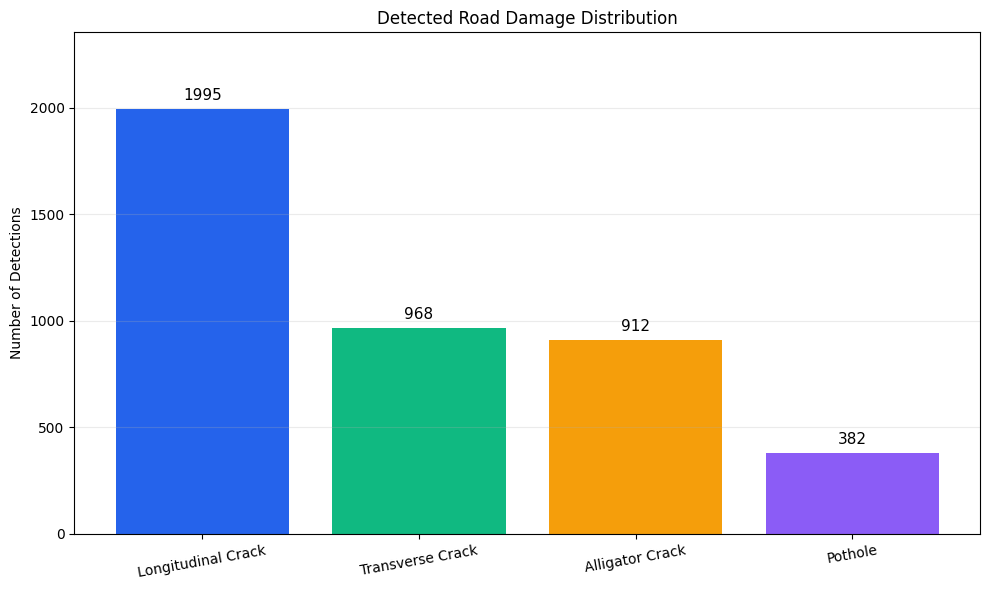

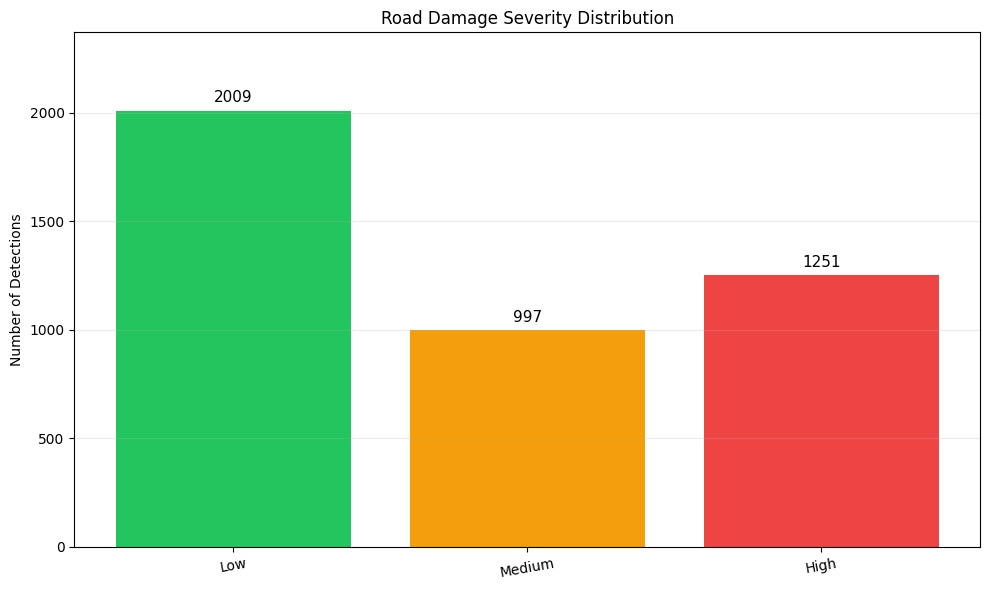

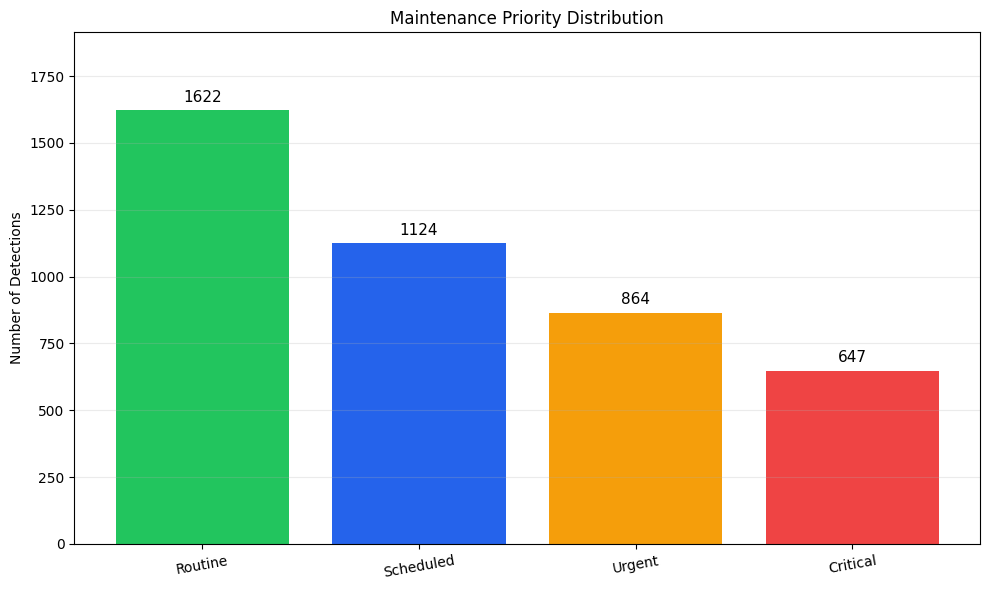

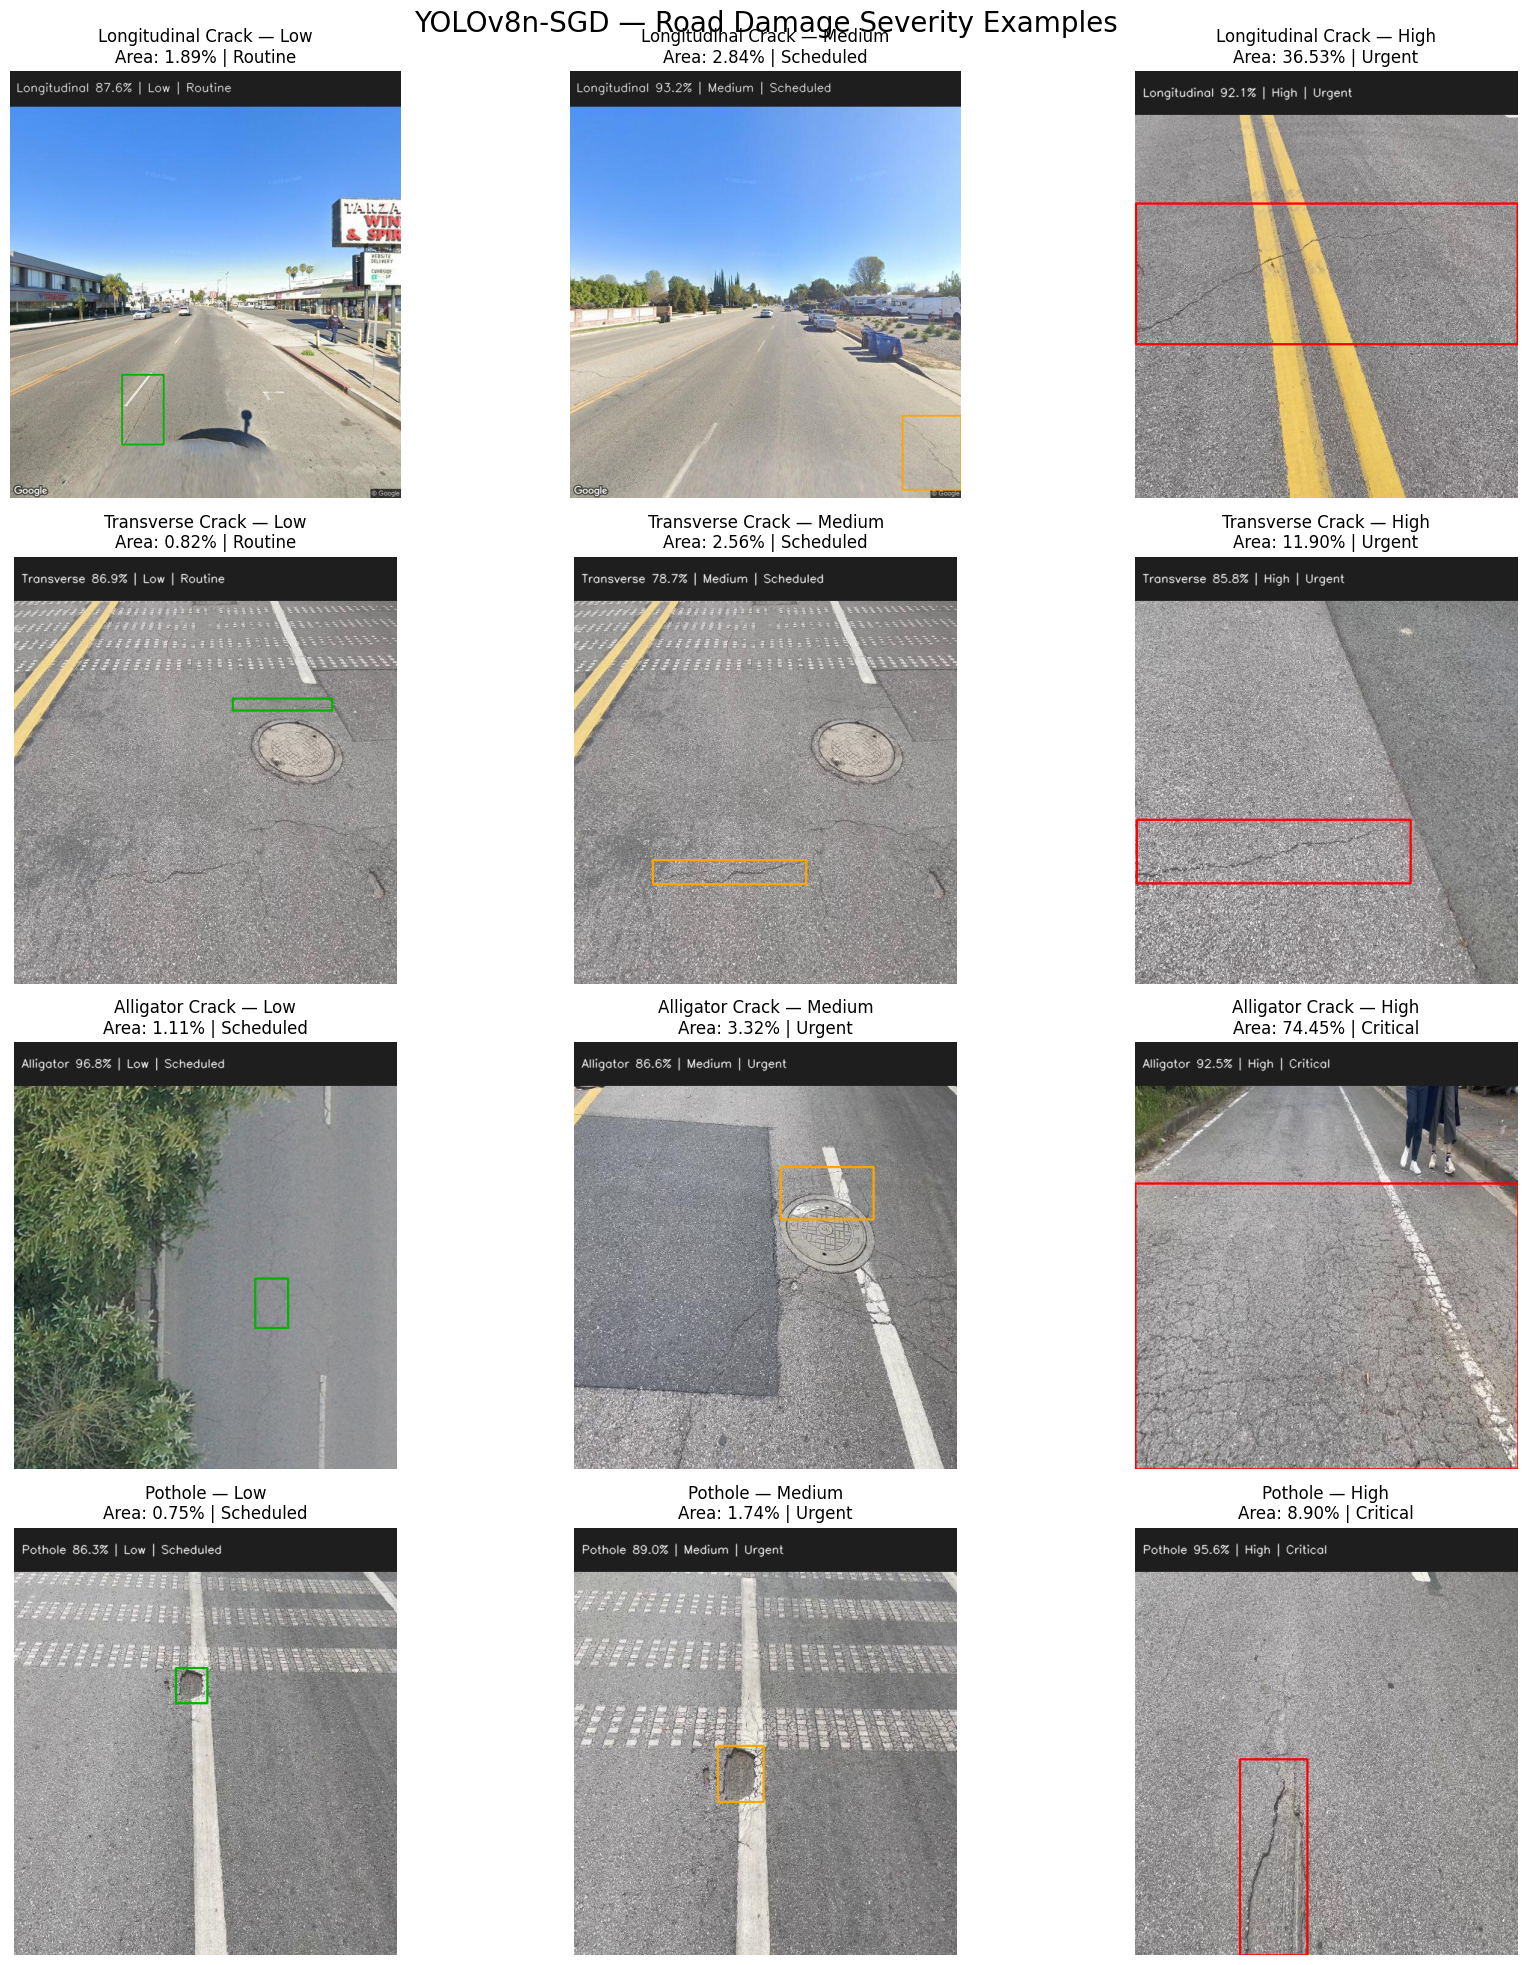


========== FINAL SEVERITY SUMMARY ==========
Model: YOLOv8n-SGD
Completed epochs: 40
Total test images: 2377
Total assessed detections: 4257
Images with detections: 2012
Images without detections: 365

Severity counts:
Severity
Low       2009
High      1251
Medium     997
Name: count, dtype: int64

Maintenance priority counts:
Maintenance Priority
Routine      1622
Scheduled    1124
Urgent        864
Critical      647
Name: count, dtype: int64

Annotated samples: 12

========== SAVED REPORTS ==========
damage_assessment_report.csv
damage_type_distribution.csv
image_level_summary.csv
maintenance_priority_rules.csv
priority_distribution.csv
processing_summary.json
rule_verification.csv
severity_distribution.csv
severity_priority_config.json
severity_thresholds.csv
visualization_samples.csv

========== SAVED GRAPHS ==========
damage_type_distribution.png
priority_distribution.png
road_damage_severity_visualization.png
severity_distribution.png

Severity assessment completed!
Maintenance 

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
import json

from pathlib import Path

# ==========================================
# 1. Define Paths
# ==========================================

WORK_DIR = Path("/kaggle/working")

ACCURACY_DIR = (
    WORK_DIR / "Detection_Accuracy_40_Epochs"
)

SEVERITY_DIR = (
    WORK_DIR /
    "Severity_Maintenance_Prioritization_40_Epochs"
)

REPORTS_DIR = SEVERITY_DIR / "Reports"
GRAPHS_DIR = SEVERITY_DIR / "Graphs"
PREDICTIONS_DIR = SEVERITY_DIR / "Predictions"

ANNOTATED_DIR = (
    PREDICTIONS_DIR / "Annotated_Images"
)

for folder in [
    REPORTS_DIR,
    GRAPHS_DIR,
    ANNOTATED_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# ==========================================
# 2. Load Saved Test Predictions
# ==========================================

damage_df = pd.read_csv(
    ACCURACY_DIR / "test_predictions.csv"
)

test_image_summary_df = pd.read_csv(
    ACCURACY_DIR / "test_image_summary.csv"
)

assert len(damage_df) == 4257
assert len(test_image_summary_df) == 2377

assert (
    test_image_summary_df["Total Detections"].sum()
    == len(damage_df)
)

print("========== INPUT VERIFICATION ==========")

print("Model: YOLOv8n-SGD")
print("Completed epochs: 40")
print("Test images:", len(test_image_summary_df))
print("Saved detections:", len(damage_df))

print("\nDamage types:")

display(
    damage_df["Damage Type"]
    .value_counts()
    .rename("Detections")
    .to_frame()
)

# ==========================================
# 3. Define Severity Thresholds
# ==========================================

CLASS_NAMES = {
    0: "Longitudinal Crack",
    1: "Transverse Crack",
    2: "Alligator Crack",
    3: "Pothole"
}

SEVERITY_THRESHOLDS = {
    0: {"medium": 2.0, "high": 5.0},
    1: {"medium": 2.0, "high": 5.0},
    2: {"medium": 3.0, "high": 8.0},
    3: {"medium": 1.0, "high": 3.0}
}

SEVERITY_SCORES = {
    "Low": 1,
    "Medium": 2,
    "High": 3
}

PRIORITY_RULES = {
    0: {
        "Low": "Routine",
        "Medium": "Scheduled",
        "High": "Urgent"
    },
    1: {
        "Low": "Routine",
        "Medium": "Scheduled",
        "High": "Urgent"
    },
    2: {
        "Low": "Scheduled",
        "Medium": "Urgent",
        "High": "Critical"
    },
    3: {
        "Low": "Scheduled",
        "Medium": "Urgent",
        "High": "Critical"
    }
}

PRIORITY_SCORES = {
    "Routine": 1,
    "Scheduled": 2,
    "Urgent": 3,
    "Critical": 4
}

# ==========================================
# 4. Define Severity Functions
# ==========================================

def calculate_severity(class_id, area_percent):

    thresholds = SEVERITY_THRESHOLDS[class_id]

    if area_percent >= thresholds["high"]:
        return "High"

    elif area_percent >= thresholds["medium"]:
        return "Medium"

    else:
        return "Low"


def calculate_priority(class_id, severity):

    return PRIORITY_RULES[class_id][severity]

# ==========================================
# 5. Verify Severity Rules
# ==========================================

rule_test_rows = []

for class_id, thresholds in (
    SEVERITY_THRESHOLDS.items()
):

    test_cases = [
        (thresholds["medium"] / 2, "Low"),
        (thresholds["medium"], "Medium"),
        (thresholds["high"], "High")
    ]

    for area, expected in test_cases:

        actual = calculate_severity(
            class_id, area
        )

        assert actual == expected

        rule_test_rows.append({
            "Damage Type": CLASS_NAMES[class_id],
            "Area (%)": area,
            "Expected Severity": expected,
            "Actual Severity": actual,
            "Priority": calculate_priority(
                class_id, actual
            ),
            "Status": "PASS"
        })

rule_verification_df = pd.DataFrame(
    rule_test_rows
)

print("\n========== RULE VERIFICATION ==========")

display(rule_verification_df)

rule_verification_df.to_csv(
    REPORTS_DIR / "rule_verification.csv",
    index=False
)

# ==========================================
# 6. Calculate Severity and Priority
# ==========================================

damage_df["Severity"] = damage_df.apply(
    lambda row: calculate_severity(
        int(row["Class ID"]),
        float(row["Damage Area (%)"])
    ),
    axis=1
)

damage_df["Severity Score"] = (
    damage_df["Severity"].map(SEVERITY_SCORES)
)

damage_df["Maintenance Priority"] = (
    damage_df.apply(
        lambda row: calculate_priority(
            int(row["Class ID"]),
            row["Severity"]
        ),
        axis=1
    )
)

damage_df["Priority Score"] = (
    damage_df["Maintenance Priority"]
    .map(PRIORITY_SCORES)
)

assert damage_df["Severity"].notna().all()

assert damage_df[
    "Maintenance Priority"
].notna().all()

assert len(damage_df) == 4257

print("\n========== DAMAGE ASSESSMENT ==========")

display(
    damage_df[[
        "Image Name",
        "Damage Type",
        "Confidence (%)",
        "Damage Area (%)",
        "Severity",
        "Maintenance Priority"
    ]].head(15).round(2)
)

damage_df.to_csv(
    REPORTS_DIR / "damage_assessment_report.csv",
    index=False
)

# ==========================================
# 7. Generate Distribution Tables
# ==========================================

damage_distribution_df = (
    damage_df["Damage Type"]
    .value_counts()
    .rename_axis("Damage Type")
    .reset_index(name="Count")
)

severity_distribution_df = (
    damage_df["Severity"]
    .value_counts()
    .reindex(["Low", "Medium", "High"], fill_value=0)
    .rename_axis("Severity")
    .reset_index(name="Count")
)

priority_distribution_df = (
    damage_df["Maintenance Priority"]
    .value_counts()
    .reindex(
        ["Routine", "Scheduled", "Urgent", "Critical"],
        fill_value=0
    )
    .rename_axis("Maintenance Priority")
    .reset_index(name="Count")
)

for table in [
    damage_distribution_df,
    severity_distribution_df,
    priority_distribution_df
]:

    table["Percentage (%)"] = (
        table["Count"] / len(damage_df) * 100
    )

    assert table["Count"].sum() == 4257

print("\n========== DAMAGE DISTRIBUTION ==========")

display(damage_distribution_df.round(2))

print("\n========== SEVERITY DISTRIBUTION ==========")

display(severity_distribution_df.round(2))

print("\n========== PRIORITY DISTRIBUTION ==========")

display(priority_distribution_df.round(2))

damage_distribution_df.to_csv(
    REPORTS_DIR / "damage_type_distribution.csv",
    index=False
)

severity_distribution_df.to_csv(
    REPORTS_DIR / "severity_distribution.csv",
    index=False
)

priority_distribution_df.to_csv(
    REPORTS_DIR / "priority_distribution.csv",
    index=False
)

# ==========================================
# 8. Generate Image-Level Summary
# ==========================================

image_rows = []

grouped_damages = {
    name: group
    for name, group in damage_df.groupby(
        "Image Name"
    )
}

for _, image in test_image_summary_df.iterrows():

    image_name = image["Image Name"]

    group = grouped_damages.get(image_name)

    # Images with no model detections
    if group is None:

        image_rows.append({
            "Image Name": image_name,
            "Image Path": image["Image Path"],
            "Detection Status": "No Damage Detected",
            "Total Detections": 0,
            "Low Severity Count": 0,
            "Medium Severity Count": 0,
            "High Severity Count": 0,
            "Critical Damage Count": 0,
            "Highest Severity": "Not Assessed",
            "Highest Priority": "Not Assessed",
            "Priority Score": 0,
            "Highest Priority Damage Type": "None",
            "Highest Priority Area (%)": 0.0,
            "Average Confidence (%)": 0.0
        })

        continue

    # Highest priority detection in the image
    top_damage = group.sort_values(
        [
            "Priority Score",
            "Severity Score",
            "Damage Area (%)",
            "Confidence (%)"
        ],
        ascending=False
    ).iloc[0]

    highest_severity = group.sort_values(
        "Severity Score",
        ascending=False
    ).iloc[0]["Severity"]

    image_rows.append({
        "Image Name": image_name,
        "Image Path": image["Image Path"],
        "Detection Status": "Damage Detected",
        "Total Detections": len(group),
        "Low Severity Count": int(
            (group["Severity"] == "Low").sum()
        ),
        "Medium Severity Count": int(
            (group["Severity"] == "Medium").sum()
        ),
        "High Severity Count": int(
            (group["Severity"] == "High").sum()
        ),
        "Critical Damage Count": int(
            (
                group["Maintenance Priority"]
                == "Critical"
            ).sum()
        ),
        "Highest Severity": highest_severity,
        "Highest Priority": top_damage[
            "Maintenance Priority"
        ],
        "Priority Score": int(
            top_damage["Priority Score"]
        ),
        "Highest Priority Damage Type": top_damage[
            "Damage Type"
        ],
        "Highest Priority Area (%)": float(
            top_damage["Damage Area (%)"]
        ),
        "Average Confidence (%)": float(
            group["Confidence (%)"].mean()
        )
    })

image_summary_df = pd.DataFrame(image_rows)

assert len(image_summary_df) == 2377

assert (
    image_summary_df["Total Detections"].sum()
    == 4257
)

images_with_damage = int(
    (
        image_summary_df["Total Detections"] > 0
    ).sum()
)

images_without_damage = int(
    (
        image_summary_df["Total Detections"] == 0
    ).sum()
)

print("\n========== IMAGE-LEVEL SUMMARY ==========")

print("Total images:", len(image_summary_df))

print(
    "Images with detected damage:",
    images_with_damage
)

print(
    "Images with no detections:",
    images_without_damage
)

display(image_summary_df.head(10).round(2))

image_summary_df.to_csv(
    REPORTS_DIR / "image_level_summary.csv",
    index=False
)

# ==========================================
# 9. Save Severity and Priority Rules
# ==========================================

threshold_rows = []

for class_id, thresholds in (
    SEVERITY_THRESHOLDS.items()
):

    threshold_rows.append({
        "Damage Type": CLASS_NAMES[class_id],
        "Medium Threshold (%)": thresholds["medium"],
        "High Threshold (%)": thresholds["high"]
    })

pd.DataFrame(threshold_rows).to_csv(
    REPORTS_DIR / "severity_thresholds.csv",
    index=False
)

priority_rule_rows = []

for class_id, rules in PRIORITY_RULES.items():

    for severity, priority in rules.items():

        priority_rule_rows.append({
            "Damage Type": CLASS_NAMES[class_id],
            "Severity": severity,
            "Maintenance Priority": priority
        })

pd.DataFrame(priority_rule_rows).to_csv(
    REPORTS_DIR / "maintenance_priority_rules.csv",
    index=False
)

# ==========================================
# 10. Generate Distribution Graphs
# ==========================================

def save_distribution_graph(
    df, category, title, filename, colors
):

    fig, ax = plt.subplots(figsize=(10, 6))

    bars = ax.bar(
        df[category],
        df["Count"],
        color=colors
    )

    ax.bar_label(
        bars,
        padding=4,
        fontsize=11
    )

    ax.set_title(title)
    ax.set_ylabel("Number of Detections")

    ax.set_ylim(
        0,
        max(df["Count"]) * 1.18
    )

    ax.tick_params(axis="x", rotation=10)
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()

    plt.savefig(
        GRAPHS_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


save_distribution_graph(
    damage_distribution_df,
    "Damage Type",
    "Detected Road Damage Distribution",
    "damage_type_distribution.png",
    ["#2563EB", "#10B981", "#F59E0B", "#8B5CF6"]
)

save_distribution_graph(
    severity_distribution_df,
    "Severity",
    "Road Damage Severity Distribution",
    "severity_distribution.png",
    ["#22C55E", "#F59E0B", "#EF4444"]
)

save_distribution_graph(
    priority_distribution_df,
    "Maintenance Priority",
    "Maintenance Priority Distribution",
    "priority_distribution.png",
    ["#22C55E", "#2563EB", "#F59E0B", "#EF4444"]
)

# ==========================================
# 11. Annotated Prediction Samples
# ==========================================

SEVERITY_COLORS = {
    "Low": (0, 180, 0),
    "Medium": (0, 165, 255),
    "High": (0, 0, 255)
}

SHORT_NAMES = {
    "Longitudinal Crack": "Longitudinal",
    "Transverse Crack": "Transverse",
    "Alligator Crack": "Alligator",
    "Pothole": "Pothole"
}

sample_rows = []

fig, axes = plt.subplots(
    4, 3, figsize=(18, 20)
)

for class_id in range(4):

    for severity_index, severity in enumerate(
        ["Low", "Medium", "High"]
    ):

        ax = axes[class_id, severity_index]

        candidates = damage_df[
            (damage_df["Class ID"] == class_id)
            &
            (damage_df["Severity"] == severity)
        ]

        if candidates.empty:

            ax.set_title(
                f"{CLASS_NAMES[class_id]} — {severity}"
            )

            ax.text(
                0.5, 0.5,
                "No sample available",
                ha="center",
                va="center"
            )

            ax.axis("off")
            continue

        # Select high-confidence example
        sample = candidates.sort_values(
            "Confidence (%)",
            ascending=False
        ).iloc[0]

        image_path = Path(sample["Image Path"])

        image = cv2.imread(str(image_path))

        if image is None:

            ax.set_title("Image unavailable")
            ax.axis("off")
            continue

        # Draw selected detection
        x1, y1, x2, y2 = [
            int(sample[column])
            for column in ["X1", "Y1", "X2", "Y2"]
        ]

        color = SEVERITY_COLORS[severity]

        thickness = max(
            2, round(image.shape[1] / 400)
        )

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            color,
            thickness
        )

        label = (
            f"{SHORT_NAMES[sample['Damage Type']]} "
            f"{sample['Confidence (%)']:.1f}% | "
            f"{severity} | "
            f"{sample['Maintenance Priority']}"
        )

        # Add readable caption above image
        header_height = 60

        image = cv2.copyMakeBorder(
            image,
            header_height, 0, 0, 0,
            cv2.BORDER_CONSTANT,
            value=(30, 30, 30)
        )

        font_scale = max(
            0.35,
            min(0.8, image.shape[1] / 1000)
        )

        cv2.putText(
            image,
            label,
            (10, 35),
            cv2.FONT_HERSHEY_SIMPLEX,
            font_scale,
            (255, 255, 255),
            1,
            cv2.LINE_AA
        )

        filename = (
            f"class_{class_id}_{severity.lower()}_"
            f"{image_path.stem}.jpg"
        )

        output_path = ANNOTATED_DIR / filename

        saved = cv2.imwrite(
            str(output_path), image
        )

        assert saved

        ax.imshow(
            cv2.cvtColor(
                image,
                cv2.COLOR_BGR2RGB
            )
        )

        ax.set_title(
            f"{CLASS_NAMES[class_id]} — {severity}\n"
            f"Area: {sample['Damage Area (%)']:.2f}% | "
            f"{sample['Maintenance Priority']}"
        )

        ax.axis("off")

        sample_rows.append({
            "Image Name": sample["Image Name"],
            "Damage Type": sample["Damage Type"],
            "Confidence (%)": float(
                sample["Confidence (%)"]
            ),
            "Damage Area (%)": float(
                sample["Damage Area (%)"]
            ),
            "Severity": severity,
            "Maintenance Priority": sample[
                "Maintenance Priority"
            ],
            "Annotated Image": str(output_path)
        })

fig.suptitle(
    "YOLOv8n-SGD — Road Damage Severity Examples",
    fontsize=20
)

plt.tight_layout()

plt.savefig(
    GRAPHS_DIR /
    "road_damage_severity_visualization.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

visualization_samples_df = pd.DataFrame(
    sample_rows
)

visualization_samples_df.to_csv(
    REPORTS_DIR / "visualization_samples.csv",
    index=False
)

# ==========================================
# 12. Save Configuration and Summary
# ==========================================

severity_config = {
    "model": "YOLOv8n-SGD",
    "completed_epochs": 40,
    "severity_method": (
        "Class-specific normalized bounding box area"
    ),
    "area_formula": (
        "Bounding box area / Image area * 100"
    ),
    "severity_thresholds": SEVERITY_THRESHOLDS,
    "priority_rules": PRIORITY_RULES,
    "priority_scores": PRIORITY_SCORES,
    "confidence_threshold": 0.25,
    "limitation": (
        "Heuristic severity estimates are not "
        "validated physical damage measurements. "
        "No detections does not guarantee a "
        "damage-free road."
    )
}

with open(
    REPORTS_DIR / "severity_priority_config.json",
    "w"
) as f:

    json.dump(severity_config, f, indent=4)

processing_summary = {
    "model": "YOLOv8n-SGD",
    "completed_epochs": 40,
    "test_images": 2377,
    "total_detections": 4257,
    "images_with_detections": images_with_damage,
    "images_without_detections": images_without_damage,
    "severity_distribution": {
        row["Severity"]: int(row["Count"])
        for _, row in severity_distribution_df.iterrows()
    },
    "priority_distribution": {
        row["Maintenance Priority"]: int(row["Count"])
        for _, row in priority_distribution_df.iterrows()
    },
    "annotated_samples": len(sample_rows)
}

with open(
    REPORTS_DIR / "processing_summary.json",
    "w"
) as f:

    json.dump(processing_summary, f, indent=4)

# ==========================================
# 13. Final Verification
# ==========================================

print("\n========== FINAL SEVERITY SUMMARY ==========")

print("Model: YOLOv8n-SGD")
print("Completed epochs: 40")
print("Total test images: 2377")
print("Total assessed detections: 4257")

print(
    "Images with detections:",
    images_with_damage
)

print(
    "Images without detections:",
    images_without_damage
)

print("\nSeverity counts:")

print(
    damage_df["Severity"].value_counts()
)

print("\nMaintenance priority counts:")

print(
    damage_df[
        "Maintenance Priority"
    ].value_counts()
)

print(
    "\nAnnotated samples:",
    len(sample_rows)
)

print("\n========== SAVED REPORTS ==========")

for path in sorted(REPORTS_DIR.iterdir()):
    print(path.name)

print("\n========== SAVED GRAPHS ==========")

for path in sorted(GRAPHS_DIR.iterdir()):
    print(path.name)

print("\nSeverity assessment completed!")
print("Maintenance priority assigned to all detections.")
print("Ready for final maintenance ranking.")

========== INPUT VERIFICATION ==========
Model: YOLOv8n-SGD
Completed epochs: 40
Total images: 2377
Total detections: 4257

Images eligible for ranking: 2012
Images requiring manual review: 365

========== TOP 10 MAINTENANCE PRIORITIES ==========


,Maintenance Rank,Image Name,Highest Priority,Highest Priority Damage Type,Critical Damage Count,High Severity Count,Total Detections,Highest Priority Area (%)
0,1,United_States_001405.jpg,Critical,Alligator Crack,4,4,4,31.84
1,2,United_States_003282.jpg,Critical,Alligator Crack,3,3,4,28.97
2,3,Japan_004433.jpg,Critical,Alligator Crack,3,3,4,27.80
3,4,India_008728.jpg,Critical,Alligator Crack,3,3,4,22.79
4,5,Japan_010309.jpg,Critical,Alligator Crack,3,3,4,22.78
5,6,Japan_006677.jpg,Critical,Alligator Crack,3,3,4,19.84
6,7,Japan_012178.jpg,Critical,Alligator Crack,3,3,3,61.76
7,8,Japan_010555.jpg,Critical,Alligator Crack,3,3,3,50.97
8,9,Japan_009776.jpg,Critical,Alligator Crack,3,3,3,48.40
9,10,Japan_007028.jpg,Critical,Alligator Crack,3,3,3,38.02



Manual review report saved.

========== IMAGE-LEVEL PRIORITY ==========


,Maintenance Priority,Images,Percentage (%)
0,Critical,548,23.05
1,Urgent,567,23.85
2,Scheduled,485,20.40
3,Routine,412,17.33
4,Not Assessed,365,15.36



========== DAMAGE-LEVEL PRIORITY ==========


,Maintenance Priority,Detections,Percentage (%)
0,Critical,647,15.2
1,Urgent,864,20.3
2,Scheduled,1124,26.4
3,Routine,1622,38.1



========== CLASS-WISE SEVERITY ==========


Severity,Low,Medium,High,Total
Damage Type,,,,
Longitudinal Crack,957,545,493,1995
Transverse Crack,665,192,111,968
Alligator Crack,107,204,601,912
Pothole,280,56,46,382


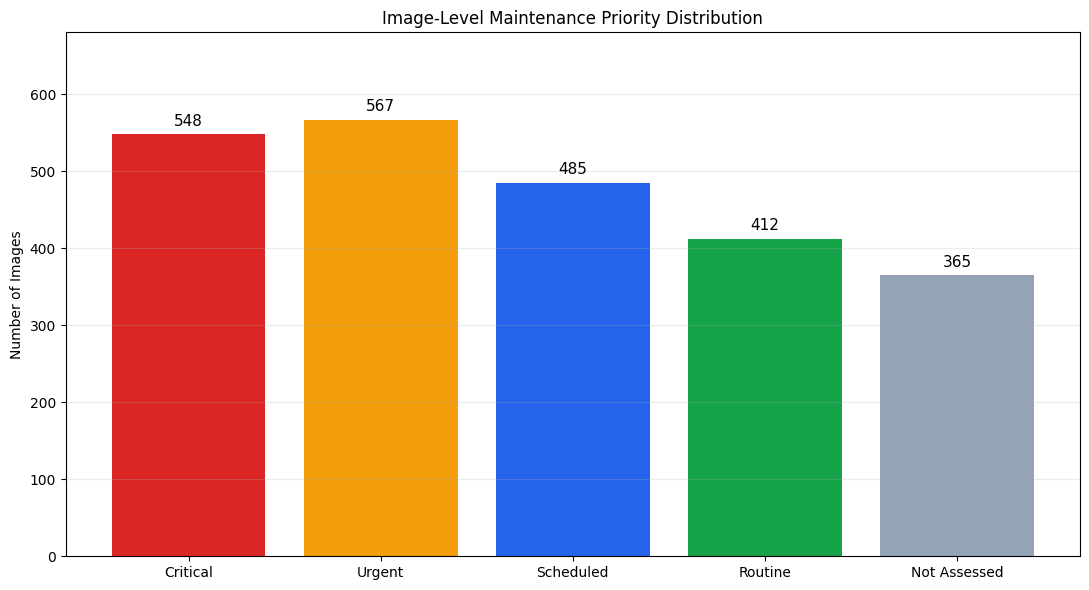

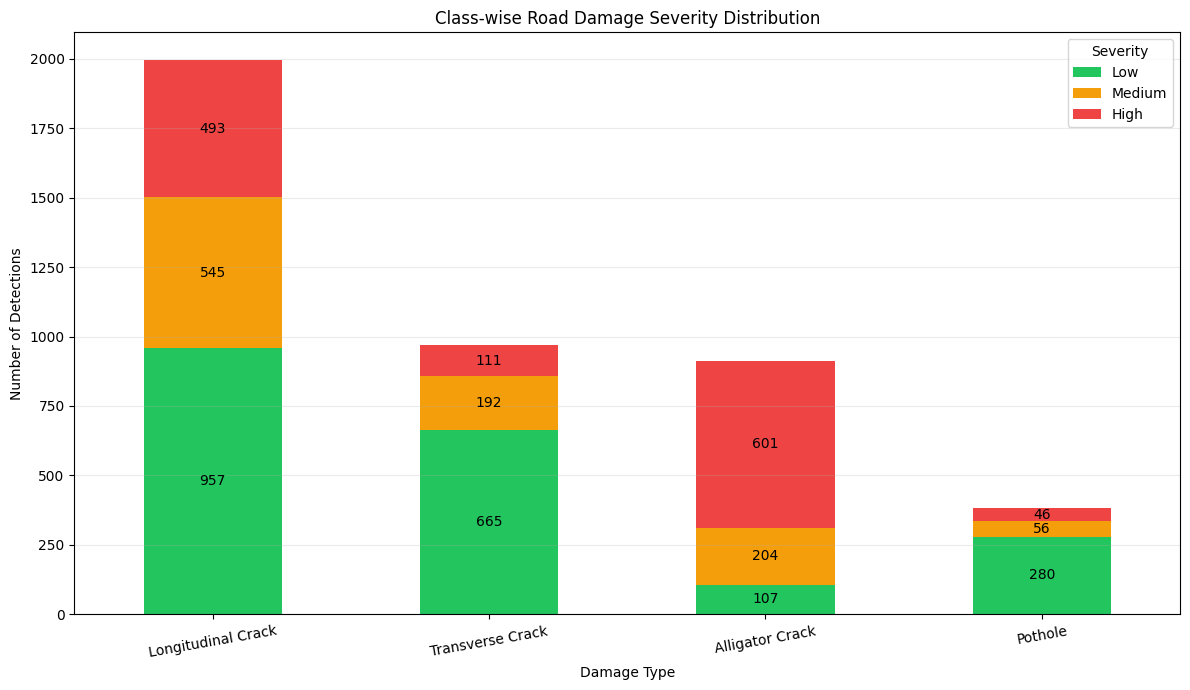

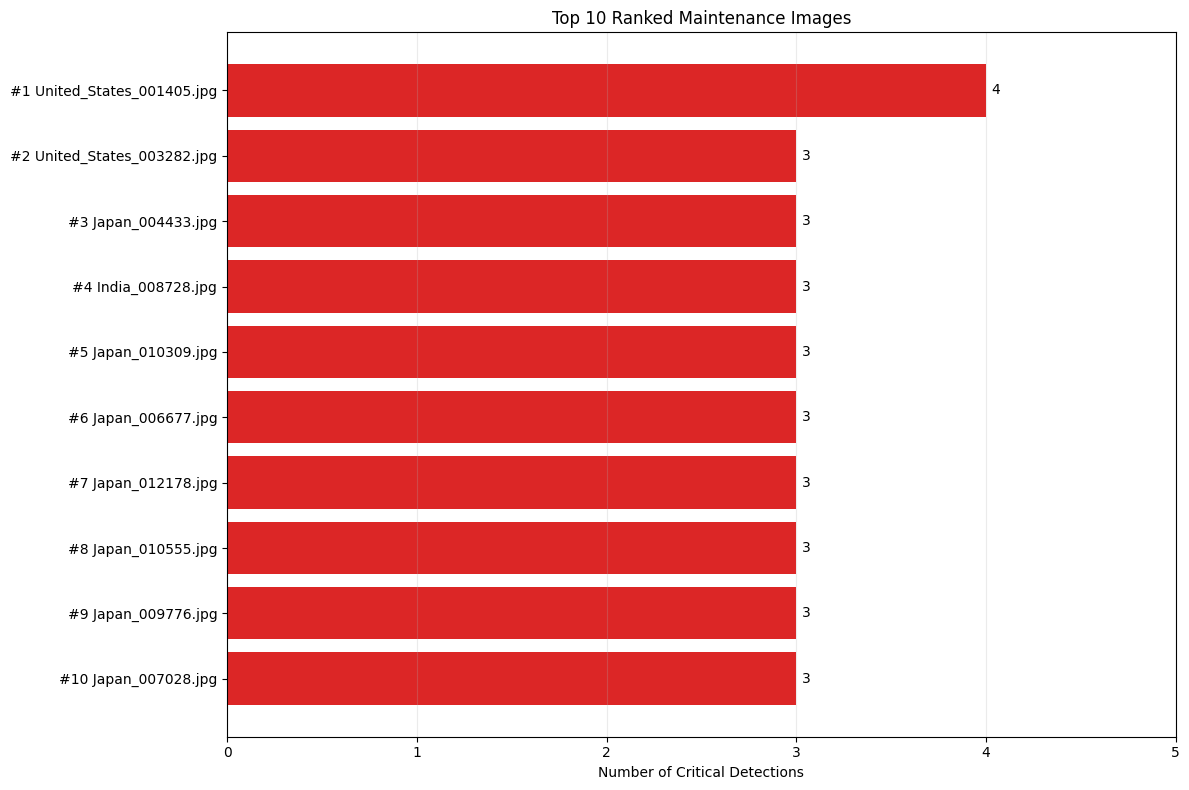

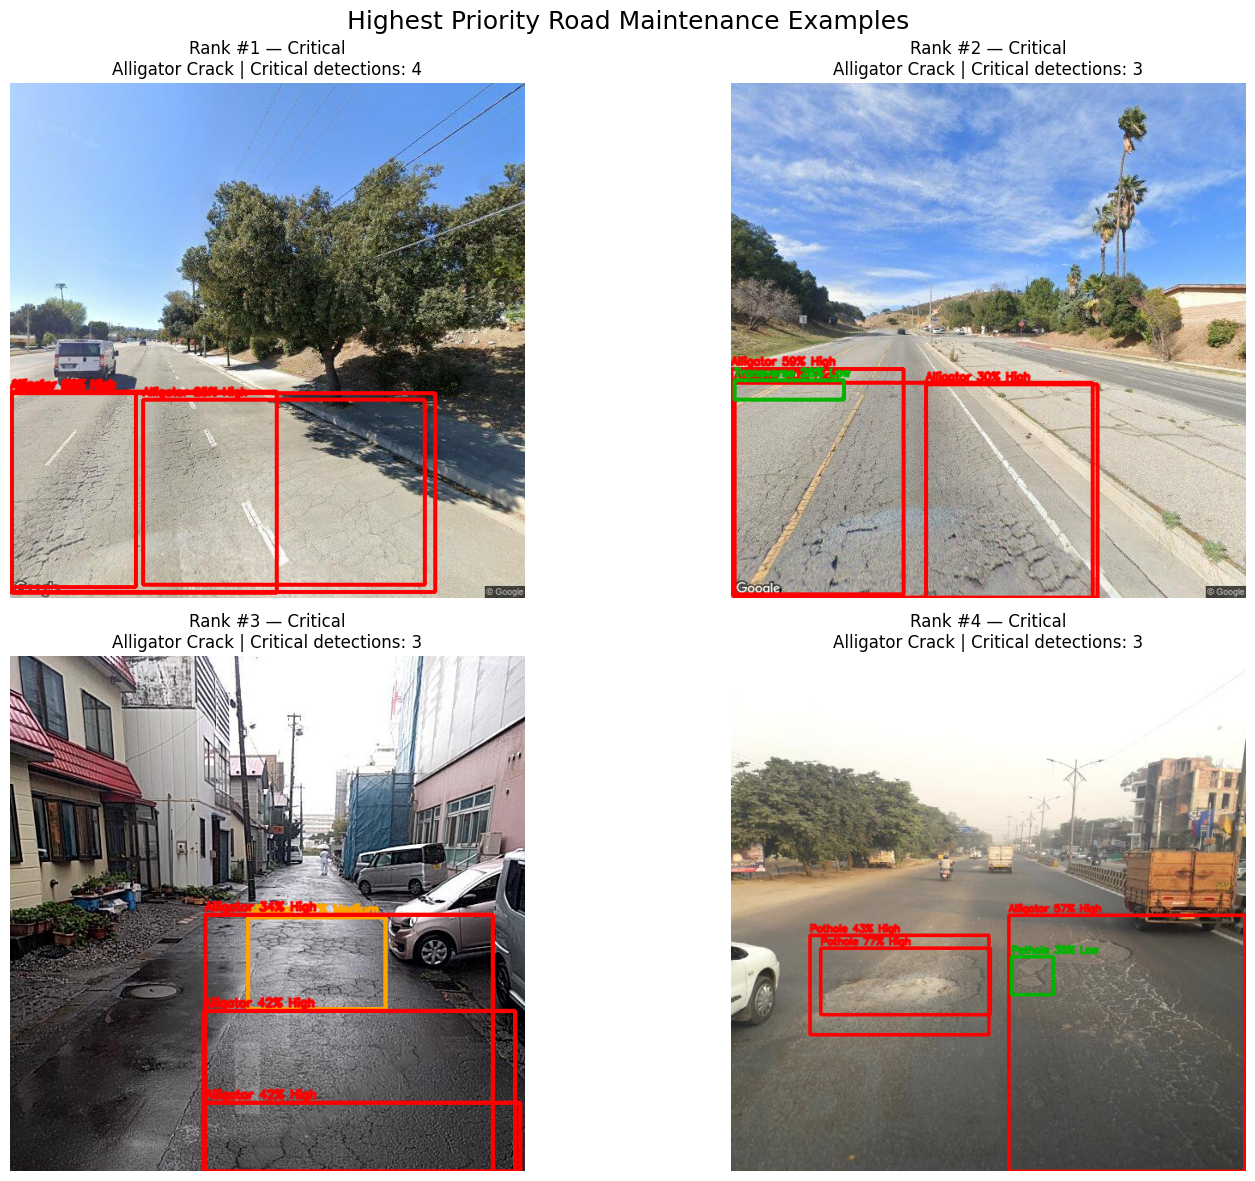


========== FINAL MAINTENANCE SUMMARY ==========
Model: YOLOv8n-SGD
Completed epochs: 40
Total test images: 2377
Total damage detections: 4257
Ranked images: 2012
Manual review images: 365

Image-level priority counts:
Critical: 548 images
Urgent: 567 images
Scheduled: 485 images
Routine: 412 images
Not Assessed: 365 images

Highest ranked image:
Image: United_States_001405.jpg
Priority: Critical
Damage type: Alligator Crack
Critical detections: 4

========== SAVED RANKING FILES ==========
Top_Priority_Images
classwise_severity_distribution.csv
damage_priority_distribution.csv
image_priority_distribution.csv
maintenance_summary.json
manual_review_images.csv
ranked_maintenance_report.csv
top10_maintenance_priorities.csv

Top priority annotated images: 4

Maintenance ranking completed!
All project implementation stages completed!
Ready for final project backup.


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
import json

from pathlib import Path

# ==========================================
# 1. Define Paths
# ==========================================

WORK_DIR = Path("/kaggle/working")

SEVERITY_DIR = (
    WORK_DIR /
    "Severity_Maintenance_Prioritization_40_Epochs"
)

REPORTS_DIR = SEVERITY_DIR / "Reports"
GRAPHS_DIR = SEVERITY_DIR / "Graphs"

RANKING_DIR = (
    SEVERITY_DIR / "Maintenance_Ranking"
)

RANKING_DIR.mkdir(parents=True, exist_ok=True)

TOP_IMAGES_DIR = (
    RANKING_DIR / "Top_Priority_Images"
)

TOP_IMAGES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ==========================================
# 2. Load Severity Assessment Reports
# ==========================================

damage_df = pd.read_csv(
    REPORTS_DIR / "damage_assessment_report.csv"
)

image_summary_df = pd.read_csv(
    REPORTS_DIR / "image_level_summary.csv"
)

assert len(damage_df) == 4257
assert len(image_summary_df) == 2377

print("========== INPUT VERIFICATION ==========")

print("Model: YOLOv8n-SGD")
print("Completed epochs: 40")
print("Total images:", len(image_summary_df))
print("Total detections:", len(damage_df))

# ==========================================
# 3. Separate Detected and Undetected Images
# ==========================================

ranked_df = image_summary_df[
    image_summary_df["Total Detections"] > 0
].copy()

manual_review_df = image_summary_df[
    image_summary_df["Total Detections"] == 0
].copy()

assert len(ranked_df) == 2012
assert len(manual_review_df) == 365

print("\nImages eligible for ranking:", len(ranked_df))

print(
    "Images requiring manual review:",
    len(manual_review_df)
)

# ==========================================
# 4. Generate Maintenance Ranking
# ==========================================

# Sort using:
# 1. Highest priority score
# 2. Critical damage count
# 3. High severity count
# 4. Total detections
# 5. Highest priority damage area
# 6. Image name for deterministic ordering

ranked_df = ranked_df.sort_values(
    by=[
        "Priority Score",
        "Critical Damage Count",
        "High Severity Count",
        "Total Detections",
        "Highest Priority Area (%)",
        "Image Name"
    ],
    ascending=[
        False,
        False,
        False,
        False,
        False,
        True
    ]
).reset_index(drop=True)

ranked_df.insert(
    0,
    "Maintenance Rank",
    np.arange(1, len(ranked_df) + 1)
)

# Recommended actions
ACTION_RULES = {
    "Critical": (
        "Prompt on-site inspection and repair assessment"
    ),
    "Urgent": (
        "Prioritize inspection and maintenance planning"
    ),
    "Scheduled": (
        "Include in scheduled maintenance plan"
    ),
    "Routine": (
        "Routine inspection and monitoring"
    )
}

ranked_df["Recommended Action"] = (
    ranked_df["Highest Priority"]
    .map(ACTION_RULES)
)

assert ranked_df[
    "Recommended Action"
].notna().all()

ranked_df.to_csv(
    RANKING_DIR / "ranked_maintenance_report.csv",
    index=False
)

print("\n========== TOP 10 MAINTENANCE PRIORITIES ==========")

display(
    ranked_df[[
        "Maintenance Rank",
        "Image Name",
        "Highest Priority",
        "Highest Priority Damage Type",
        "Critical Damage Count",
        "High Severity Count",
        "Total Detections",
        "Highest Priority Area (%)"
    ]].head(10).round(2)
)

# ==========================================
# 5. Manual Review Report
# ==========================================

manual_review_df["Review Status"] = (
    "Manual inspection required"
)

manual_review_df["Review Reason"] = (
    "No damage detected above confidence 0.25; "
    "possible missed damage"
)

manual_review_df.to_csv(
    RANKING_DIR / "manual_review_images.csv",
    index=False
)

print("\nManual review report saved.")

# ==========================================
# 6. Image-Level Priority Distribution
# ==========================================

priority_order = [
    "Critical",
    "Urgent",
    "Scheduled",
    "Routine",
    "Not Assessed"
]

image_priority_df = (
    image_summary_df["Highest Priority"]
    .value_counts()
    .reindex(priority_order, fill_value=0)
    .rename_axis("Maintenance Priority")
    .reset_index(name="Images")
)

image_priority_df["Percentage (%)"] = (
    image_priority_df["Images"]
    / len(image_summary_df) * 100
)

assert image_priority_df["Images"].sum() == 2377

print("\n========== IMAGE-LEVEL PRIORITY ==========")

display(image_priority_df.round(2))

image_priority_df.to_csv(
    RANKING_DIR / "image_priority_distribution.csv",
    index=False
)

# ==========================================
# 7. Damage-Level Priority Distribution
# ==========================================

damage_priority_df = (
    damage_df["Maintenance Priority"]
    .value_counts()
    .reindex(
        ["Critical", "Urgent", "Scheduled", "Routine"],
        fill_value=0
    )
    .rename_axis("Maintenance Priority")
    .reset_index(name="Detections")
)

damage_priority_df["Percentage (%)"] = (
    damage_priority_df["Detections"]
    / len(damage_df) * 100
)

assert damage_priority_df["Detections"].sum() == 4257

print("\n========== DAMAGE-LEVEL PRIORITY ==========")

display(damage_priority_df.round(2))

damage_priority_df.to_csv(
    RANKING_DIR / "damage_priority_distribution.csv",
    index=False
)

# ==========================================
# 8. Class-wise Severity Distribution
# ==========================================

class_order = [
    "Longitudinal Crack",
    "Transverse Crack",
    "Alligator Crack",
    "Pothole"
]

classwise_severity_df = pd.crosstab(
    damage_df["Damage Type"],
    damage_df["Severity"]
).reindex(
    index=class_order,
    columns=["Low", "Medium", "High"],
    fill_value=0
)

classwise_severity_df["Total"] = (
    classwise_severity_df.sum(axis=1)
)

assert classwise_severity_df["Total"].sum() == 4257

print("\n========== CLASS-WISE SEVERITY ==========")

display(classwise_severity_df)

classwise_severity_df.to_csv(
    RANKING_DIR / "classwise_severity_distribution.csv"
)

# ==========================================
# 9. Save Top 10 Maintenance Priorities
# ==========================================

top10_df = ranked_df.head(10).copy()

top10_df.to_csv(
    RANKING_DIR / "top10_maintenance_priorities.csv",
    index=False
)

# ==========================================
# 10. Image Priority Distribution Graph
# ==========================================

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    image_priority_df["Maintenance Priority"],
    image_priority_df["Images"],
    color=[
        "#DC2626",
        "#F59E0B",
        "#2563EB",
        "#16A34A",
        "#94A3B8"
    ]
)

ax.bar_label(
    bars,
    padding=4,
    fontsize=11
)

ax.set_title(
    "Image-Level Maintenance Priority Distribution"
)

ax.set_ylabel("Number of Images")

ax.set_ylim(
    0,
    image_priority_df["Images"].max() * 1.2
)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    GRAPHS_DIR / "image_priority_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 11. Class-wise Severity Graph
# ==========================================

ax = classwise_severity_df[
    ["Low", "Medium", "High"]
].plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7),
    color=[
        "#22C55E",
        "#F59E0B",
        "#EF4444"
    ]
)

for container in ax.containers:

    ax.bar_label(
        container,
        label_type="center",
        fontsize=10
    )

ax.set_title(
    "Class-wise Road Damage Severity Distribution"
)

ax.set_ylabel("Number of Detections")
ax.set_xlabel("Damage Type")
ax.tick_params(axis="x", rotation=10)
ax.legend(title="Severity")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    GRAPHS_DIR /
    "classwise_severity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 12. Top 10 Maintenance Ranking Graph
# ==========================================

plot_df = top10_df.iloc[::-1]

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    [
        f"#{rank} {name}"
        for rank, name in zip(
            plot_df["Maintenance Rank"],
            plot_df["Image Name"]
        )
    ],
    plot_df["Critical Damage Count"],
    color="#DC2626"
)

ax.bar_label(
    bars,
    padding=4
)

ax.set_xlabel("Number of Critical Detections")

ax.set_title(
    "Top 10 Ranked Maintenance Images"
)

ax.set_xlim(
    0,
    max(1, plot_df["Critical Damage Count"].max()) * 1.25
)

ax.grid(axis="x", alpha=0.25)

plt.tight_layout()

plt.savefig(
    GRAPHS_DIR / "top10_maintenance_priority.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 13. Annotate Top 4 Priority Images
# ==========================================

SEVERITY_COLORS = {
    "Low": (0, 180, 0),
    "Medium": (0, 165, 255),
    "High": (0, 0, 255)
}

SHORT_NAMES = {
    "Longitudinal Crack": "Longitudinal",
    "Transverse Crack": "Transverse",
    "Alligator Crack": "Alligator",
    "Pothole": "Pothole"
}

fig, axes = plt.subplots(
    2, 2, figsize=(16, 12)
)

saved_top_images = []

for ax, (_, row) in zip(
    axes.flatten(),
    ranked_df.head(4).iterrows()
):

    image_path = Path(row["Image Path"])

    image = cv2.imread(str(image_path))

    assert image is not None, (
        f"Could not read {image_path}"
    )

    detections = damage_df[
        damage_df["Image Name"] == row["Image Name"]
    ]

    # Draw all detections in each selected image
    for _, detection in detections.iterrows():

        x1, y1, x2, y2 = [
            int(detection[column])
            for column in ["X1", "Y1", "X2", "Y2"]
        ]

        color = SEVERITY_COLORS[
            detection["Severity"]
        ]

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            color,
            3
        )

        label = (
            f"{SHORT_NAMES[detection['Damage Type']]} "
            f"{detection['Confidence (%)']:.0f}% "
            f"{detection['Severity']}"
        )

        cv2.putText(
            image,
            label,
            (max(0, x1), max(20, y1 - 5)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,
            color,
            2,
            cv2.LINE_AA
        )

    rank = int(row["Maintenance Rank"])

    output_path = (
        TOP_IMAGES_DIR /
        f"rank_{rank}_{image_path.name}"
    )

    assert cv2.imwrite(
        str(output_path),
        image
    )

    saved_top_images.append(str(output_path))

    ax.imshow(
        cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )
    )

    ax.set_title(
        f"Rank #{rank} — {row['Highest Priority']}\n"
        f"{row['Highest Priority Damage Type']} | "
        f"Critical detections: "
        f"{row['Critical Damage Count']}"
    )

    ax.axis("off")

fig.suptitle(
    "Highest Priority Road Maintenance Examples",
    fontsize=18
)

plt.tight_layout()

plt.savefig(
    GRAPHS_DIR /
    "top4_maintenance_visualization.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 14. Generate Final Maintenance Summary
# ==========================================

maintenance_summary = {
    "model": "YOLOv8n-SGD",
    "completed_epochs": 40,
    "total_test_images": 2377,
    "total_detected_damages": 4257,
    "ranked_images": len(ranked_df),
    "manual_review_images": len(manual_review_df),
    "image_priority_distribution": {
        row["Maintenance Priority"]: int(row["Images"])
        for _, row in image_priority_df.iterrows()
    },
    "damage_priority_distribution": {
        row["Maintenance Priority"]: int(row["Detections"])
        for _, row in damage_priority_df.iterrows()
    },
    "top_ranked_image": str(
        ranked_df.iloc[0]["Image Name"]
    ),
    "top_ranked_priority": str(
        ranked_df.iloc[0]["Highest Priority"]
    ),
    "top_ranked_damage_type": str(
        ranked_df.iloc[0]["Highest Priority Damage Type"]
    ),
    "top_ranked_critical_detections": int(
        ranked_df.iloc[0]["Critical Damage Count"]
    ),
    "top_ranked_images_saved": len(saved_top_images),
    "ranking_method": (
        "Priority score, critical damage count, "
        "high severity count, total detections, "
        "highest priority bounding box area"
    ),
    "limitations": [
        "Image-level ranking, not GPS road-segment ranking.",
        "Severity thresholds are heuristic.",
        "Predicted damage instances may include false positives.",
        "Images without detections require manual review.",
        "Maintenance decisions require physical verification."
    ]
}

with open(
    RANKING_DIR / "maintenance_summary.json",
    "w"
) as f:

    json.dump(
        maintenance_summary,
        f,
        indent=4
    )

# ==========================================
# 15. Final Verification
# ==========================================

assert (
    len(ranked_df) + len(manual_review_df)
    == 2377
)

assert ranked_df[
    "Maintenance Rank"
].tolist() == list(
    range(1, 2013)
)

print("\n========== FINAL MAINTENANCE SUMMARY ==========")

print("Model: YOLOv8n-SGD")
print("Completed epochs: 40")
print("Total test images: 2377")
print("Total damage detections: 4257")
print("Ranked images:", len(ranked_df))
print("Manual review images:", len(manual_review_df))

print("\nImage-level priority counts:")

for _, row in image_priority_df.iterrows():

    print(
        f"{row['Maintenance Priority']}: "
        f"{row['Images']} images"
    )

print("\nHighest ranked image:")

print(
    "Image:",
    maintenance_summary["top_ranked_image"]
)

print(
    "Priority:",
    maintenance_summary["top_ranked_priority"]
)

print(
    "Damage type:",
    maintenance_summary["top_ranked_damage_type"]
)

print(
    "Critical detections:",
    maintenance_summary[
        "top_ranked_critical_detections"
    ]
)

print("\n========== SAVED RANKING FILES ==========")

for path in sorted(RANKING_DIR.iterdir()):
    print(path.name)

print("\nTop priority annotated images:", len(saved_top_images))

print("\nMaintenance ranking completed!")
print("All project implementation stages completed!")
print("Ready for final project backup.")

In [25]:
import shutil
import zipfile
import json
import hashlib
import pandas as pd

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import FileLink, display
import os

# ==========================================
# 1. Define Final Project Paths
# ==========================================

WORK_DIR = Path("/kaggle/working")

FINAL_PROJECT_DIR = (
    WORK_DIR / "Campus_Road_AI_Final_40_Epochs"
)

FINAL_PROJECT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FINAL_ZIP_PATH = (
    WORK_DIR / "Campus_Road_AI_Final_40_Epochs.zip"
)

print("========== FINAL PROJECT BACKUP ==========")

print("Project folder:", FINAL_PROJECT_DIR)

# ==========================================
# 2. Define All Source Directories
# ==========================================

source_directories = {
    "01_SGD_Training": (
        WORK_DIR /
        "YOLO_Experiments/baseline_yolov8n_sgd-2"
    ),

    "02_AdamW_Training": (
        WORK_DIR /
        "YOLO_Experiments/optimizer_yolov8n_adamw"
    ),

    "03_Optimizer_Comparison": (
        WORK_DIR /
        "Optimizer_Comparison_40_Epochs"
    ),

    "04_Validation_Evaluation": (
        WORK_DIR /
        "Validation_Evaluation_40_Epochs"
    ),

    "05_Final_Test_Evaluation": (
        WORK_DIR /
        "Final_Test_Evaluation_40_Epochs"
    ),

    "06_Detection_Accuracy": (
        WORK_DIR /
        "Detection_Accuracy_40_Epochs"
    ),

    "07_Generalization_Analysis": (
        WORK_DIR /
        "Model_Generalization_40_Epochs"
    ),

    "08_Severity_Maintenance_Prioritization": (
        WORK_DIR /
        "Severity_Maintenance_Prioritization_40_Epochs"
    )
}

# ==========================================
# 3. Verify All Source Directories
# ==========================================

print("\n========== SOURCE VERIFICATION ==========")

for name, source in source_directories.items():

    assert source.exists(), (
        f"Missing source directory: {source}"
    )

    file_count = sum(
        1 for p in source.rglob("*")
        if p.is_file()
    )

    assert file_count > 0

    print(f"{name}: FOUND ({file_count} files)")

# ==========================================
# 4. Copy All Project Outputs
# ==========================================

print("\n========== COPYING PROJECT OUTPUTS ==========")

for name, source in source_directories.items():

    destination = FINAL_PROJECT_DIR / name

    shutil.copytree(
        source,
        destination,
        dirs_exist_ok=True
    )

    print(f"{name}: COPIED")

# ==========================================
# 5. Export Final Selected Model
# ==========================================

FINAL_MODEL_DIR = (
    FINAL_PROJECT_DIR / "09_Final_Model"
)

FINAL_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

SELECTED_MODEL_SOURCE = (
    WORK_DIR /
    "Validation_Evaluation_40_Epochs/"
    "Selected_Model/best_model.pt"
)

SELECTION_SOURCE = (
    WORK_DIR /
    "Validation_Evaluation_40_Epochs/"
    "Selected_Model/model_selection.json"
)

assert SELECTED_MODEL_SOURCE.exists()
assert SELECTION_SOURCE.exists()

shutil.copy2(
    SELECTED_MODEL_SOURCE,
    FINAL_MODEL_DIR / "best_model.pt"
)

shutil.copy2(
    SELECTION_SOURCE,
    FINAL_MODEL_DIR / "model_selection.json"
)

# Verify identical model weights
def sha256_file(path):

    sha = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            sha.update(chunk)

    return sha.hexdigest()


source_hash = sha256_file(
    SELECTED_MODEL_SOURCE
)

final_hash = sha256_file(
    FINAL_MODEL_DIR / "best_model.pt"
)

assert source_hash == final_hash

print("\nFinal selected model copied.")
print("Model checksum verification: PASSED")

# ==========================================
# 6. Save Dataset Configuration
# ==========================================

CONFIG_DIR = (
    FINAL_PROJECT_DIR / "10_Configuration"
)

CONFIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

config_files = [
    "data.yaml",
    "evaluation_data_40.yaml",
    "test_data_40.yaml",
    "validation_images_40.txt"
]

for filename in config_files:

    source = WORK_DIR / filename

    assert source.exists(), (
        f"Missing configuration: {filename}"
    )

    shutil.copy2(
        source,
        CONFIG_DIR / filename
    )

    print(f"{filename}: COPIED")

# ==========================================
# 7. Load All Final Summary Reports
# ==========================================

with open(SELECTION_SOURCE, "r") as f:

    selection_summary = json.load(f)

with open(
    WORK_DIR /
    "Final_Test_Evaluation_40_Epochs/"
    "test_summary.json",
    "r"
) as f:

    test_summary = json.load(f)

with open(
    WORK_DIR /
    "Model_Generalization_40_Epochs/"
    "generalization_analysis.json",
    "r"
) as f:

    generalization_summary = json.load(f)

with open(
    WORK_DIR /
    "Severity_Maintenance_Prioritization_40_Epochs/"
    "Reports/processing_summary.json",
    "r"
) as f:

    severity_summary = json.load(f)

with open(
    WORK_DIR /
    "Severity_Maintenance_Prioritization_40_Epochs/"
    "Maintenance_Ranking/maintenance_summary.json",
    "r"
) as f:

    maintenance_summary = json.load(f)

accuracy_df = pd.read_csv(
    WORK_DIR /
    "Detection_Accuracy_40_Epochs/"
    "overall_detection_accuracy.csv"
)

# ==========================================
# 8. Create Final Project Summary
# ==========================================

SUMMARY_DIR = (
    FINAL_PROJECT_DIR / "11_Final_Summary"
)

SUMMARY_DIR.mkdir(
    parents=True,
    exist_ok=True
)

final_summary = {
    "project_title": (
        "Campus Road Damage Detection and "
        "Severity-Aware Maintenance Prioritization"
    ),

    "dataset": "RDD2022 Preprocessed",

    "model": selection_summary["selected_model"],

    "completed_epochs_per_optimizer": 40,

    "optimizers_compared": ["SGD", "AdamW"],

    "initial_learning_rates": {
        "SGD": 0.01,
        "AdamW": 0.001
    },

    "training_images": 16636,

    "validation_images": 4752,

    "test_images": 2377,

    "excluded_validation_image": (
        "China_Drone_001007.jpg"
    ),

    "validation_results": selection_summary,

    "test_results": test_summary,

    "detection_accuracy": (
        accuracy_df.to_dict(orient="records")
    ),

    "generalization_analysis": (
        generalization_summary
    ),

    "severity_assessment": severity_summary,

    "maintenance_ranking": maintenance_summary,

    "final_model_sha256": final_hash,

    "backup_created_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

with open(
    SUMMARY_DIR / "final_project_summary.json",
    "w"
) as f:

    json.dump(final_summary, f, indent=4)

# ==========================================
# 9. Create Final Metrics CSV
# ==========================================

final_metrics_rows = [
    {
        "Metric": "Selected Model",
        "Value": selection_summary["selected_model"]
    },
    {
        "Metric": "Completed Epochs",
        "Value": 40
    },
    {
        "Metric": "Training Images",
        "Value": 16636
    },
    {
        "Metric": "Validation Images",
        "Value": 4752
    },
    {
        "Metric": "Test Images",
        "Value": 2377
    },
    {
        "Metric": "Validation Precision (%)",
        "Value": selection_summary["precision"]
    },
    {
        "Metric": "Validation Recall (%)",
        "Value": selection_summary["recall"]
    },
    {
        "Metric": "Validation mAP50 (%)",
        "Value": selection_summary["mAP50"]
    },
    {
        "Metric": "Validation mAP50-95 (%)",
        "Value": selection_summary["mAP50-95"]
    },
    {
        "Metric": "Test Precision (%)",
        "Value": test_summary["Precision (%)"]
    },
    {
        "Metric": "Test Recall (%)",
        "Value": test_summary["Recall (%)"]
    },
    {
        "Metric": "Test mAP50 (%)",
        "Value": test_summary["mAP50 (%)"]
    },
    {
        "Metric": "Test mAP50-95 (%)",
        "Value": test_summary["mAP50-95 (%)"]
    },
    {
        "Metric": "Training Detection Accuracy (%)",
        "Value": generalization_summary[
            "training_accuracy"
        ]
    },
    {
        "Metric": "Validation Detection Accuracy (%)",
        "Value": generalization_summary[
            "validation_accuracy"
        ]
    },
    {
        "Metric": "Test Detection Accuracy (%)",
        "Value": generalization_summary[
            "test_accuracy"
        ]
    },
    {
        "Metric": "Train-Validation Gap (pp)",
        "Value": generalization_summary[
            "train_validation_gap_pp"
        ]
    },
    {
        "Metric": "Total Test Detections",
        "Value": 4257
    },
    {
        "Metric": "Ranked Images",
        "Value": 2012
    },
    {
        "Metric": "Manual Review Images",
        "Value": 365
    },
    {
        "Metric": "Critical Priority Images",
        "Value": 548
    },
    {
        "Metric": "Urgent Priority Images",
        "Value": 567
    },
    {
        "Metric": "Scheduled Priority Images",
        "Value": 485
    },
    {
        "Metric": "Routine Priority Images",
        "Value": 412
    }
]

final_metrics_df = pd.DataFrame(
    final_metrics_rows
)

final_metrics_df.to_csv(
    SUMMARY_DIR / "final_project_metrics.csv",
    index=False
)

print("\n========== FINAL PROJECT METRICS ==========")

display(final_metrics_df)

# ==========================================
# 10. Create Project README
# ==========================================

readme = """# Campus Road Damage Detection and
# Severity-Aware Maintenance Prioritization

## Project Overview

This project implements a YOLOv8n-based road damage
detection system with image-based severity estimation
and maintenance prioritization.

## Dataset

RDD2022 Preprocessed

- Training images: 16,636
- Validation images: 4,752 usable images
- Test images: 2,377
- Total usable images: 23,765
- One corrupt validation image was excluded.

Damage classes:

1. Longitudinal Crack
2. Transverse Crack
3. Alligator Crack
4. Pothole

## Training Methodology

Two YOLOv8n models were trained for 40 completed
epochs using the same dataset and training budget.

- SGD: Initial learning rate 0.01
- AdamW: Initial learning rate 0.001
- Image size: 640
- Training batch size: 32
- Hardware: 2 NVIDIA Tesla T4 GPUs
- Ultralytics: 8.4.211

Training was initially completed for 16 epochs,
then resumed using saved optimizer checkpoints.
Both runs were stopped after 40 completed epochs
under the original 50-epoch learning rate schedule.

This is a comparison of optimizer configurations,
because their initial learning rates differ.

## Final Model Selection

Selected model: YOLOv8n-SGD

Selection criterion: Fresh validation mAP50-95.

SGD and AdamW achieved nearly identical validation
performance. SGD was selected because its validation
mAP50-95 was marginally higher.

## Final Validation Results

- Precision: 60.84%
- Recall: 50.08%
- mAP50: 53.98%
- mAP50-95: 26.75%

## Final Test Results

- Precision: 60.94%
- Recall: 50.72%
- mAP50: 53.98%
- mAP50-95: 26.99%

## Detection Accuracy

Detection accuracy = TP / (TP + FP + FN).

This is a custom object detection metric, not
conventional classification accuracy.

Settings:

- Confidence threshold: 0.25
- Matching IoU: 0.50
- NMS IoU: 0.70
- One-to-one class-aware bounding box matching

Results:

- Training accuracy: 43.23%
- Validation accuracy: 37.67%
- Test accuracy: 38.22%
- Train-validation gap: 5.56 percentage points

## Generalization Analysis

Training and validation losses decreased across
40 epochs. Validation mAP50-95 improved during
the final 10 epochs.

No strong evidence of severe overfitting was observed.
Further learning and model improvement remain possible.

## Severity Assessment

Severity is estimated using class-specific normalized
bounding box area thresholds.

- Low severity: 2,009 detections
- Medium severity: 997 detections
- High severity: 1,251 detections

Total predicted detections: 4,257.

## Maintenance Prioritization

Image-level priority distribution:

- Critical: 548 images
- Urgent: 567 images
- Scheduled: 485 images
- Routine: 412 images
- Not assessed: 365 images

Total ranked images: 2,012.

Images without detections are flagged for manual
inspection rather than declared damage-free.

## Final Model File

09_Final_Model/best_model.pt

This checkpoint can be used for inference and
future demonstration application development.

## Limitations

- Severity thresholds are heuristic, not validated
  civil engineering severity measurements.
- Bounding box area does not represent actual crack
  surface area, pothole depth or physical dimensions.
- The ranking represents individual images rather
  than GPS-identified physical road segments.
- Predicted detections may contain false positives
  and missed damage instances.
- Maintenance decisions require physical inspection.
- The test dataset was also evaluated during the
  earlier 16-epoch development stage. Therefore,
  it was not completely untouched throughout
  iterative project development.
- Results are based on RDD2022, not a separate
  independently validated campus road dataset.

## Reproducibility

The archive contains model checkpoints, training
histories, evaluation configurations, reports and
visualizations.

Dataset configuration files contain Kaggle-specific
paths and must be updated when running locally.

The original dataset and Kaggle notebook source
are not included in this archive. Download the
notebook separately and retain the dataset source.

## Project Status

AI/ML implementation, model evaluation, severity
assessment and maintenance ranking are completed.

An interactive live demonstration application
can be developed using the exported final model.
"""

(
    FINAL_PROJECT_DIR / "README.md"
).write_text(
    readme,
    encoding="utf-8"
)

print("\nProject README created.")

# ==========================================
# 11. Verify Essential Files
# ==========================================

required_files = [
    "README.md",

    "01_SGD_Training/results.csv",
    "01_SGD_Training/weights/best.pt",
    "01_SGD_Training/weights/last.pt",

    "02_AdamW_Training/results.csv",
    "02_AdamW_Training/weights/best.pt",
    "02_AdamW_Training/weights/last.pt",

    "03_Optimizer_Comparison/optimizer_comparison.csv",
    "03_Optimizer_Comparison/learning_curves.png",

    "04_Validation_Evaluation/validation_comparison.csv",

    "05_Final_Test_Evaluation/Selected_Model_Test/"
    "test_overall_metrics.csv",

    "05_Final_Test_Evaluation/Selected_Model_Test/"
    "test_classwise_metrics.csv",

    "06_Detection_Accuracy/overall_detection_accuracy.csv",
    "06_Detection_Accuracy/classwise_detection_accuracy.csv",
    "06_Detection_Accuracy/test_predictions.csv",

    "07_Generalization_Analysis/generalization_analysis.json",
    "07_Generalization_Analysis/train_vs_validation_loss.png",

    "08_Severity_Maintenance_Prioritization/"
    "Reports/damage_assessment_report.csv",

    "08_Severity_Maintenance_Prioritization/"
    "Reports/image_level_summary.csv",

    "08_Severity_Maintenance_Prioritization/"
    "Maintenance_Ranking/ranked_maintenance_report.csv",

    "08_Severity_Maintenance_Prioritization/"
    "Maintenance_Ranking/manual_review_images.csv",

    "09_Final_Model/best_model.pt",
    "09_Final_Model/model_selection.json",

    "10_Configuration/data.yaml",

    "11_Final_Summary/final_project_summary.json",
    "11_Final_Summary/final_project_metrics.csv"
]

print("\n========== ESSENTIAL FILE VERIFICATION ==========")

for filename in required_files:

    path = FINAL_PROJECT_DIR / filename

    assert path.exists(), (
        f"Missing essential file: {filename}"
    )

    assert path.stat().st_size > 0

    print(f"VERIFIED: {filename}")

# ==========================================
# 12. Create Final ZIP Archive
# ==========================================

print("\n========== CREATING FINAL ZIP ==========")

zip_output = shutil.make_archive(
    base_name=str(FINAL_ZIP_PATH.with_suffix("")),
    format="zip",
    root_dir=FINAL_PROJECT_DIR
)

assert Path(zip_output).exists()

zip_size_mb = (
    FINAL_ZIP_PATH.stat().st_size / (1024**2)
)

print("ZIP created:", FINAL_ZIP_PATH)

print(f"ZIP size: {zip_size_mb:.2f} MB")

# ==========================================
# 13. Verify ZIP Integrity
# ==========================================

print("\n========== ZIP INTEGRITY CHECK ==========")

with zipfile.ZipFile(
    FINAL_ZIP_PATH, "r"
) as archive:

    corrupted_file = archive.testzip()

    assert corrupted_file is None, (
        f"Corrupt archive member: {corrupted_file}"
    )

    archive_files = set(
        archive.namelist()
    )

    for filename in required_files:

        assert filename in archive_files, (
            f"Missing from ZIP: {filename}"
        )

    total_archive_files = sum(
        not info.is_dir()
        for info in archive.infolist()
    )

print("ZIP integrity: PASSED")

print(
    "Essential files inside ZIP:",
    len(required_files)
)

print(
    "Total archived files:",
    total_archive_files
)

# ==========================================
# 14. Final Project Summary
# ==========================================

print("\n" + "=" * 60)

print("CAMPUS ROAD AI — FINAL PROJECT COMPLETED")

print("=" * 60)

print("Final model: YOLOv8n-SGD")

print("SGD completed epochs: 40")
print("AdamW completed epochs: 40")

print("Test mAP50: 53.98%")
print("Test mAP50-95: 26.99%")

print("Training accuracy: 43.23%")
print("Validation accuracy: 37.67%")
print("Test accuracy: 38.22%")

print("Total damage detections: 4257")
print("Ranked maintenance images: 2012")
print("Manual review images: 365")

print("\nFinal ZIP:", FINAL_ZIP_PATH)

print(f"Final ZIP size: {zip_size_mb:.2f} MB")

print("\nAll essential project outputs verified!")

# ==========================================
# 15. Download Link
# ==========================================

os.chdir("/kaggle/working")

display(
    FileLink(
        "Campus_Road_AI_Final_40_Epochs.zip"
    )
)

========== FINAL PROJECT BACKUP ==========
Project folder: /kaggle/working/Campus_Road_AI_Final_40_Epochs

========== SOURCE VERIFICATION ==========
01_SGD_Training: FOUND (19 files)
02_AdamW_Training: FOUND (20 files)
03_Optimizer_Comparison: FOUND (6 files)
04_Validation_Evaluation: FOUND (34 files)
05_Final_Test_Evaluation: FOUND (19 files)
06_Detection_Accuracy: FOUND (7 files)
07_Generalization_Analysis: FOUND (7 files)
08_Severity_Maintenance_Prioritization: FOUND (42 files)

========== COPYING PROJECT OUTPUTS ==========
01_SGD_Training: COPIED
02_AdamW_Training: COPIED
03_Optimizer_Comparison: COPIED
04_Validation_Evaluation: COPIED
05_Final_Test_Evaluation: COPIED
06_Detection_Accuracy: COPIED
07_Generalization_Analysis: COPIED
08_Severity_Maintenance_Prioritization: COPIED

Final selected model copied.
Model checksum verification: PASSED
data.yaml: COPIED
evaluation_data_40.yaml: COPIED
test_data_40.yaml: COPIED
validation_images_40.txt: COPIED

========== FINAL PROJECT METRIC

,Metric,Value
0,Selected Model,YOLOv8n-SGD
1,Completed Epochs,40
2,Training Images,16636
3,Validation Images,4752
4,Test Images,2377
5,Validation Precision (%),60.84246
6,Validation Recall (%),50.080799
7,Validation mAP50 (%),53.98326
8,Validation mAP50-95 (%),26.753018
9,Test Precision (%),60.942338



Project README created.

========== ESSENTIAL FILE VERIFICATION ==========
VERIFIED: README.md
VERIFIED: 01_SGD_Training/results.csv
VERIFIED: 01_SGD_Training/weights/best.pt
VERIFIED: 01_SGD_Training/weights/last.pt
VERIFIED: 02_AdamW_Training/results.csv
VERIFIED: 02_AdamW_Training/weights/best.pt
VERIFIED: 02_AdamW_Training/weights/last.pt
VERIFIED: 03_Optimizer_Comparison/optimizer_comparison.csv
VERIFIED: 03_Optimizer_Comparison/learning_curves.png
VERIFIED: 04_Validation_Evaluation/validation_comparison.csv
VERIFIED: 05_Final_Test_Evaluation/Selected_Model_Test/test_overall_metrics.csv
VERIFIED: 05_Final_Test_Evaluation/Selected_Model_Test/test_classwise_metrics.csv
VERIFIED: 06_Detection_Accuracy/overall_detection_accuracy.csv
VERIFIED: 06_Detection_Accuracy/classwise_detection_accuracy.csv
VERIFIED: 06_Detection_Accuracy/test_predictions.csv
VERIFIED: 07_Generalization_Analysis/generalization_analysis.json
VERIFIED: 07_Generalization_Analysis/train_vs_validation_loss.png
VERIF

/kaggle/working/Campus_Road_AI_Final_40_Epochs.zip